# Day 17 — Statistical Validation of Temporal Degradation

Quantify uncertainty and decompose the observed temporal performance differences.

In [ ]:
# Imports
import json
from pathlib import Path

In [ ]:
# Project paths
def find_project_root():
    current = Path.cwd().resolve()
    for path in [current, *current.parents]:
        if (path / "README.md").exists():
            return path
    raise RuntimeError(
        "Project root not found. Run this notebook from inside the repository."
    )

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"

def resolve_artifact_paths(value):
    """Rebase legacy project paths in loaded metadata; never rewrite artifacts.

    Keep all non-path values, model identifiers, and scientific settings intact.
    Support the original project name and the public repository name.
    """
    if isinstance(value, dict):
        return {key: resolve_artifact_paths(item) for key, item in value.items()}
    if isinstance(value, list):
        return [resolve_artifact_paths(item) for item in value]
    if isinstance(value, str):
        normalized = value.replace("\\", "/")
        for name in ("FinGPT_Project", "FinGPT-Temporal-Generalization"):
            marker = "/" + name + "/"
            if marker in normalized and "\n" not in normalized:
                # Only standalone filesystem references, never prose containing a path.
                prefix, relative = normalized.split(marker, 1)
                if prefix.startswith("/") or (len(prefix) > 1 and prefix[1] == ":"):
                    if not any(char.isspace() for char in relative):
                        return str(PROJECT_ROOT / relative)
    return value

def load_artifact_json(stream, *args, **kwargs):
    return resolve_artifact_paths(json.load(stream, *args, **kwargs))


In [ ]:
# Reproducibility settings
# Original seeds and deterministic settings remain at their original workflow
# positions below, including stage-specific RNG resets. No new seed is introduced.

**Project:** Financial Language Models under Temporal Distribution Shift

## Objective

Diagnose the non-monotonic future performance observed in Day 16 across strictly future windows F1–F6, while preserving the frozen chronological benchmark and frozen historical model.

Day 17 is a **diagnostic decomposition** stage:

- no retraining,
- no new model selection,
- no prompt modification,
- no threshold tuning,
- no relabeling,
- no future-window redefinition,
- no smoothing of the temporal curve.

The main diagnostic layers are:

1. uncertainty around the temporal performance curve,
2. class-level performance decomposition,
3. transition-level error diagnosis,
4. true-label and prediction-composition shifts,
5. source-composition and source-conditional performance,
6. descriptive source-standardization sensitivity,
7. integrated diagnosis of the F3/F4 dip and F5 recovery.

The RNA-seq-style structural robustness curve remains a separate later branch.

In [ ]:
# Initialize analysis paths



from pathlib import Path

# Project root

# PROJECT_ROOT is discovered in the project-path setup cell.

# Day 16 frozen evidence layer
DAY16_DIR = PROJECT_ROOT / "results" / "day16"

# Day 17 output directory
DAY17_DIR = PROJECT_ROOT / "results" / "day17"
DAY17_DIR.mkdir(parents=True, exist_ok=True)

# Figure directory
FIGURE_DIR = DAY17_DIR / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Notebook directory
NOTEBOOK_DIR = PROJECT_ROOT / "notebooks"
NOTEBOOK_DIR.mkdir(parents=True, exist_ok=True)

# Expected final notebook path
DAY17_NOTEBOOK_PATH = (
    NOTEBOOK_DIR / "day17_temporal_performance_diagnosis.ipynb"
)

print("=" * 90)
print("DAY 17 — DRIVE / PATH INITIALIZATION")
print("=" * 90)

print(f"Project root : {PROJECT_ROOT}")
print(f"Day 16 input : {DAY16_DIR}")
print(f"Day 17 output: {DAY17_DIR}")
print(f"Figures      : {FIGURE_DIR}")
print(f"Notebook dir : {NOTEBOOK_DIR}")
print(f"Final notebook path:")
print(DAY17_NOTEBOOK_PATH)

print("-" * 90)

checks = {
    "project_root_exists": PROJECT_ROOT.exists(),
    "day16_dir_exists": DAY16_DIR.exists(),
    "day17_dir_exists": DAY17_DIR.exists(),
    "figure_dir_exists": FIGURE_DIR.exists(),
    "notebook_dir_exists": NOTEBOOK_DIR.exists(),
}

for name, status in checks.items():
    print(f"{'PASS' if status else 'FAIL':4s} — {name}")

print("-" * 90)

if not checks["project_root_exists"]:
    raise FileNotFoundError(
        f"Project root not found: {PROJECT_ROOT}"
    )

if not checks["day16_dir_exists"]:
    raise FileNotFoundError(
        f"Day 16 results directory not found: {DAY16_DIR}"
    )

print("Day 17 path initialization: PASS")
print("=" * 90)

Mounted at /content/drive
DAY 17 — DRIVE / PATH INITIALIZATION
Project root : /content/drive/MyDrive/FinGPT_Project
Day 16 input : /content/drive/MyDrive/FinGPT_Project/results/day16
Day 17 output: /content/drive/MyDrive/FinGPT_Project/results/day17
Figures      : /content/drive/MyDrive/FinGPT_Project/results/day17/figures
Notebook dir : /content/drive/MyDrive/FinGPT_Project/notebooks
Final notebook path:
/content/drive/MyDrive/FinGPT_Project/notebooks/day17_temporal_performance_diagnosis.ipynb
------------------------------------------------------------------------------------------
PASS — project_root_exists
PASS — day16_dir_exists
PASS — day17_dir_exists
PASS — figure_dir_exists
PASS — notebook_dir_exists
------------------------------------------------------------------------------------------
Day 17 path initialization: PASS


In [ ]:
# Frozen Day 16 artifact inventory
from pathlib import Path

REQUIRED_DAY16_ARTIFACTS = [
    "future_predictions.csv",
    "future_window_metrics.csv",
    "future_class_performance.csv",
    "future_confusion_matrices.csv",
    "future_error_transitions.csv",
    "future_prediction_distribution.csv",
    "future_source_composition.csv",
    "temporal_performance_curve.csv",
    "day16_summary.json",
]

print("=" * 100)
print("DAY 17 — FROZEN DAY 16 ARTIFACT INVENTORY")
print("=" * 100)

artifact_status = {}

for filename in REQUIRED_DAY16_ARTIFACTS:
    path = DAY16_DIR / filename
    exists = path.exists()

    size_bytes = path.stat().st_size if exists else None

    artifact_status[filename] = {
        "path": str(path),
        "exists": exists,
        "size_bytes": size_bytes,
    }

    if exists:
        print(
            f"PASS — {filename:<40s} "
            f"{size_bytes:>12,} bytes"
        )
    else:
        print(
            f"FAIL — {filename:<40s} "
            f"NOT FOUND"
        )

print("-" * 100)

missing = [
    name
    for name, info in artifact_status.items()
    if not info["exists"]
]

if missing:
    print("Missing required Day 16 artifacts:")
    for name in missing:
        print(f"  - {name}")

    raise FileNotFoundError(
        "Day 17 cannot proceed because required frozen "
        "Day 16 artifacts are missing."
    )

print(
    f"PASS — all {len(REQUIRED_DAY16_ARTIFACTS)} "
    "required Day 16 artifacts are present"
)

print("=" * 100)
print("Frozen Day 16 artifact inventory: PASS")
print("=" * 100)

DAY 17 — FROZEN DAY 16 ARTIFACT INVENTORY
PASS — future_predictions.csv                      4,804,707 bytes
PASS — future_window_metrics.csv                       1,216 bytes
PASS — future_class_performance.csv                    1,602 bytes
PASS — future_confusion_matrices.csv                   2,067 bytes
PASS — future_error_transitions.csv                    4,392 bytes
PASS — future_prediction_distribution.csv              1,416 bytes
PASS — future_source_composition.csv                   4,440 bytes
PASS — temporal_performance_curve.csv                  1,950 bytes
PASS — day16_summary.json                              6,309 bytes
----------------------------------------------------------------------------------------------------
PASS — all 9 required Day 16 artifacts are present
Frozen Day 16 artifact inventory: PASS


In [ ]:
# Load frozen Day 16 evidence layer and inspect schema
import json
import pandas as pd

# Load frozen Day 16 artifacts
future_predictions = pd.read_csv(
    DAY16_DIR / "future_predictions.csv"
)

future_window_metrics = pd.read_csv(
    DAY16_DIR / "future_window_metrics.csv"
)

future_class_performance = pd.read_csv(
    DAY16_DIR / "future_class_performance.csv"
)

future_confusion_matrices = pd.read_csv(
    DAY16_DIR / "future_confusion_matrices.csv"
)

future_error_transitions = pd.read_csv(
    DAY16_DIR / "future_error_transitions.csv"
)

future_prediction_distribution = pd.read_csv(
    DAY16_DIR / "future_prediction_distribution.csv"
)

future_source_composition = pd.read_csv(
    DAY16_DIR / "future_source_composition.csv"
)

temporal_performance_curve = pd.read_csv(
    DAY16_DIR / "temporal_performance_curve.csv"
)

with open(
    DAY16_DIR / "day16_summary.json",
    "r",
    encoding="utf-8",
) as f:
    day16_summary = load_artifact_json(f)

# Compact schema report
tables = {
    "future_predictions": future_predictions,
    "future_window_metrics": future_window_metrics,
    "future_class_performance": future_class_performance,
    "future_confusion_matrices": future_confusion_matrices,
    "future_error_transitions": future_error_transitions,
    "future_prediction_distribution": future_prediction_distribution,
    "future_source_composition": future_source_composition,
    "temporal_performance_curve": temporal_performance_curve,
}

print("=" * 110)
print("DAY 17 — FROZEN EVIDENCE LAYER SCHEMA AUDIT")
print("=" * 110)

for name, df in tables.items():
    print(f"\n[{name}]")
    print(f"shape   : {df.shape}")
    print(f"columns : {list(df.columns)}")

print("\n[day16_summary]")
print(f"type    : {type(day16_summary).__name__}")
print(f"keys    : {list(day16_summary.keys())}")

print("\n" + "-" * 110)

# Basic structural sanity checks
schema_checks = {
    "future_predictions_nonempty":
        len(future_predictions) > 0,

    "future_window_metrics_nonempty":
        len(future_window_metrics) > 0,

    "future_class_performance_nonempty":
        len(future_class_performance) > 0,

    "future_confusion_matrices_nonempty":
        len(future_confusion_matrices) > 0,

    "future_error_transitions_nonempty":
        len(future_error_transitions) > 0,

    "future_prediction_distribution_nonempty":
        len(future_prediction_distribution) > 0,

    "future_source_composition_nonempty":
        len(future_source_composition) > 0,

    "temporal_performance_curve_nonempty":
        len(temporal_performance_curve) > 0,

    "day16_summary_is_dict":
        isinstance(day16_summary, dict),
}

for name, status in schema_checks.items():
    print(f"{'PASS' if status else 'FAIL':4s} — {name}")

if not all(schema_checks.values()):
    raise ValueError(
        "Frozen Day 16 evidence layer failed basic schema checks."
    )

print("-" * 110)
print("Frozen evidence layer loaded successfully.")
print("=" * 110)

DAY 17 — FROZEN EVIDENCE LAYER SCHEMA AUDIT

[future_predictions]
shape   : (20002, 13)
columns : ['observation_id', 'timestamp_utc', 'period', 'period_type', 'source', 'message_id', 'text', 'y_true', 'y_pred', 'prediction_valid', 'correct', 'transition', 'inference_status']

[future_window_metrics]
shape   : (6, 11)
columns : ['period', 'period_type', 'start_utc', 'end_utc', 'n', 'macro_f1', 'accuracy', 'weighted_f1', 'negative_recall', 'neutral_recall', 'positive_recall']

[future_class_performance]
shape   : (18, 7)
columns : ['period', 'period_type', 'class', 'support', 'precision', 'recall', 'f1']

[future_confusion_matrices]
shape   : (54, 5)
columns : ['period', 'period_type', 'true_label', 'pred_label', 'count']

[future_error_transitions]
shape   : (54, 8)
columns : ['period', 'period_type', 'true_label', 'pred_label', 'transition', 'count', 'true_class_support', 'conditional_rate']

[future_prediction_distribution]
shape   : (18, 8)
columns : ['period', 'period_type', 'label'

In [ ]:
# Frozen future population integrity audit
import pandas as pd
import numpy as np

EXPECTED_PERIODS = ["F1", "F2", "F3", "F4", "F5", "F6"]
EXPECTED_LABELS = {"negative", "neutral", "positive"}
EXPECTED_FUTURE_N = 20002

print("=" * 110)
print("DAY 17 — FROZEN FUTURE POPULATION INTEGRITY AUDIT")
print("=" * 110)

# ------------------------------------------------------------
# 1. Observation-level integrity
# ------------------------------------------------------------
n_rows = len(future_predictions)
n_unique_obs = future_predictions["observation_id"].nunique(dropna=False)
duplicate_obs = future_predictions["observation_id"].duplicated().sum()

missing_period = future_predictions["period"].isna().sum()
missing_y_true = future_predictions["y_true"].isna().sum()
missing_y_pred = future_predictions["y_pred"].isna().sum()

observed_periods = sorted(
    future_predictions["period"].dropna().unique().tolist()
)

true_labels = set(
    future_predictions["y_true"].dropna().unique().tolist()
)

pred_labels = set(
    future_predictions["y_pred"].dropna().unique().tolist()
)

invalid_prediction_rows = (
    ~future_predictions["prediction_valid"].astype(bool)
).sum()

# ------------------------------------------------------------
# 2. Window counts
# ------------------------------------------------------------
row_window_counts = (
    future_predictions
    .groupby("period", observed=False)
    .size()
    .reindex(EXPECTED_PERIODS)
    .astype("Int64")
)

metric_window_counts = (
    future_window_metrics
    .set_index("period")["n"]
    .reindex(EXPECTED_PERIODS)
    .astype("Int64")
)

window_count_audit = pd.DataFrame({
    "period": EXPECTED_PERIODS,
    "row_level_n": row_window_counts.values,
    "day16_metric_n": metric_window_counts.values,
})

window_count_audit["count_match"] = (
    window_count_audit["row_level_n"]
    == window_count_audit["day16_metric_n"]
)

# ------------------------------------------------------------
# 3. Period-type consistency
# ------------------------------------------------------------
period_type_map = (
    future_predictions[
        ["period", "period_type"]
    ]
    .drop_duplicates()
    .sort_values(["period", "period_type"])
)

period_type_unique_count = (
    future_predictions
    .groupby("period")["period_type"]
    .nunique(dropna=False)
)

one_period_type_per_window = bool(
    (period_type_unique_count == 1).all()
)

# ------------------------------------------------------------
# 4. Audit checks
# ------------------------------------------------------------
checks = {
    "future_population_n_20002":
        n_rows == EXPECTED_FUTURE_N,

    "observation_id_unique":
        n_unique_obs == EXPECTED_FUTURE_N
        and duplicate_obs == 0,

    "periods_exactly_F1_to_F6":
        observed_periods == EXPECTED_PERIODS,

    "no_missing_period":
        missing_period == 0,

    "no_missing_true_label":
        missing_y_true == 0,

    "no_missing_prediction":
        missing_y_pred == 0,

    "true_label_domain_valid":
        true_labels == EXPECTED_LABELS,

    "prediction_label_domain_valid":
        pred_labels == EXPECTED_LABELS,

    "all_predictions_valid":
        invalid_prediction_rows == 0,

    "window_counts_match_day16_metrics":
        bool(window_count_audit["count_match"].all()),

    "window_counts_sum_to_20002":
        int(window_count_audit["row_level_n"].sum())
        == EXPECTED_FUTURE_N,

    "one_period_type_per_window":
        one_period_type_per_window,
}

# ------------------------------------------------------------
# 5. Print compact audit
# ------------------------------------------------------------
print("\n[Observation-level population]")
print(f"Rows                  : {n_rows:,}")
print(f"Unique observation_id : {n_unique_obs:,}")
print(f"Duplicate IDs         : {duplicate_obs:,}")
print(f"Missing period        : {missing_period:,}")
print(f"Missing y_true        : {missing_y_true:,}")
print(f"Missing y_pred        : {missing_y_pred:,}")
print(f"Invalid predictions   : {invalid_prediction_rows:,}")

print("\n[Observed periods]")
print(observed_periods)

print("\n[True-label domain]")
print(sorted(true_labels))

print("\n[Prediction-label domain]")
print(sorted(pred_labels))

print("\n[Window count cross-check]")
print(
    window_count_audit.to_string(
        index=False
    )
)

print("\n[Period-type mapping]")
print(
    period_type_map.to_string(
        index=False
    )
)

print("\n" + "-" * 110)

for name, status in checks.items():
    print(f"{'PASS' if status else 'FAIL':4s} — {name}")

print("-" * 110)

if not all(checks.values()):
    failed = [
        name for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Frozen future population audit failed: "
        + ", ".join(failed)
    )

print("Frozen future population integrity audit: PASS")
print("=" * 110)

DAY 17 — FROZEN FUTURE POPULATION INTEGRITY AUDIT

[Observation-level population]
Rows                  : 20,002
Unique observation_id : 20,002
Duplicate IDs         : 0
Missing period        : 0
Missing y_true        : 0
Missing y_pred        : 0
Invalid predictions   : 0

[Observed periods]
['F1', 'F2', 'F3', 'F4', 'F5', 'F6']

[True-label domain]
['negative', 'neutral', 'positive']

[Prediction-label domain]
['negative', 'neutral', 'positive']

[Window count cross-check]
period  row_level_n  day16_metric_n  count_match
    F1         3602            3602         True
    F2         3522            3522         True
    F3         4818            4818         True
    F4         3872            3872         True
    F5         3588            3588         True
    F6          600             600         True

[Period-type mapping]
period    period_type
    F1   future_month
    F2   future_month
    F3   future_month
    F4   future_month
    F5   future_month
    F6 future_partial



In [ ]:
# Recompute Day 16 window metrics from row-level predictions
# and verify exact agreement with frozen metrics
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
)

LABEL_ORDER = ["negative", "neutral", "positive"]
METRIC_TOL = 1e-12

# ------------------------------------------------------------
# 1. Recompute metrics directly from future_predictions
# ------------------------------------------------------------
recomputed_rows = []

for period in EXPECTED_PERIODS:
    d = future_predictions.loc[
        future_predictions["period"] == period
    ].copy()

    y_true = d["y_true"]
    y_pred = d["y_pred"]

    class_recalls = recall_score(
        y_true,
        y_pred,
        labels=LABEL_ORDER,
        average=None,
        zero_division=0,
    )

    recomputed_rows.append({
        "period": period,
        "n_recomputed": len(d),

        "macro_f1_recomputed": f1_score(
            y_true,
            y_pred,
            labels=LABEL_ORDER,
            average="macro",
            zero_division=0,
        ),

        "accuracy_recomputed": accuracy_score(
            y_true,
            y_pred,
        ),

        "weighted_f1_recomputed": f1_score(
            y_true,
            y_pred,
            labels=LABEL_ORDER,
            average="weighted",
            zero_division=0,
        ),

        "negative_recall_recomputed": class_recalls[0],
        "neutral_recall_recomputed": class_recalls[1],
        "positive_recall_recomputed": class_recalls[2],
    })

recomputed_metrics = pd.DataFrame(recomputed_rows)


# ------------------------------------------------------------
# 2. Merge with frozen Day 16 metrics
# ------------------------------------------------------------
frozen_metrics = (
    future_window_metrics[
        [
            "period",
            "n",
            "macro_f1",
            "accuracy",
            "weighted_f1",
            "negative_recall",
            "neutral_recall",
            "positive_recall",
        ]
    ]
    .copy()
)

metric_audit = frozen_metrics.merge(
    recomputed_metrics,
    on="period",
    how="inner",
    validate="one_to_one",
)


# ------------------------------------------------------------
# 3. Calculate absolute differences
# ------------------------------------------------------------
metric_pairs = {
    "macro_f1":
        ("macro_f1", "macro_f1_recomputed"),

    "accuracy":
        ("accuracy", "accuracy_recomputed"),

    "weighted_f1":
        ("weighted_f1", "weighted_f1_recomputed"),

    "negative_recall":
        ("negative_recall", "negative_recall_recomputed"),

    "neutral_recall":
        ("neutral_recall", "neutral_recall_recomputed"),

    "positive_recall":
        ("positive_recall", "positive_recall_recomputed"),
}

for metric_name, (frozen_col, recomputed_col) in metric_pairs.items():
    metric_audit[f"{metric_name}_abs_diff"] = np.abs(
        metric_audit[frozen_col]
        - metric_audit[recomputed_col]
    )

metric_audit["n_match"] = (
    metric_audit["n"]
    == metric_audit["n_recomputed"]
)

diff_cols = [
    f"{metric}_abs_diff"
    for metric in metric_pairs
]

metric_audit["all_metric_values_match"] = (
    metric_audit[diff_cols]
    .le(METRIC_TOL)
    .all(axis=1)
)


# ------------------------------------------------------------
# 4. Compact display table
# ------------------------------------------------------------
display_cols = [
    "period",
    "n",
    "macro_f1",
    "macro_f1_recomputed",
    "accuracy",
    "accuracy_recomputed",
    "weighted_f1",
    "weighted_f1_recomputed",
    "negative_recall",
    "negative_recall_recomputed",
    "neutral_recall",
    "neutral_recall_recomputed",
    "positive_recall",
    "positive_recall_recomputed",
    "all_metric_values_match",
]

print("=" * 140)
print("DAY 17 — DAY 16 METRIC REPRODUCIBILITY AUDIT")
print("=" * 140)

print(
    metric_audit[display_cols].to_string(
        index=False,
        float_format=lambda x: f"{x:.12f}",
    )
)

print("\n" + "-" * 140)

# ------------------------------------------------------------
# 5. Maximum numerical discrepancy
# ------------------------------------------------------------
max_abs_diff = (
    metric_audit[diff_cols]
    .to_numpy()
    .max()
)

checks = {
    "six_windows_recomputed":
        len(metric_audit) == 6,

    "sample_counts_match":
        bool(metric_audit["n_match"].all()),

    "macro_f1_matches":
        bool(
            (
                metric_audit["macro_f1_abs_diff"]
                <= METRIC_TOL
            ).all()
        ),

    "accuracy_matches":
        bool(
            (
                metric_audit["accuracy_abs_diff"]
                <= METRIC_TOL
            ).all()
        ),

    "weighted_f1_matches":
        bool(
            (
                metric_audit["weighted_f1_abs_diff"]
                <= METRIC_TOL
            ).all()
        ),

    "negative_recall_matches":
        bool(
            (
                metric_audit["negative_recall_abs_diff"]
                <= METRIC_TOL
            ).all()
        ),

    "neutral_recall_matches":
        bool(
            (
                metric_audit["neutral_recall_abs_diff"]
                <= METRIC_TOL
            ).all()
        ),

    "positive_recall_matches":
        bool(
            (
                metric_audit["positive_recall_abs_diff"]
                <= METRIC_TOL
            ).all()
        ),
}

for name, status in checks.items():
    print(f"{'PASS' if status else 'FAIL':4s} — {name}")

print("-" * 140)
print(f"Maximum absolute metric difference: {max_abs_diff:.16e}")

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Day 16 frozen metric reproducibility audit failed: "
        + ", ".join(failed)
    )

print(
    "PASS — all frozen Day 16 future-window metrics "
    "reproduce from observation-level predictions"
)
print("=" * 140)

DAY 17 — DAY 16 METRIC REPRODUCIBILITY AUDIT
period    n       macro_f1  macro_f1_recomputed       accuracy  accuracy_recomputed    weighted_f1  weighted_f1_recomputed  negative_recall  negative_recall_recomputed  neutral_recall  neutral_recall_recomputed  positive_recall  positive_recall_recomputed  all_metric_values_match
    F1 3602 0.748741215884       0.748741215884 0.797612437535       0.797612437535 0.795994840586          0.795994840586   0.609720176730              0.609720176730  0.863199300699             0.863199300699   0.762204724409              0.762204724409                     True
    F2 3522 0.757818112236       0.757818112236 0.796422487223       0.796422487223 0.794989451733          0.794989451733   0.634020618557              0.634020618557  0.861214953271             0.861214953271   0.775577557756              0.775577557756                     True
    F3 4818 0.692346331517       0.692346331517 0.748858447489       0.748858447489 0.745852391946          0.74

In [ ]:
# Cross-layer consistency audit:
# row-level predictions vs confusion matrices vs transitions
# vs class-performance table

import numpy as np
import pandas as pd

LABEL_ORDER = ["negative", "neutral", "positive"]
TOL = 1e-12

print("=" * 120)
print("DAY 17 — CROSS-LAYER EVIDENCE CONSISTENCY AUDIT")
print("=" * 120)

# 1. Reconstruct confusion counts from row-level predictions

row_confusion = (
    future_predictions
    .groupby(
        ["period", "y_true", "y_pred"],
        observed=False
    )
    .size()
    .reset_index(name="row_count")
    .rename(
        columns={
            "y_true": "true_label",
            "y_pred": "pred_label",
        }
    )
)

# Full 6 x 3 x 3 grid
full_grid = pd.MultiIndex.from_product(
    [
        EXPECTED_PERIODS,
        LABEL_ORDER,
        LABEL_ORDER,
    ],
    names=["period", "true_label", "pred_label"],
).to_frame(index=False)

row_confusion = (
    full_grid
    .merge(
        row_confusion,
        on=["period", "true_label", "pred_label"],
        how="left",
    )
)

row_confusion["row_count"] = (
    row_confusion["row_count"]
    .fillna(0)
    .astype(int)
)


# ------------------------------------------------------------
# 2. Compare with frozen confusion matrix
# ------------------------------------------------------------
frozen_confusion = (
    future_confusion_matrices[
        ["period", "true_label", "pred_label", "count"]
    ]
    .copy()
    .rename(columns={"count": "frozen_count"})
)

confusion_audit = (
    full_grid
    .merge(
        row_confusion,
        on=["period", "true_label", "pred_label"],
        how="left",
    )
    .merge(
        frozen_confusion,
        on=["period", "true_label", "pred_label"],
        how="left",
    )
)

confusion_audit["frozen_count"] = (
    confusion_audit["frozen_count"]
    .fillna(0)
    .astype(int)
)

confusion_audit["count_match"] = (
    confusion_audit["row_count"]
    == confusion_audit["frozen_count"]
)


# ------------------------------------------------------------
# 3. Compare transition table with confusion matrix
# ------------------------------------------------------------
transition_core = (
    future_error_transitions[
        [
            "period",
            "true_label",
            "pred_label",
            "count",
            "true_class_support",
            "conditional_rate",
        ]
    ]
    .copy()
    .rename(
        columns={
            "count": "transition_count",
            "true_class_support": "transition_support",
            "conditional_rate": "transition_rate",
        }
    )
)

transition_audit = (
    confusion_audit[
        [
            "period",
            "true_label",
            "pred_label",
            "frozen_count",
        ]
    ]
    .merge(
        transition_core,
        on=["period", "true_label", "pred_label"],
        how="outer",
        validate="one_to_one",
    )
)

transition_audit["count_match"] = (
    transition_audit["frozen_count"]
    == transition_audit["transition_count"]
)

# Recompute support from confusion matrix
support_from_confusion = (
    confusion_audit
    .groupby(
        ["period", "true_label"],
        as_index=False
    )["frozen_count"]
    .sum()
    .rename(
        columns={
            "frozen_count": "support_recomputed"
        }
    )
)

transition_audit = transition_audit.merge(
    support_from_confusion,
    on=["period", "true_label"],
    how="left",
    validate="many_to_one",
)

transition_audit["support_match"] = (
    transition_audit["transition_support"]
    == transition_audit["support_recomputed"]
)

transition_audit["rate_recomputed"] = (
    transition_audit["transition_count"]
    / transition_audit["support_recomputed"]
)

transition_audit["rate_abs_diff"] = np.abs(
    transition_audit["transition_rate"]
    - transition_audit["rate_recomputed"]
)

transition_audit["rate_match"] = (
    transition_audit["rate_abs_diff"] <= TOL
)


# ------------------------------------------------------------
# 4. Reconstruct per-class metrics from row-level predictions
# ------------------------------------------------------------
from sklearn.metrics import precision_recall_fscore_support

class_rows = []

for period in EXPECTED_PERIODS:
    d = future_predictions.loc[
        future_predictions["period"] == period
    ]

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            d["y_true"],
            d["y_pred"],
            labels=LABEL_ORDER,
            zero_division=0,
        )
    )

    for i, label in enumerate(LABEL_ORDER):
        class_rows.append({
            "period": period,
            "class": label,
            "support_recomputed": int(support[i]),
            "precision_recomputed": precision[i],
            "recall_recomputed": recall[i],
            "f1_recomputed": f1[i],
        })

recomputed_class = pd.DataFrame(class_rows)

class_audit = (
    future_class_performance[
        [
            "period",
            "class",
            "support",
            "precision",
            "recall",
            "f1",
        ]
    ]
    .merge(
        recomputed_class,
        on=["period", "class"],
        how="outer",
        validate="one_to_one",
    )
)

class_audit["support_match"] = (
    class_audit["support"]
    == class_audit["support_recomputed"]
)

for metric in ["precision", "recall", "f1"]:
    class_audit[f"{metric}_abs_diff"] = np.abs(
        class_audit[metric]
        - class_audit[f"{metric}_recomputed"]
    )

    class_audit[f"{metric}_match"] = (
        class_audit[f"{metric}_abs_diff"] <= TOL
    )


# ------------------------------------------------------------
# 5. Formal checks
# ------------------------------------------------------------
checks = {
    "confusion_has_54_cells":
        len(confusion_audit) == 54,

    "row_level_confusion_matches_frozen":
        bool(confusion_audit["count_match"].all()),

    "transition_has_54_cells":
        len(transition_audit) == 54,

    "transition_counts_match_confusion":
        bool(transition_audit["count_match"].all()),

    "transition_support_matches":
        bool(transition_audit["support_match"].all()),

    "transition_rates_match":
        bool(transition_audit["rate_match"].all()),

    "class_table_has_18_rows":
        len(class_audit) == 18,

    "class_support_matches":
        bool(class_audit["support_match"].all()),

    "class_precision_matches":
        bool(class_audit["precision_match"].all()),

    "class_recall_matches":
        bool(class_audit["recall_match"].all()),

    "class_f1_matches":
        bool(class_audit["f1_match"].all()),
}


# ------------------------------------------------------------
# 6. Compact diagnostics
# ------------------------------------------------------------
print("\n[Confusion matrix audit]")
print(
    confusion_audit[
        ["period", "count_match"]
    ]
    .groupby("period")
    .agg(
        cells=("count_match", "size"),
        matched=("count_match", "sum"),
    )
    .to_string()
)

print("\n[Transition audit]")
print(
    transition_audit[
        ["period", "count_match", "support_match", "rate_match"]
    ]
    .groupby("period")
    .agg(
        cells=("count_match", "size"),
        count_matched=("count_match", "sum"),
        support_matched=("support_match", "sum"),
        rate_matched=("rate_match", "sum"),
    )
    .to_string()
)

print("\n[Class-performance audit]")
print(
    class_audit[
        [
            "period",
            "support_match",
            "precision_match",
            "recall_match",
            "f1_match",
        ]
    ]
    .groupby("period")
    .agg(
        classes=("support_match", "size"),
        support_matched=("support_match", "sum"),
        precision_matched=("precision_match", "sum"),
        recall_matched=("recall_match", "sum"),
        f1_matched=("f1_match", "sum"),
    )
    .to_string()
)

print("\n" + "-" * 120)

for name, status in checks.items():
    print(f"{'PASS' if status else 'FAIL':4s} — {name}")

print("-" * 120)

print(
    "Max transition-rate absolute difference:",
    f"{transition_audit['rate_abs_diff'].max():.16e}"
)

print(
    "Max class precision absolute difference:",
    f"{class_audit['precision_abs_diff'].max():.16e}"
)

print(
    "Max class recall absolute difference:",
    f"{class_audit['recall_abs_diff'].max():.16e}"
)

print(
    "Max class F1 absolute difference:",
    f"{class_audit['f1_abs_diff'].max():.16e}"
)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Cross-layer evidence consistency audit failed: "
        + ", ".join(failed)
    )

print("-" * 120)
print("PASS — frozen Day 16 evidence layers are internally consistent")
print("=" * 120)

DAY 17 — CROSS-LAYER EVIDENCE CONSISTENCY AUDIT

[Confusion matrix audit]
        cells  matched
period                
F1          9        9
F2          9        9
F3          9        9
F4          9        9
F5          9        9
F6          9        9

[Transition audit]
        cells  count_matched  support_matched  rate_matched
period                                                     
F1          9              9                9             9
F2          9              9                9             9
F3          9              9                9             9
F4          9              9                9             9
F5          9              9                9             9
F6          9              9                9             9

[Class-performance audit]
        classes  support_matched  precision_matched  recall_matched  f1_matched
period                                                                         
F1            3                3                  3    

In [ ]:
# Freeze Stage A audit into day17_input_audit.json
import json
from datetime import datetime, timezone

DAY17_INPUT_AUDIT_PATH = (
    DAY17_DIR / "day17_input_audit.json"
)

# Reconstruct the final frozen Stage A audit state

window_counts_final = {
    row["period"]: int(row["row_level_n"])
    for _, row in window_count_audit.iterrows()
}

period_type_final = {
    row["period"]: row["period_type"]
    for _, row in period_type_map.iterrows()
}

artifact_inventory_final = {
    filename: {
        "exists": bool(info["exists"]),
        "size_bytes": (
            int(info["size_bytes"])
            if info["size_bytes"] is not None
            else None
        ),
        "path": info["path"],
    }
    for filename, info in artifact_status.items()
}

audit_payload = {
    "day": 17,
    "stage": "A",
    "artifact": "day17_input_audit",
    "status": "PASS",

    "scientific_role": (
        "Frozen diagnostic audit establishing that Day 17 "
        "starts from the completed Day 16 evidence layer "
        "without changing the benchmark or model."
    ),

    "day16_input_directory": str(DAY16_DIR),

    "required_artifacts": artifact_inventory_final,

    "future_population": {
        "n_rows": int(len(future_predictions)),
        "n_unique_observation_ids": int(
            future_predictions["observation_id"].nunique()
        ),
        "duplicate_observation_ids": int(
            future_predictions[
                "observation_id"
            ].duplicated().sum()
        ),
        "periods": EXPECTED_PERIODS,
        "window_counts": window_counts_final,
        "window_count_total": int(
            sum(window_counts_final.values())
        ),
        "period_type_by_window": period_type_final,
        "f6_is_partial": (
            period_type_final.get("F6")
            == "future_partial"
        ),
    },

    "label_protocol": {
        "label_order": LABEL_ORDER,
        "observed_true_labels": sorted(
            future_predictions[
                "y_true"
            ].dropna().unique().tolist()
        ),
        "observed_predicted_labels": sorted(
            future_predictions[
                "y_pred"
            ].dropna().unique().tolist()
        ),
        "missing_true_labels": int(
            future_predictions["y_true"].isna().sum()
        ),
        "missing_predictions": int(
            future_predictions["y_pred"].isna().sum()
        ),
        "invalid_predictions": int(
            (
                ~future_predictions[
                    "prediction_valid"
                ].astype(bool)
            ).sum()
        ),
    },

    "metric_reproducibility": {
        "windows_recomputed": int(
            len(metric_audit)
        ),
        "metrics_checked": [
            "macro_f1",
            "accuracy",
            "weighted_f1",
            "negative_recall",
            "neutral_recall",
            "positive_recall",
        ],
        "maximum_absolute_difference": float(
            max_abs_diff
        ),
        "all_metrics_match_frozen_day16": bool(
            metric_audit[
                "all_metric_values_match"
            ].all()
        ),
    },

    "cross_layer_consistency": {
        "confusion_cells_checked": int(
            len(confusion_audit)
        ),
        "confusion_counts_all_match": bool(
            confusion_audit[
                "count_match"
            ].all()
        ),

        "transition_cells_checked": int(
            len(transition_audit)
        ),
        "transition_counts_all_match": bool(
            transition_audit[
                "count_match"
            ].all()
        ),
        "transition_support_all_match": bool(
            transition_audit[
                "support_match"
            ].all()
        ),
        "transition_rates_all_match": bool(
            transition_audit[
                "rate_match"
            ].all()
        ),
        "maximum_transition_rate_abs_diff": float(
            transition_audit[
                "rate_abs_diff"
            ].max()
        ),

        "class_rows_checked": int(
            len(class_audit)
        ),
        "class_support_all_match": bool(
            class_audit[
                "support_match"
            ].all()
        ),
        "class_precision_all_match": bool(
            class_audit[
                "precision_match"
            ].all()
        ),
        "class_recall_all_match": bool(
            class_audit[
                "recall_match"
            ].all()
        ),
        "class_f1_all_match": bool(
            class_audit[
                "f1_match"
            ].all()
        ),
    },

    "day17_boundary": {
        "retraining": False,
        "checkpoint_reselection": False,
        "prompt_modification": False,
        "threshold_tuning": False,
        "relabeling": False,
        "window_redefinition": False,
        "new_inference": False,
    },

    "acceptance_gate": {
        "all_required_day16_artifacts_present": bool(
            all(
                info["exists"]
                for info in artifact_status.values()
            )
        ),
        "future_population_integrity_pass": True,
        "day16_metric_reproducibility_pass": True,
        "cross_layer_consistency_pass": True,
        "stage_A_pass": True,
    },

    "created_utc": datetime.now(
        timezone.utc
    ).isoformat(),
}

with open(
    DAY17_INPUT_AUDIT_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        audit_payload,
        f,
        indent=2,
        ensure_ascii=False,
    )

# Final artifact verification

artifact_exists = DAY17_INPUT_AUDIT_PATH.exists()
artifact_size = (
    DAY17_INPUT_AUDIT_PATH.stat().st_size
    if artifact_exists
    else 0
)

with open(
    DAY17_INPUT_AUDIT_PATH,
    "r",
    encoding="utf-8",
) as f:
    reloaded_audit = load_artifact_json(f)

stage_a_pass = (
    artifact_exists
    and artifact_size > 0
    and reloaded_audit[
        "acceptance_gate"
    ]["stage_A_pass"]
    is True
)

print("=" * 100)
print("DAY 17 — STAGE A FINALIZATION")
print("=" * 100)

print(f"Saved : {DAY17_INPUT_AUDIT_PATH}")
print(f"Exists: {artifact_exists}")
print(f"Size  : {artifact_size:,} bytes")

print("-" * 100)

print(
    f"{'PASS' if reloaded_audit['acceptance_gate']['all_required_day16_artifacts_present'] else 'FAIL'}"
    " — all_required_day16_artifacts_present"
)

print(
    f"{'PASS' if reloaded_audit['acceptance_gate']['future_population_integrity_pass'] else 'FAIL'}"
    " — future_population_integrity"
)

print(
    f"{'PASS' if reloaded_audit['acceptance_gate']['day16_metric_reproducibility_pass'] else 'FAIL'}"
    " — day16_metric_reproducibility"
)

print(
    f"{'PASS' if reloaded_audit['acceptance_gate']['cross_layer_consistency_pass'] else 'FAIL'}"
    " — cross_layer_consistency"
)

print("-" * 100)

if not stage_a_pass:
    raise AssertionError(
        "Stage A finalization failed."
    )

print(
    "PASS — STAGE A FROZEN DIAGNOSTIC AUDIT COMPLETE"
)
print("=" * 100)

DAY 17 — STAGE A FINALIZATION
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/day17_input_audit.json
Exists: True
Size  : 4,403 bytes
----------------------------------------------------------------------------------------------------
PASS — all_required_day16_artifacts_present
PASS — future_population_integrity
PASS — day16_metric_reproducibility
PASS — cross_layer_consistency
----------------------------------------------------------------------------------------------------
PASS — STAGE A FROZEN DIAGNOSTIC AUDIT COMPLETE


## Stage B — Uncertainty Around the Temporal Performance Curve

Day 16 reported point estimates for Historical Validation (V) and strictly future windows F1–F6.

Day 17 adds uncertainty quantification using observation-level nonparametric bootstrap.

Protocol:

- Bootstrap independently within each evaluation population.
- Use 1,000 bootstrap replicates with a fixed random seed.
- Report 95% percentile confidence intervals.
- Primary endpoint: Macro-F1.
- Secondary metrics: Accuracy and class-specific recall.
- Estimate Macro-F1 differences versus Historical Validation and versus F1 using independent resampling of the two populations being compared.
- Treat F1–F5 as the main full-month future series.
- Retain F6 as a partial-window sensitivity point.
- Confidence intervals quantify benchmark uncertainty only and are not interpreted causally.

In [ ]:
# Construct unified V + F1–F6 row-level evaluation population
# and freeze the bootstrap protocol
import numpy as np
import pandas as pd

# Bootstrap protocol
BOOTSTRAP_SEED = 42
BOOTSTRAP_REPLICATES = 1000
BOOTSTRAP_ALPHA = 0.05

EVAL_PERIOD_ORDER = [
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
]

LABEL_ORDER = [
    "negative",
    "neutral",
    "positive",
]

# ------------------------------------------------------------
# 1. Load authoritative Historical Validation row-level data
# ------------------------------------------------------------
V_PREDICTION_PATH = (
    PROJECT_ROOT
    / "results"
    / "day15"
    / "historical_validation_predictions.csv"
)

validation_predictions = pd.read_csv(
    V_PREDICTION_PATH
)

# Normalize schema to match future_predictions
validation_eval = pd.DataFrame({
    "observation_id":
        validation_predictions["observation_id"].astype(str),

    "period":
        "V",

    "period_type":
        "historical_validation",

    "y_true":
        validation_predictions["true_label"],

    "y_pred":
        validation_predictions["predicted_label"],

    "prediction_valid":
        validation_predictions["prediction_valid"].astype(bool),
})

# ------------------------------------------------------------
# 2. Normalize future schema
# ------------------------------------------------------------
future_eval = (
    future_predictions[
        [
            "observation_id",
            "period",
            "period_type",
            "y_true",
            "y_pred",
            "prediction_valid",
        ]
    ]
    .copy()
)

future_eval["observation_id"] = (
    future_eval["observation_id"].astype(str)
)

# ------------------------------------------------------------
# 3. Combine V + F1–F6
# ------------------------------------------------------------
evaluation_population = pd.concat(
    [
        validation_eval,
        future_eval,
    ],
    axis=0,
    ignore_index=True,
)

evaluation_population["period"] = pd.Categorical(
    evaluation_population["period"],
    categories=EVAL_PERIOD_ORDER,
    ordered=True,
)

# ------------------------------------------------------------
# 4. Integrity checks
# ------------------------------------------------------------
period_counts = (
    evaluation_population
    .groupby(
        "period",
        observed=False,
    )
    .size()
    .reindex(EVAL_PERIOD_ORDER)
)

expected_counts = {
    "V": 5859,
    "F1": 3602,
    "F2": 3522,
    "F3": 4818,
    "F4": 3872,
    "F5": 3588,
    "F6": 600,
}

checks = {
    "seven_evaluation_periods_present":
        evaluation_population[
            "period"
        ].nunique() == 7,

    "all_period_counts_match":
        all(
            int(period_counts[p])
            == expected_counts[p]
            for p in EVAL_PERIOD_ORDER
        ),

    "all_predictions_valid":
        bool(
            evaluation_population[
                "prediction_valid"
            ].all()
        ),

    "no_missing_true_labels":
        int(
            evaluation_population[
                "y_true"
            ].isna().sum()
        ) == 0,

    "no_missing_predictions":
        int(
            evaluation_population[
                "y_pred"
            ].isna().sum()
        ) == 0,

    "true_label_domain_valid":
        set(
            evaluation_population[
                "y_true"
            ].unique()
        ) == set(LABEL_ORDER),

    "predicted_label_domain_valid":
        set(
            evaluation_population[
                "y_pred"
            ].unique()
        ) == set(LABEL_ORDER),

    "f6_marked_partial":
        set(
            evaluation_population.loc[
                evaluation_population["period"] == "F6",
                "period_type",
            ].unique()
        ) == {"future_partial"},
}

print("=" * 110)
print("DAY 17 — STAGE B BOOTSTRAP POPULATION INITIALIZATION")
print("=" * 110)

print("\n[Evaluation population counts]")
print(
    period_counts
    .rename("n")
    .to_string()
)

print("\n[Bootstrap protocol]")
print(f"Replicates : {BOOTSTRAP_REPLICATES}")
print(f"Seed       : {BOOTSTRAP_SEED}")
print(f"CI level   : {(1 - BOOTSTRAP_ALPHA) * 100:.1f}%")
print(f"Labels     : {LABEL_ORDER}")

print("\n" + "-" * 110)

for name, status in checks.items():
    print(f"{'PASS' if status else 'FAIL':4s} — {name}")

print("-" * 110)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage B bootstrap population initialization failed: "
        + ", ".join(failed)
    )

print(
    "PASS — V + F1–F6 row-level evaluation population frozen "
    "for bootstrap analysis"
)
print("=" * 110)

DAY 17 — STAGE B BOOTSTRAP POPULATION INITIALIZATION

[Evaluation population counts]
period
V     5859
F1    3602
F2    3522
F3    4818
F4    3872
F5    3588
F6     600

[Bootstrap protocol]
Replicates : 1000
Seed       : 42
CI level   : 95.0%
Labels     : ['negative', 'neutral', 'positive']

--------------------------------------------------------------------------------------------------------------
PASS — seven_evaluation_periods_present
PASS — all_period_counts_match
PASS — all_predictions_valid
PASS — no_missing_true_labels
PASS — no_missing_predictions
PASS — true_label_domain_valid
PASS — predicted_label_domain_valid
PASS — f6_marked_partial
--------------------------------------------------------------------------------------------------------------
PASS — V + F1–F6 row-level evaluation population frozen for bootstrap analysis


In [ ]:
# Bootstrap period-level uncertainty for:
# Macro-F1, Accuracy, and class-specific recall
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
)

# ------------------------------------------------------------
# Metric helper
# ------------------------------------------------------------
def compute_bootstrap_metrics(y_true, y_pred):
    """
    Compute the Day 17 Stage B bootstrap metrics for one sample.
    """

    recalls = recall_score(
        y_true,
        y_pred,
        labels=LABEL_ORDER,
        average=None,
        zero_division=0,
    )

    return {
        "macro_f1": f1_score(
            y_true,
            y_pred,
            labels=LABEL_ORDER,
            average="macro",
            zero_division=0,
        ),
        "accuracy": accuracy_score(
            y_true,
            y_pred,
        ),
        "negative_recall": recalls[0],
        "neutral_recall": recalls[1],
        "positive_recall": recalls[2],
    }


# ------------------------------------------------------------
# Bootstrap each evaluation population independently
# ------------------------------------------------------------
rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

bootstrap_replicates = []
bootstrap_summary_rows = []

for period in EVAL_PERIOD_ORDER:

    d = (
        evaluation_population.loc[
            evaluation_population["period"] == period,
            ["y_true", "y_pred"],
        ]
        .reset_index(drop=True)
    )

    y_true = d["y_true"].to_numpy()
    y_pred = d["y_pred"].to_numpy()

    n = len(d)

    # Original point estimates
    point_estimates = compute_bootstrap_metrics(
        y_true,
        y_pred,
    )

    # Store bootstrap values metric-by-metric
    metric_boot = {
        "macro_f1": [],
        "accuracy": [],
        "negative_recall": [],
        "neutral_recall": [],
        "positive_recall": [],
    }

    for b in range(BOOTSTRAP_REPLICATES):

        idx = rng.integers(
            low=0,
            high=n,
            size=n,
        )

        metrics_b = compute_bootstrap_metrics(
            y_true[idx],
            y_pred[idx],
        )

        for metric_name, value in metrics_b.items():
            metric_boot[metric_name].append(
                value
            )

            bootstrap_replicates.append({
                "period": period,
                "bootstrap_id": b + 1,
                "metric": metric_name,
                "value": value,
            })

    # --------------------------------------------------------
    # Percentile confidence intervals
    # --------------------------------------------------------
    lower_q = 100 * (
        BOOTSTRAP_ALPHA / 2
    )

    upper_q = 100 * (
        1 - BOOTSTRAP_ALPHA / 2
    )

    for metric_name, values in metric_boot.items():

        values = np.asarray(values)

        ci_lower = np.percentile(
            values,
            lower_q,
        )

        ci_upper = np.percentile(
            values,
            upper_q,
        )

        bootstrap_summary_rows.append({
            "period": period,
            "period_type": (
                evaluation_population.loc[
                    evaluation_population["period"] == period,
                    "period_type",
                ]
                .iloc[0]
            ),
            "n": n,
            "metric": metric_name,
            "point_estimate": point_estimates[
                metric_name
            ],
            "ci_lower_95": ci_lower,
            "ci_upper_95": ci_upper,
            "bootstrap_replicates": BOOTSTRAP_REPLICATES,
            "bootstrap_seed": BOOTSTRAP_SEED,
        })


# ------------------------------------------------------------
# Assemble artifacts in memory
# ------------------------------------------------------------
bootstrap_replicates_df = pd.DataFrame(
    bootstrap_replicates
)

period_metric_uncertainty = pd.DataFrame(
    bootstrap_summary_rows
)

period_metric_uncertainty["period"] = (
    pd.Categorical(
        period_metric_uncertainty["period"],
        categories=EVAL_PERIOD_ORDER,
        ordered=True,
    )
)

period_metric_uncertainty = (
    period_metric_uncertainty
    .sort_values(
        ["period", "metric"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# Sanity checks
# ------------------------------------------------------------
expected_summary_rows = (
    len(EVAL_PERIOD_ORDER) * 5
)

expected_replicate_rows = (
    len(EVAL_PERIOD_ORDER)
    * 5
    * BOOTSTRAP_REPLICATES
)

checks = {
    "summary_has_35_rows":
        len(period_metric_uncertainty)
        == expected_summary_rows,

    "replicate_table_size_correct":
        len(bootstrap_replicates_df)
        == expected_replicate_rows,

    "all_ci_bounds_finite":
        np.isfinite(
            period_metric_uncertainty[
                [
                    "ci_lower_95",
                    "ci_upper_95",
                ]
            ].to_numpy()
        ).all(),

    "all_ci_lower_le_upper":
        bool(
            (
                period_metric_uncertainty[
                    "ci_lower_95"
                ]
                <=
                period_metric_uncertainty[
                    "ci_upper_95"
                ]
            ).all()
        ),

    "all_point_estimates_between_0_and_1":
        bool(
            period_metric_uncertainty[
                "point_estimate"
            ].between(0, 1).all()
        ),
}


# ------------------------------------------------------------
# Compact output
# ------------------------------------------------------------
print("=" * 130)
print("DAY 17 — PERIOD-LEVEL BOOTSTRAP UNCERTAINTY")
print("=" * 130)

display_table = (
    period_metric_uncertainty[
        [
            "period",
            "metric",
            "point_estimate",
            "ci_lower_95",
            "ci_upper_95",
        ]
    ]
    .copy()
)

print(
    display_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "-" * 130)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 130)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage B period-level bootstrap failed: "
        + ", ".join(failed)
    )

print(
    "PASS — period-level bootstrap uncertainty "
    "computed for V + F1–F6"
)
print("=" * 130)

DAY 17 — PERIOD-LEVEL BOOTSTRAP UNCERTAINTY
period          metric  point_estimate  ci_lower_95  ci_upper_95
     V        accuracy        0.789042     0.779139     0.799283
     V        macro_f1        0.745678     0.733568     0.758104
     V negative_recall        0.639576     0.612296     0.668208
     V  neutral_recall        0.842148     0.830916     0.853654
     V positive_recall        0.763462     0.737044     0.787530
    F1        accuracy        0.797612     0.785119     0.810105
    F1        macro_f1        0.748741     0.732531     0.764665
    F1 negative_recall        0.609720     0.575331     0.646889
    F1  neutral_recall        0.863199     0.849234     0.877246
    F1 positive_recall        0.762205     0.729095     0.798729
    F2        accuracy        0.796422     0.783071     0.809199
    F2        macro_f1        0.757818     0.741596     0.772705
    F2 negative_recall        0.634021     0.600974     0.665877
    F2  neutral_recall        0.861215     0.8

In [ ]:
# Bootstrap Macro-F1 differences:
#   Future window vs Historical Validation
#   Future window vs F1
#
# Independent bootstrap resampling was already performed
# within each evaluation population in Cell 9.

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Extract Macro-F1 bootstrap draws
# ------------------------------------------------------------
macro_boot = (
    bootstrap_replicates_df.loc[
        bootstrap_replicates_df["metric"] == "macro_f1",
        [
            "period",
            "bootstrap_id",
            "value",
        ],
    ]
    .copy()
    .rename(columns={"value": "macro_f1_boot"})
)

# Wide format:
# bootstrap_id | V | F1 | F2 | ... | F6
macro_boot_wide = (
    macro_boot
    .pivot(
        index="bootstrap_id",
        columns="period",
        values="macro_f1_boot",
    )
    .reindex(columns=EVAL_PERIOD_ORDER)
)

if macro_boot_wide.isna().any().any():
    raise AssertionError(
        "Missing Macro-F1 bootstrap draws after pivot."
    )

# ------------------------------------------------------------
# 2. Original point estimates
# ------------------------------------------------------------
macro_point = (
    period_metric_uncertainty.loc[
        period_metric_uncertainty["metric"] == "macro_f1",
        [
            "period",
            "point_estimate",
        ],
    ]
    .set_index("period")["point_estimate"]
    .to_dict()
)

# ------------------------------------------------------------
# 3. Helper for delta CI
# ------------------------------------------------------------
lower_q = 100 * (
    BOOTSTRAP_ALPHA / 2
)

upper_q = 100 * (
    1 - BOOTSTRAP_ALPHA / 2
)

delta_rows = []
delta_replicate_rows = []

def add_delta_comparison(
    target_period,
    reference_period,
    reference_name,
):
    """
    Construct bootstrap distribution for:
        Macro-F1(target) - Macro-F1(reference)
    """

    delta_draws = (
        macro_boot_wide[target_period].to_numpy()
        -
        macro_boot_wide[reference_period].to_numpy()
    )

    point_delta = (
        macro_point[target_period]
        -
        macro_point[reference_period]
    )

    ci_lower = np.percentile(
        delta_draws,
        lower_q,
    )

    ci_upper = np.percentile(
        delta_draws,
        upper_q,
    )

    delta_rows.append({
        "period": target_period,
        "reference_period": reference_period,
        "reference_name": reference_name,
        "metric": "macro_f1",
        "point_delta": point_delta,
        "ci_lower_95": ci_lower,
        "ci_upper_95": ci_upper,
        "ci_excludes_zero": bool(
            (ci_lower > 0)
            or (ci_upper < 0)
        ),
        "bootstrap_replicates": BOOTSTRAP_REPLICATES,
        "bootstrap_seed": BOOTSTRAP_SEED,
    })

    for b, value in enumerate(
        delta_draws,
        start=1,
    ):
        delta_replicate_rows.append({
            "period": target_period,
            "reference_period": reference_period,
            "bootstrap_id": b,
            "delta_macro_f1": value,
        })


# ------------------------------------------------------------
# 4. Future windows vs Historical Validation
# ------------------------------------------------------------
for period in [
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
]:
    add_delta_comparison(
        target_period=period,
        reference_period="V",
        reference_name="historical_validation",
    )


# ------------------------------------------------------------
# 5. F2-F6 vs F1
#
# F1-F1 is intentionally omitted because it is identically
# zero and adds no uncertainty information.
# ------------------------------------------------------------
for period in [
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
]:
    add_delta_comparison(
        target_period=period,
        reference_period="F1",
        reference_name="future_F1",
    )


# ------------------------------------------------------------
# 6. Assemble outputs
# ------------------------------------------------------------
macro_f1_delta_uncertainty = pd.DataFrame(
    delta_rows
)

macro_f1_delta_replicates = pd.DataFrame(
    delta_replicate_rows
)

period_rank = {
    p: i
    for i, p in enumerate(EVAL_PERIOD_ORDER)
}

reference_rank = {
    "V": 0,
    "F1": 1,
}

macro_f1_delta_uncertainty[
    "_period_order"
] = (
    macro_f1_delta_uncertainty[
        "period"
    ].map(period_rank)
)

macro_f1_delta_uncertainty[
    "_reference_order"
] = (
    macro_f1_delta_uncertainty[
        "reference_period"
    ].map(reference_rank)
)

macro_f1_delta_uncertainty = (
    macro_f1_delta_uncertainty
    .sort_values(
        [
            "_reference_order",
            "_period_order",
        ]
    )
    .drop(
        columns=[
            "_period_order",
            "_reference_order",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 7. Sanity checks
# ------------------------------------------------------------
checks = {
    "six_future_vs_V_comparisons":
        (
            macro_f1_delta_uncertainty[
                "reference_period"
            ] == "V"
        ).sum() == 6,

    "five_future_vs_F1_comparisons":
        (
            macro_f1_delta_uncertainty[
                "reference_period"
            ] == "F1"
        ).sum() == 5,

    "total_11_delta_comparisons":
        len(
            macro_f1_delta_uncertainty
        ) == 11,

    "all_delta_ci_finite":
        np.isfinite(
            macro_f1_delta_uncertainty[
                [
                    "ci_lower_95",
                    "ci_upper_95",
                ]
            ].to_numpy()
        ).all(),

    "all_lower_le_upper":
        bool(
            (
                macro_f1_delta_uncertainty[
                    "ci_lower_95"
                ]
                <=
                macro_f1_delta_uncertainty[
                    "ci_upper_95"
                ]
            ).all()
        ),

    "delta_replicate_count_correct":
        len(
            macro_f1_delta_replicates
        )
        == 11 * BOOTSTRAP_REPLICATES,
}


# ------------------------------------------------------------
# 8. Display
# ------------------------------------------------------------
print("=" * 125)
print("DAY 17 — BOOTSTRAP MACRO-F1 DIFFERENCE UNCERTAINTY")
print("=" * 125)

print(
    macro_f1_delta_uncertainty[
        [
            "period",
            "reference_period",
            "point_delta",
            "ci_lower_95",
            "ci_upper_95",
            "ci_excludes_zero",
        ]
    ]
    .to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "-" * 125)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 125)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage B Macro-F1 delta bootstrap failed: "
        + ", ".join(failed)
    )

print(
    "PASS — Macro-F1 difference uncertainty computed "
    "versus V and F1"
)
print("=" * 125)

DAY 17 — BOOTSTRAP MACRO-F1 DIFFERENCE UNCERTAINTY
period reference_period  point_delta  ci_lower_95  ci_upper_95  ci_excludes_zero
    F1                V     0.003063    -0.016699     0.023997             False
    F2                V     0.012140    -0.008059     0.030863             False
    F3                V    -0.053331    -0.072271    -0.034152              True
    F4                V    -0.028006    -0.048328    -0.007827              True
    F5                V    -0.003239    -0.023920     0.017885             False
    F6                V     0.028841    -0.011910     0.067034             False
    F2               F1     0.009077    -0.013925     0.029879             False
    F3               F1    -0.056395    -0.079910    -0.033271              True
    F4               F1    -0.031070    -0.054448    -0.010889              True
    F5               F1    -0.006302    -0.029225     0.016561             False
    F6               F1     0.025778    -0.016417     0.06

In [ ]:
# Assemble and save temporal_metric_uncertainty.csv
import pandas as pd

TEMPORAL_UNCERTAINTY_PATH = (
    DAY17_DIR / "temporal_metric_uncertainty.csv"
)

# ------------------------------------------------------------
# 1. Period-level metric uncertainty
# ------------------------------------------------------------
period_uncertainty_artifact = (
    period_metric_uncertainty[
        [
            "period",
            "period_type",
            "n",
            "metric",
            "point_estimate",
            "ci_lower_95",
            "ci_upper_95",
            "bootstrap_replicates",
            "bootstrap_seed",
        ]
    ]
    .copy()
)

period_uncertainty_artifact["analysis_type"] = (
    "period_metric"
)

period_uncertainty_artifact["reference_period"] = pd.NA
period_uncertainty_artifact["point_delta"] = pd.NA
period_uncertainty_artifact["delta_ci_lower_95"] = pd.NA
period_uncertainty_artifact["delta_ci_upper_95"] = pd.NA
period_uncertainty_artifact["delta_ci_excludes_zero"] = pd.NA


# ------------------------------------------------------------
# 2. Macro-F1 delta uncertainty
# ------------------------------------------------------------
period_type_lookup = (
    evaluation_population[
        ["period", "period_type"]
    ]
    .drop_duplicates()
    .set_index("period")["period_type"]
    .to_dict()
)

n_lookup = (
    evaluation_population
    .groupby(
        "period",
        observed=False,
    )
    .size()
    .to_dict()
)

delta_uncertainty_artifact = (
    macro_f1_delta_uncertainty.copy()
)

delta_uncertainty_artifact["period_type"] = (
    delta_uncertainty_artifact[
        "period"
    ].map(period_type_lookup)
)

delta_uncertainty_artifact["n"] = (
    delta_uncertainty_artifact[
        "period"
    ].map(n_lookup)
)

delta_uncertainty_artifact["point_estimate"] = (
    delta_uncertainty_artifact[
        "period"
    ].map(macro_point)
)

delta_uncertainty_artifact["analysis_type"] = (
    "macro_f1_delta"
)

delta_uncertainty_artifact = (
    delta_uncertainty_artifact.rename(
        columns={
            "ci_lower_95":
                "delta_ci_lower_95",
            "ci_upper_95":
                "delta_ci_upper_95",
            "ci_excludes_zero":
                "delta_ci_excludes_zero",
        }
    )
)

delta_uncertainty_artifact["ci_lower_95"] = pd.NA
delta_uncertainty_artifact["ci_upper_95"] = pd.NA


# ------------------------------------------------------------
# 3. Align schemas
# ------------------------------------------------------------
final_columns = [
    "analysis_type",
    "period",
    "period_type",
    "n",
    "metric",
    "point_estimate",
    "ci_lower_95",
    "ci_upper_95",
    "reference_period",
    "point_delta",
    "delta_ci_lower_95",
    "delta_ci_upper_95",
    "delta_ci_excludes_zero",
    "bootstrap_replicates",
    "bootstrap_seed",
]

period_uncertainty_artifact = (
    period_uncertainty_artifact[
        final_columns
    ]
)

delta_uncertainty_artifact = (
    delta_uncertainty_artifact[
        final_columns
    ]
)


# ------------------------------------------------------------
# 4. Combine
# ------------------------------------------------------------
temporal_metric_uncertainty = pd.concat(
    [
        period_uncertainty_artifact,
        delta_uncertainty_artifact,
    ],
    ignore_index=True,
)

period_order_map = {
    p: i
    for i, p in enumerate(
        EVAL_PERIOD_ORDER
    )
}

analysis_order_map = {
    "period_metric": 0,
    "macro_f1_delta": 1,
}

temporal_metric_uncertainty[
    "_analysis_order"
] = (
    temporal_metric_uncertainty[
        "analysis_type"
    ].map(analysis_order_map)
)

temporal_metric_uncertainty[
    "_period_order"
] = (
    temporal_metric_uncertainty[
        "period"
    ].map(period_order_map)
)

temporal_metric_uncertainty = (
    temporal_metric_uncertainty
    .sort_values(
        [
            "_analysis_order",
            "_period_order",
            "metric",
            "reference_period",
        ],
        na_position="first",
    )
    .drop(
        columns=[
            "_analysis_order",
            "_period_order",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------
temporal_metric_uncertainty.to_csv(
    TEMPORAL_UNCERTAINTY_PATH,
    index=False,
)


# ------------------------------------------------------------
# 6. Artifact verification
# ------------------------------------------------------------
artifact_exists = (
    TEMPORAL_UNCERTAINTY_PATH.exists()
)

artifact_size = (
    TEMPORAL_UNCERTAINTY_PATH.stat().st_size
    if artifact_exists
    else 0
)

n_period_metric_rows = int(
    (
        temporal_metric_uncertainty[
            "analysis_type"
        ]
        == "period_metric"
    ).sum()
)

n_delta_rows = int(
    (
        temporal_metric_uncertainty[
            "analysis_type"
        ]
        == "macro_f1_delta"
    ).sum()
)

checks = {
    "artifact_exists":
        artifact_exists,

    "artifact_nonempty":
        artifact_size > 0,

    "period_metric_rows_35":
        n_period_metric_rows == 35,

    "macro_f1_delta_rows_11":
        n_delta_rows == 11,

    "total_rows_46":
        len(
            temporal_metric_uncertainty
        ) == 46,
}

print("=" * 110)
print("DAY 17 — TEMPORAL UNCERTAINTY ARTIFACT")
print("=" * 110)

print(f"Saved : {TEMPORAL_UNCERTAINTY_PATH}")
print(f"Exists: {artifact_exists}")
print(f"Size  : {artifact_size:,} bytes")
print(f"Rows  : {len(temporal_metric_uncertainty)}")
print(
    f"  period_metric  : {n_period_metric_rows}"
)
print(
    f"  macro_f1_delta : {n_delta_rows}"
)

print("\n" + "-" * 110)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 110)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Temporal uncertainty artifact failed: "
        + ", ".join(failed)
    )

print(
    "PASS — temporal_metric_uncertainty.csv frozen"
)
print("=" * 110)

DAY 17 — TEMPORAL UNCERTAINTY ARTIFACT
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/temporal_metric_uncertainty.csv
Exists: True
Size  : 5,956 bytes
Rows  : 46
  period_metric  : 35
  macro_f1_delta : 11

--------------------------------------------------------------------------------------------------------------
PASS — artifact_exists
PASS — artifact_nonempty
PASS — period_metric_rows_35
PASS — macro_f1_delta_rows_11
PASS — total_rows_46
--------------------------------------------------------------------------------------------------------------
PASS — temporal_metric_uncertainty.csv frozen


/tmp/ipykernel_4371/517767781.py:141: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  temporal_metric_uncertainty = pd.concat(


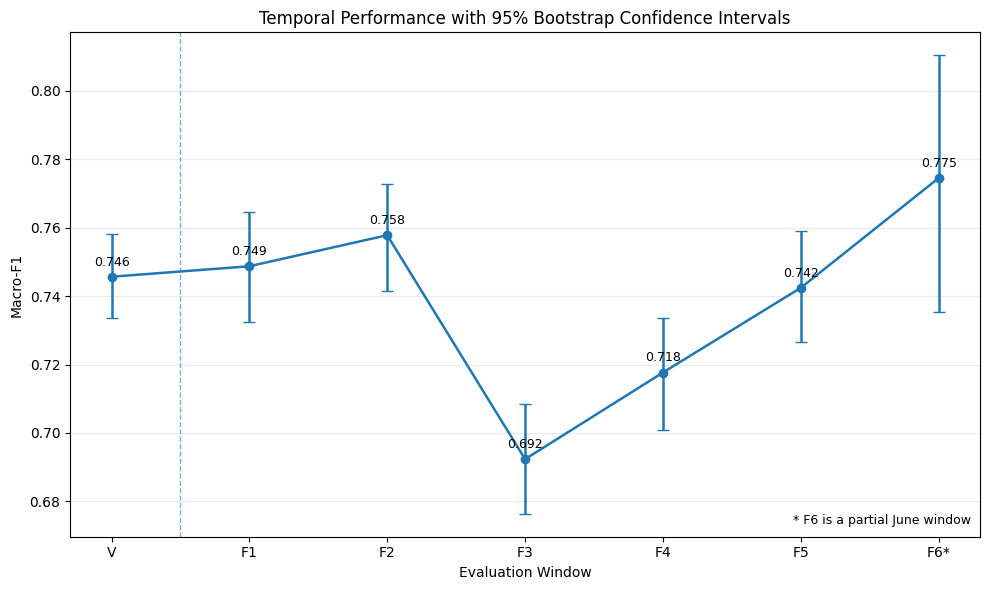

DAY 17 — FIGURE 1 CHECKPOINT
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/figures/temporal_macro_f1_ci.png
Exists: True
Size  : 182,328 bytes
----------------------------------------------------------------------------------------------------
PASS — seven_curve_points
PASS — period_order_correct
PASS — f6_is_partial
PASS — figure_exists
PASS — figure_nonempty
----------------------------------------------------------------------------------------------------
PASS — temporal_macro_f1_ci.png created


In [ ]:
# Figure 1:
# Macro-F1 with 95% bootstrap CI across V + F1–F6
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

MACRO_F1_FIGURE_PATH = (
    FIGURE_DIR / "temporal_macro_f1_ci.png"
)

# ------------------------------------------------------------
# 1. Extract Macro-F1 uncertainty
# ------------------------------------------------------------
macro_ci = (
    period_metric_uncertainty.loc[
        period_metric_uncertainty["metric"] == "macro_f1",
        [
            "period",
            "period_type",
            "n",
            "point_estimate",
            "ci_lower_95",
            "ci_upper_95",
        ],
    ]
    .copy()
)

macro_ci["period"] = (
    macro_ci["period"]
    .astype(str)
)

macro_ci["_order"] = (
    macro_ci["period"]
    .map({
        p: i
        for i, p in enumerate(EVAL_PERIOD_ORDER)
    })
)

macro_ci = (
    macro_ci
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Error-bar quantities
# ------------------------------------------------------------
x = np.arange(len(macro_ci))

y = macro_ci[
    "point_estimate"
].to_numpy()

lower_error = (
    macro_ci["point_estimate"]
    - macro_ci["ci_lower_95"]
).to_numpy()

upper_error = (
    macro_ci["ci_upper_95"]
    - macro_ci["point_estimate"]
).to_numpy()

yerr = np.vstack([
    lower_error,
    upper_error,
])

# F6 explicitly marked partial
x_labels = [
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6*",
]

# ------------------------------------------------------------
# 3. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(10, 6)
)

ax.errorbar(
    x,
    y,
    yerr=yerr,
    fmt="o-",
    capsize=4,
    linewidth=1.8,
    markersize=6,
)

# Separate historical validation anchor from future windows
ax.axvline(
    x=0.5,
    linestyle="--",
    linewidth=1,
    alpha=0.6,
)

ax.set_xticks(x)
ax.set_xticklabels(x_labels)

ax.set_xlabel(
    "Evaluation Window"
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_title(
    "Temporal Performance with 95% Bootstrap Confidence Intervals"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

# ------------------------------------------------------------
# 4. Point annotations
# ------------------------------------------------------------
for i, value in enumerate(y):
    ax.annotate(
        f"{value:.3f}",
        xy=(i, value),
        xytext=(0, 8),
        textcoords="offset points",
        ha="center",
        fontsize=9,
    )

# ------------------------------------------------------------
# 5. F6 caveat
# ------------------------------------------------------------
ax.text(
    0.99,
    0.02,
    "* F6 is a partial June window",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)

fig.tight_layout()

fig.savefig(
    MACRO_F1_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 6. Artifact verification
# ------------------------------------------------------------
figure_exists = (
    MACRO_F1_FIGURE_PATH.exists()
)

figure_size = (
    MACRO_F1_FIGURE_PATH.stat().st_size
    if figure_exists
    else 0
)

checks = {
    "seven_curve_points":
        len(macro_ci) == 7,

    "period_order_correct":
        macro_ci[
            "period"
        ].tolist()
        == EVAL_PERIOD_ORDER,

    "f6_is_partial":
        macro_ci.loc[
            macro_ci["period"] == "F6",
            "period_type",
        ].iloc[0]
        == "future_partial",

    "figure_exists":
        figure_exists,

    "figure_nonempty":
        figure_size > 0,
}

print("=" * 100)
print("DAY 17 — FIGURE 1 CHECKPOINT")
print("=" * 100)

print(f"Saved : {MACRO_F1_FIGURE_PATH}")
print(f"Exists: {figure_exists}")
print(f"Size  : {figure_size:,} bytes")

print("-" * 100)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 100)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Figure 1 checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — temporal_macro_f1_ci.png created"
)
print("=" * 100)

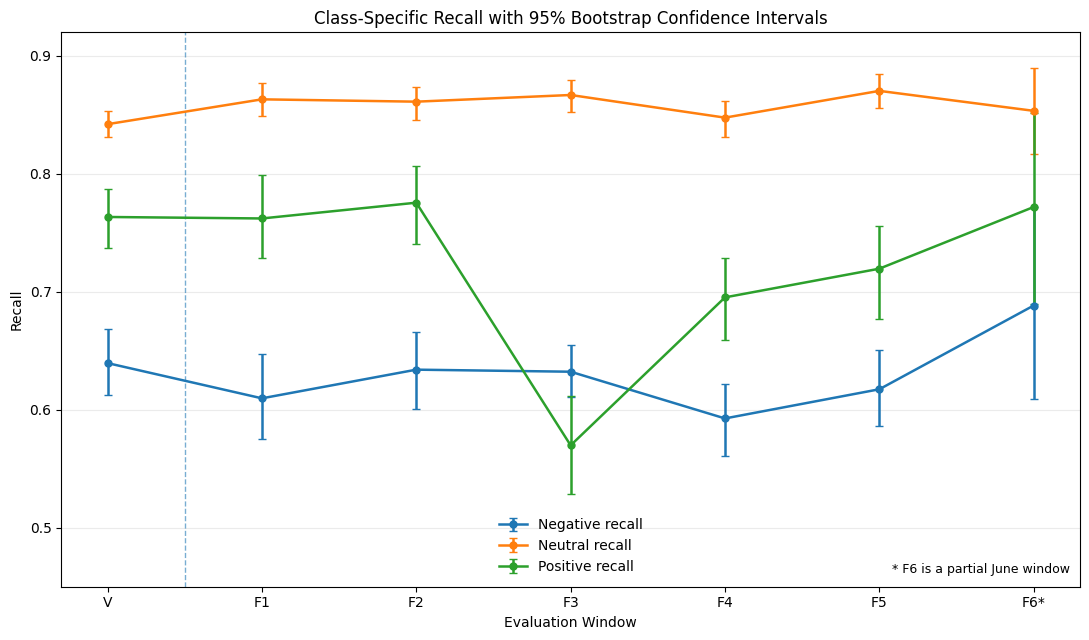

DAY 17 — FIGURE 2 CHECKPOINT
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/figures/class_recall_ci.png
Exists: True
Size  : 226,070 bytes
----------------------------------------------------------------------------------------------------
PASS — recall_rows_21
PASS — three_recall_metrics
PASS — seven_periods_per_metric
PASS — f6_is_partial
PASS — figure_exists
PASS — figure_nonempty
----------------------------------------------------------------------------------------------------
PASS — class_recall_ci.png created


In [ ]:
# Figure 2:
# Class-specific recall with 95% bootstrap CI
# across V + F1–F6
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CLASS_RECALL_FIGURE_PATH = (
    FIGURE_DIR / "class_recall_ci.png"
)

# ------------------------------------------------------------
# 1. Extract class-recall uncertainty
# ------------------------------------------------------------
recall_metrics = [
    "negative_recall",
    "neutral_recall",
    "positive_recall",
]

recall_ci = (
    period_metric_uncertainty.loc[
        period_metric_uncertainty["metric"].isin(recall_metrics),
        [
            "period",
            "period_type",
            "metric",
            "point_estimate",
            "ci_lower_95",
            "ci_upper_95",
        ],
    ]
    .copy()
)

recall_ci["period"] = (
    recall_ci["period"].astype(str)
)

period_order_map = {
    p: i
    for i, p in enumerate(EVAL_PERIOD_ORDER)
}

metric_order_map = {
    "negative_recall": 0,
    "neutral_recall": 1,
    "positive_recall": 2,
}

recall_ci["_period_order"] = (
    recall_ci["period"].map(period_order_map)
)

recall_ci["_metric_order"] = (
    recall_ci["metric"].map(metric_order_map)
)

recall_ci = (
    recall_ci
    .sort_values(
        ["_metric_order", "_period_order"]
    )
    .drop(
        columns=[
            "_period_order",
            "_metric_order",
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(11, 6.5)
)

x = np.arange(
    len(EVAL_PERIOD_ORDER)
)

metric_labels = {
    "negative_recall": "Negative recall",
    "neutral_recall": "Neutral recall",
    "positive_recall": "Positive recall",
}

for metric in recall_metrics:

    d = (
        recall_ci.loc[
            recall_ci["metric"] == metric
        ]
        .set_index("period")
        .reindex(EVAL_PERIOD_ORDER)
        .reset_index()
    )

    y = d[
        "point_estimate"
    ].to_numpy()

    lower_error = (
        d["point_estimate"]
        - d["ci_lower_95"]
    ).to_numpy()

    upper_error = (
        d["ci_upper_95"]
        - d["point_estimate"]
    ).to_numpy()

    ax.errorbar(
        x,
        y,
        yerr=np.vstack([
            lower_error,
            upper_error,
        ]),
        marker="o",
        linewidth=1.8,
        markersize=5,
        capsize=3,
        label=metric_labels[metric],
    )

# Historical/future separator
ax.axvline(
    x=0.5,
    linestyle="--",
    linewidth=1,
    alpha=0.6,
)

ax.set_xticks(x)

ax.set_xticklabels([
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6*",
])

ax.set_xlabel(
    "Evaluation Window"
)

ax.set_ylabel(
    "Recall"
)

ax.set_title(
    "Class-Specific Recall with 95% Bootstrap Confidence Intervals"
)

ax.set_ylim(
    0.45,
    0.92,
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    frameon=False
)

# ------------------------------------------------------------
# 3. F6 caveat
# ------------------------------------------------------------
ax.text(
    0.99,
    0.02,
    "* F6 is a partial June window",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)

fig.tight_layout()

fig.savefig(
    CLASS_RECALL_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 4. Artifact verification
# ------------------------------------------------------------
figure_exists = (
    CLASS_RECALL_FIGURE_PATH.exists()
)

figure_size = (
    CLASS_RECALL_FIGURE_PATH.stat().st_size
    if figure_exists
    else 0
)

checks = {
    "recall_rows_21":
        len(recall_ci) == 21,

    "three_recall_metrics":
        set(
            recall_ci["metric"].unique()
        ) == set(recall_metrics),

    "seven_periods_per_metric":
        all(
            (
                recall_ci["metric"] == metric
            ).sum() == 7
            for metric in recall_metrics
        ),

    "f6_is_partial":
        set(
            recall_ci.loc[
                recall_ci["period"] == "F6",
                "period_type",
            ].unique()
        ) == {"future_partial"},

    "figure_exists":
        figure_exists,

    "figure_nonempty":
        figure_size > 0,
}

print("=" * 100)
print("DAY 17 — FIGURE 2 CHECKPOINT")
print("=" * 100)

print(f"Saved : {CLASS_RECALL_FIGURE_PATH}")
print(f"Exists: {figure_exists}")
print(f"Size  : {figure_size:,} bytes")

print("-" * 100)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 100)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Figure 2 checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — class_recall_ci.png created"
)
print("=" * 100)

In [ ]:
# ============================================================
# DAY 17 — CELL 14
# Stage B final checkpoint
# ============================================================

STAGE_B_REQUIRED_ARTIFACTS = {
    "temporal_metric_uncertainty.csv":
        TEMPORAL_UNCERTAINTY_PATH,

    "temporal_macro_f1_ci.png":
        MACRO_F1_FIGURE_PATH,

    "class_recall_ci.png":
        CLASS_RECALL_FIGURE_PATH,
}

print("=" * 100)
print("DAY 17 — STAGE B FINAL CHECKPOINT")
print("=" * 100)

artifact_checks = {}

for name, path in STAGE_B_REQUIRED_ARTIFACTS.items():

    exists = path.exists()

    size = (
        path.stat().st_size
        if exists
        else 0
    )

    artifact_checks[name] = (
        exists and size > 0
    )

    print(
        f"{'PASS' if artifact_checks[name] else 'FAIL':4s}"
        f" — {name:<35s}"
        f"{size:>12,} bytes"
    )

print("-" * 100)

stage_b_checks = {
    "bootstrap_replicates_1000":
        BOOTSTRAP_REPLICATES == 1000,

    "seven_periods_analyzed":
        len(EVAL_PERIOD_ORDER) == 7,

    "period_metric_uncertainty_complete":
        len(period_metric_uncertainty) == 35,

    "macro_f1_delta_uncertainty_complete":
        len(macro_f1_delta_uncertainty) == 11,

    "all_stage_B_artifacts_present":
        all(
            artifact_checks.values()
        ),

    "f6_retained_as_partial":
        set(
            evaluation_population.loc[
                evaluation_population["period"] == "F6",
                "period_type",
            ]
        ) == {"future_partial"},
}

for name, status in stage_b_checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 100)

if not all(stage_b_checks.values()):
    failed = [
        name
        for name, status in stage_b_checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage B final checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — STAGE B TEMPORAL UNCERTAINTY "
    "QUANTIFICATION COMPLETE"
)
print("=" * 100)

DAY 17 — STAGE B FINAL CHECKPOINT
PASS — temporal_metric_uncertainty.csv           5,956 bytes
PASS — temporal_macro_f1_ci.png                182,328 bytes
PASS — class_recall_ci.png                     226,070 bytes
----------------------------------------------------------------------------------------------------
PASS — bootstrap_replicates_1000
PASS — seven_periods_analyzed
PASS — period_metric_uncertainty_complete
PASS — macro_f1_delta_uncertainty_complete
PASS — all_stage_B_artifacts_present
PASS — f6_retained_as_partial
----------------------------------------------------------------------------------------------------
PASS — STAGE B TEMPORAL UNCERTAINTY QUANTIFICATION COMPLETE


## Stage C — Class-Level Performance Decomposition

The objective is to determine whether the F3/F4 Macro-F1 decline is broad across all sentiment classes or concentrated in specific classes.

For each evaluation window, Day 17 examines:

- class precision,
- class recall,
- class F1,
- class support,
- class-F1 change relative to Historical Validation,
- class-F1 change relative to F1,
- arithmetic contribution of each class to the aggregate Macro-F1 change.

For a three-class Macro-F1:

\[
\Delta \text{Macro-F1}
=
\frac{
\Delta F1_{\text{negative}}
+
\Delta F1_{\text{neutral}}
+
\Delta F1_{\text{positive}}
}{3}.
\]

The class contribution is therefore defined descriptively as:

\[
\text{Contribution}_c
=
\frac{\Delta F1_c}{3}.
\]

This is an arithmetic decomposition, not a causal attribution.

In [ ]:
# Build class-level diagnostic summary for V + F1–F6
import numpy as np
import pandas as pd

from sklearn.metrics import precision_recall_fscore_support

# ------------------------------------------------------------
# 1. Recompute V class-level metrics from row-level predictions
# ------------------------------------------------------------
v_precision, v_recall, v_f1, v_support = (
    precision_recall_fscore_support(
        validation_eval["y_true"],
        validation_eval["y_pred"],
        labels=LABEL_ORDER,
        zero_division=0,
    )
)

v_class_rows = []

for i, label in enumerate(LABEL_ORDER):
    v_class_rows.append({
        "period": "V",
        "period_type": "historical_validation",
        "class": label,
        "support": int(v_support[i]),
        "precision": float(v_precision[i]),
        "recall": float(v_recall[i]),
        "f1": float(v_f1[i]),
    })

v_class_performance = pd.DataFrame(
    v_class_rows
)

# ------------------------------------------------------------
# 2. Combine with frozen future class-performance table
# ------------------------------------------------------------
future_class_diag = (
    future_class_performance[
        [
            "period",
            "period_type",
            "class",
            "support",
            "precision",
            "recall",
            "f1",
        ]
    ]
    .copy()
)

class_diagnostic_summary = pd.concat(
    [
        v_class_performance,
        future_class_diag,
    ],
    ignore_index=True,
)

# ------------------------------------------------------------
# 3. Add ordering
# ------------------------------------------------------------
class_diagnostic_summary["period"] = pd.Categorical(
    class_diagnostic_summary["period"],
    categories=EVAL_PERIOD_ORDER,
    ordered=True,
)

class_diagnostic_summary["class"] = pd.Categorical(
    class_diagnostic_summary["class"],
    categories=LABEL_ORDER,
    ordered=True,
)

class_diagnostic_summary = (
    class_diagnostic_summary
    .sort_values(
        ["period", "class"]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 4. Reference class-F1 lookups
# ------------------------------------------------------------
v_f1_lookup = (
    class_diagnostic_summary.loc[
        class_diagnostic_summary["period"] == "V",
        ["class", "f1"],
    ]
    .set_index("class")["f1"]
    .to_dict()
)

f1_f1_lookup = (
    class_diagnostic_summary.loc[
        class_diagnostic_summary["period"] == "F1",
        ["class", "f1"],
    ]
    .set_index("class")["f1"]
    .to_dict()
)

# ------------------------------------------------------------
# 5. Class-F1 changes and Macro-F1 contributions
# ------------------------------------------------------------
class_diagnostic_summary["f1_change_vs_V"] = (
    class_diagnostic_summary.apply(
        lambda row:
            row["f1"] - v_f1_lookup[row["class"]],
        axis=1,
    )
)

class_diagnostic_summary["f1_change_vs_F1"] = (
    class_diagnostic_summary.apply(
        lambda row:
            row["f1"] - f1_f1_lookup[row["class"]],
        axis=1,
    )
)

class_diagnostic_summary[
    "macro_f1_contribution_vs_V"
] = (
    class_diagnostic_summary[
        "f1_change_vs_V"
    ] / 3.0
)

class_diagnostic_summary[
    "macro_f1_contribution_vs_F1"
] = (
    class_diagnostic_summary[
        "f1_change_vs_F1"
    ] / 3.0
)

# ------------------------------------------------------------
# 6. Validate arithmetic decomposition
# ------------------------------------------------------------
observed_macro = (
    period_metric_uncertainty.loc[
        period_metric_uncertainty["metric"] == "macro_f1",
        ["period", "point_estimate"],
    ]
    .copy()
)

observed_macro["period"] = (
    observed_macro["period"].astype(str)
)

macro_lookup = (
    observed_macro
    .set_index("period")["point_estimate"]
    .to_dict()
)

contribution_check_rows = []

for period in EVAL_PERIOD_ORDER:

    d = class_diagnostic_summary.loc[
        class_diagnostic_summary["period"] == period
    ]

    contribution_vs_V = float(
        d[
            "macro_f1_contribution_vs_V"
        ].sum()
    )

    contribution_vs_F1 = float(
        d[
            "macro_f1_contribution_vs_F1"
        ].sum()
    )

    expected_vs_V = (
        macro_lookup[period]
        - macro_lookup["V"]
    )

    expected_vs_F1 = (
        macro_lookup[period]
        - macro_lookup["F1"]
    )

    contribution_check_rows.append({
        "period": period,

        "sum_contribution_vs_V":
            contribution_vs_V,

        "expected_macro_delta_vs_V":
            expected_vs_V,

        "abs_diff_vs_V":
            abs(
                contribution_vs_V
                - expected_vs_V
            ),

        "sum_contribution_vs_F1":
            contribution_vs_F1,

        "expected_macro_delta_vs_F1":
            expected_vs_F1,

        "abs_diff_vs_F1":
            abs(
                contribution_vs_F1
                - expected_vs_F1
            ),
    })

class_contribution_check = pd.DataFrame(
    contribution_check_rows
)

TOL = 1e-12

# ------------------------------------------------------------
# 7. Formal checks
# ------------------------------------------------------------
checks = {
    "class_table_has_21_rows":
        len(class_diagnostic_summary) == 21,

    "three_classes_per_period":
        all(
            (
                class_diagnostic_summary["period"]
                == period
            ).sum() == 3
            for period in EVAL_PERIOD_ORDER
        ),

    "all_support_positive":
        bool(
            (
                class_diagnostic_summary[
                    "support"
                ] > 0
            ).all()
        ),

    "decomposition_vs_V_exact":
        bool(
            (
                class_contribution_check[
                    "abs_diff_vs_V"
                ]
                <= TOL
            ).all()
        ),

    "decomposition_vs_F1_exact":
        bool(
            (
                class_contribution_check[
                    "abs_diff_vs_F1"
                ]
                <= TOL
            ).all()
        ),
}

# ------------------------------------------------------------
# 8. Display compact class table
# ------------------------------------------------------------
print("=" * 150)
print("DAY 17 — CLASS-LEVEL PERFORMANCE DECOMPOSITION")
print("=" * 150)

display_cols = [
    "period",
    "class",
    "support",
    "precision",
    "recall",
    "f1",
    "f1_change_vs_V",
    "macro_f1_contribution_vs_V",
    "f1_change_vs_F1",
    "macro_f1_contribution_vs_F1",
]

print(
    class_diagnostic_summary[
        display_cols
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n[Arithmetic decomposition check]")
print(
    class_contribution_check.to_string(
        index=False,
        float_format=lambda x: f"{x:.12f}",
    )
)

print("\n" + "-" * 150)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 150)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage C class-level decomposition failed: "
        + ", ".join(failed)
    )

print(
    "PASS — class-level decomposition constructed "
    "for V + F1–F6"
)
print("=" * 150)

DAY 17 — CLASS-LEVEL PERFORMANCE DECOMPOSITION
period    class  support  precision   recall       f1  f1_change_vs_V  macro_f1_contribution_vs_V  f1_change_vs_F1  macro_f1_contribution_vs_F1
     V negative     1132   0.741803 0.639576 0.686907        0.000000                    0.000000         0.005426                     0.001809
     V  neutral     3687   0.844668 0.842148 0.843406        0.000000                    0.000000        -0.010094                    -0.003365
     V positive     1040   0.657829 0.763462 0.706720        0.000000                    0.000000        -0.004522                    -0.001507
    F1 negative      679   0.772388 0.609720 0.681481       -0.005426                   -0.001809         0.000000                     0.000000
    F1  neutral     2288   0.844017 0.863199 0.853500        0.010094                    0.003365         0.000000                     0.000000
    F1 positive      635   0.666667 0.762205 0.711242        0.004522                    

In [ ]:
# Key-window class diagnostic contrast:
# F3 dip, F4 incomplete recovery, F5 recovery
KEY_WINDOWS = ["F3", "F4", "F5"]

key_class_diagnostics = (
    class_diagnostic_summary.loc[
        class_diagnostic_summary["period"].isin(KEY_WINDOWS),
        [
            "period",
            "class",
            "support",
            "precision",
            "recall",
            "f1",
            "f1_change_vs_F1",
            "macro_f1_contribution_vs_F1",
        ],
    ]
    .copy()
)

# Ensure readable ordering
key_class_diagnostics["period"] = pd.Categorical(
    key_class_diagnostics["period"],
    categories=KEY_WINDOWS,
    ordered=True,
)

key_class_diagnostics["class"] = pd.Categorical(
    key_class_diagnostics["class"],
    categories=LABEL_ORDER,
    ordered=True,
)

key_class_diagnostics = (
    key_class_diagnostics
    .sort_values(["period", "class"])
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Summary contribution by window
# ------------------------------------------------------------
window_contribution_summary = (
    key_class_diagnostics
    .groupby(
        "period",
        observed=False,
    )
    .agg(
        macro_f1_delta_vs_F1=(
            "macro_f1_contribution_vs_F1",
            "sum",
        )
    )
    .reset_index()
)

# ------------------------------------------------------------
# Identify largest absolute class contribution
# within each window
# ------------------------------------------------------------
largest_contributors = []

for period in KEY_WINDOWS:
    d = key_class_diagnostics.loc[
        key_class_diagnostics["period"] == period
    ].copy()

    d["abs_contribution"] = (
        d["macro_f1_contribution_vs_F1"].abs()
    )

    top = d.sort_values(
        "abs_contribution",
        ascending=False,
    ).iloc[0]

    largest_contributors.append({
        "period": period,
        "largest_contributing_class": str(top["class"]),
        "class_f1_change_vs_F1": float(
            top["f1_change_vs_F1"]
        ),
        "macro_f1_contribution_vs_F1": float(
            top["macro_f1_contribution_vs_F1"]
        ),
    })

largest_contributors = pd.DataFrame(
    largest_contributors
)

# ------------------------------------------------------------
# Formal checks
# ------------------------------------------------------------
checks = {
    "nine_key_rows":
        len(key_class_diagnostics) == 9,

    "three_classes_each_window":
        all(
            (
                key_class_diagnostics["period"] == p
            ).sum() == 3
            for p in KEY_WINDOWS
        ),

    "three_window_summaries":
        len(window_contribution_summary) == 3,

    "three_largest_contributors":
        len(largest_contributors) == 3,
}

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------
print("=" * 140)
print("DAY 17 — KEY-WINDOW CLASS DIAGNOSTIC CONTRAST")
print("=" * 140)

print("\n[Class-level diagnostics: F3 / F4 / F5]")
print(
    key_class_diagnostics.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n[Window-level Macro-F1 delta reconstruction vs F1]")
print(
    window_contribution_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n[Largest absolute class contribution by window]")
print(
    largest_contributors.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "-" * 140)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 140)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Key-window class diagnostic contrast failed: "
        + ", ".join(failed)
    )

print(
    "PASS — F3/F4/F5 class diagnostic contrast assembled"
)
print("=" * 140)

DAY 17 — KEY-WINDOW CLASS DIAGNOSTIC CONTRAST

[Class-level diagnostics: F3 / F4 / F5]
period    class  support  precision   recall       f1  f1_change_vs_F1  macro_f1_contribution_vs_F1
    F3 negative     1735   0.825433 0.632277 0.716057         0.034576                     0.011525
    F3  neutral     2539   0.755578 0.866877 0.807410        -0.046090                    -0.015363
    F3 positive      544   0.538194 0.569853 0.553571        -0.157670                    -0.052557
    F4 negative     1036   0.761787 0.592664 0.666667        -0.014815                    -0.004938
    F4  neutral     2219   0.780822 0.847679 0.812878        -0.040622                    -0.013541
    F4 positive      617   0.652968 0.695300 0.673469        -0.037772                    -0.012591
    F5 negative      839   0.792049 0.617402 0.693905         0.012423                     0.004141
    F5  neutral     2214   0.819303 0.870370 0.844065        -0.009436                    -0.003145
    F5 positi

In [ ]:
# Save class_diagnostic_summary.csv

CLASS_DIAGNOSTIC_PATH = (
    DAY17_DIR / "class_diagnostic_summary.csv"
)

# ------------------------------------------------------------
# 1. Convert categorical columns to strings before export
# ------------------------------------------------------------
class_diagnostic_export = (
    class_diagnostic_summary.copy()
)

class_diagnostic_export["period"] = (
    class_diagnostic_export["period"].astype(str)
)

class_diagnostic_export["class"] = (
    class_diagnostic_export["class"].astype(str)
)

# ------------------------------------------------------------
# 2. Final export column order
# ------------------------------------------------------------
export_columns = [
    "period",
    "period_type",
    "class",
    "support",
    "precision",
    "recall",
    "f1",
    "f1_change_vs_V",
    "macro_f1_contribution_vs_V",
    "f1_change_vs_F1",
    "macro_f1_contribution_vs_F1",
]

class_diagnostic_export = (
    class_diagnostic_export[
        export_columns
    ]
)

# ------------------------------------------------------------
# 3. Save
# ------------------------------------------------------------
class_diagnostic_export.to_csv(
    CLASS_DIAGNOSTIC_PATH,
    index=False,
)

# ------------------------------------------------------------
# 4. Reload and verify
# ------------------------------------------------------------
reloaded_class_diag = pd.read_csv(
    CLASS_DIAGNOSTIC_PATH
)

artifact_exists = (
    CLASS_DIAGNOSTIC_PATH.exists()
)

artifact_size = (
    CLASS_DIAGNOSTIC_PATH.stat().st_size
    if artifact_exists
    else 0
)

checks = {
    "artifact_exists":
        artifact_exists,

    "artifact_nonempty":
        artifact_size > 0,

    "row_count_21":
        len(reloaded_class_diag) == 21,

    "seven_periods":
        set(
            reloaded_class_diag[
                "period"
            ].unique()
        ) == set(EVAL_PERIOD_ORDER),

    "three_classes":
        set(
            reloaded_class_diag[
                "class"
            ].unique()
        ) == set(LABEL_ORDER),

    "three_rows_per_period":
        all(
            (
                reloaded_class_diag[
                    "period"
                ] == period
            ).sum() == 3
            for period in EVAL_PERIOD_ORDER
        ),

    "no_missing_core_metrics":
        not reloaded_class_diag[
            [
                "support",
                "precision",
                "recall",
                "f1",
                "f1_change_vs_V",
                "f1_change_vs_F1",
            ]
        ].isna().any().any(),
}

print("=" * 110)
print("DAY 17 — CLASS DIAGNOSTIC ARTIFACT")
print("=" * 110)

print(f"Saved : {CLASS_DIAGNOSTIC_PATH}")
print(f"Exists: {artifact_exists}")
print(f"Size  : {artifact_size:,} bytes")
print(f"Rows  : {len(reloaded_class_diag)}")

print("-" * 110)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 110)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Class diagnostic artifact failed: "
        + ", ".join(failed)
    )

print(
    "PASS — class_diagnostic_summary.csv frozen"
)
print("=" * 110)

DAY 17 — CLASS DIAGNOSTIC ARTIFACT
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/class_diagnostic_summary.csv
Exists: True
Size  : 3,558 bytes
Rows  : 21
--------------------------------------------------------------------------------------------------------------
PASS — artifact_exists
PASS — artifact_nonempty
PASS — row_count_21
PASS — seven_periods
PASS — three_classes
PASS — three_rows_per_period
PASS — no_missing_core_metrics
--------------------------------------------------------------------------------------------------------------
PASS — class_diagnostic_summary.csv frozen


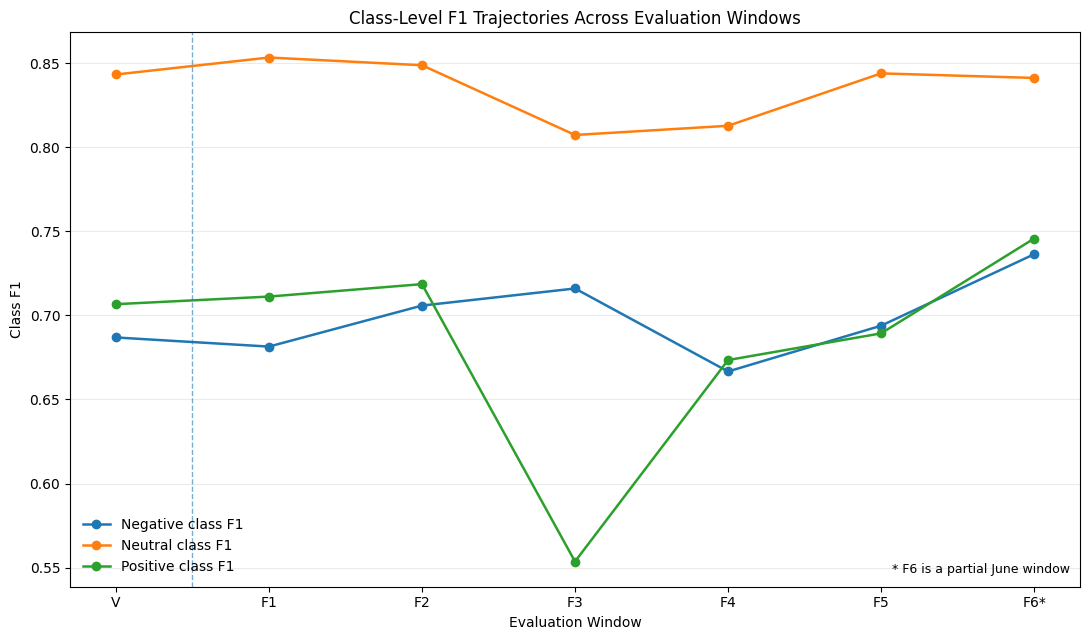

DAY 17 — CLASS F1 FIGURE CHECKPOINT
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/figures/class_f1_trajectory.png
Exists: True
Size  : 243,594 bytes
----------------------------------------------------------------------------------------------------
PASS — class_f1_rows_21
PASS — three_classes
PASS — seven_periods_each_class
PASS — figure_exists
PASS — figure_nonempty
----------------------------------------------------------------------------------------------------
PASS — class_f1_trajectory.png created


In [ ]:
# Class-F1 trajectories across V + F1–F6
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

CLASS_F1_FIGURE_PATH = (
    FIGURE_DIR / "class_f1_trajectory.png"
)
# 1. Prepare plotting table
# ------------------------------------------------------------
class_f1_plot = (
    class_diagnostic_export[
        [
            "period",
            "class",
            "f1",
        ]
    ]
    .copy()
)

period_order_map = {
    p: i
    for i, p in enumerate(EVAL_PERIOD_ORDER)
}

class_order_map = {
    "negative": 0,
    "neutral": 1,
    "positive": 2,
}

class_f1_plot["_period_order"] = (
    class_f1_plot["period"]
    .map(period_order_map)
)

class_f1_plot["_class_order"] = (
    class_f1_plot["class"]
    .map(class_order_map)
)

class_f1_plot = (
    class_f1_plot
    .sort_values(
        [
            "_class_order",
            "_period_order",
        ]
    )
    .drop(
        columns=[
            "_class_order",
            "_period_order",
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(11, 6.5)
)

x = np.arange(
    len(EVAL_PERIOD_ORDER)
)

class_labels = {
    "negative": "Negative class F1",
    "neutral": "Neutral class F1",
    "positive": "Positive class F1",
}

for label in LABEL_ORDER:

    d = (
        class_f1_plot.loc[
            class_f1_plot["class"] == label
        ]
        .set_index("period")
        .reindex(EVAL_PERIOD_ORDER)
        .reset_index()
    )

    ax.plot(
        x,
        d["f1"].to_numpy(),
        marker="o",
        linewidth=1.8,
        markersize=6,
        label=class_labels[label],
    )

# Historical/future separator
ax.axvline(
    x=0.5,
    linestyle="--",
    linewidth=1,
    alpha=0.6,
)

ax.set_xticks(x)

ax.set_xticklabels([
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6*",
])

ax.set_xlabel(
    "Evaluation Window"
)

ax.set_ylabel(
    "Class F1"
)

ax.set_title(
    "Class-Level F1 Trajectories Across Evaluation Windows"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    frameon=False
)

# ------------------------------------------------------------
# 3. F6 caveat
# ------------------------------------------------------------
ax.text(
    0.99,
    0.02,
    "* F6 is a partial June window",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)

fig.tight_layout()

fig.savefig(
    CLASS_F1_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 4. Artifact verification
# ------------------------------------------------------------
figure_exists = (
    CLASS_F1_FIGURE_PATH.exists()
)

figure_size = (
    CLASS_F1_FIGURE_PATH.stat().st_size
    if figure_exists
    else 0
)

checks = {
    "class_f1_rows_21":
        len(class_f1_plot) == 21,

    "three_classes":
        set(
            class_f1_plot[
                "class"
            ].unique()
        ) == set(LABEL_ORDER),

    "seven_periods_each_class":
        all(
            (
                class_f1_plot[
                    "class"
                ] == label
            ).sum() == 7
            for label in LABEL_ORDER
        ),

    "figure_exists":
        figure_exists,

    "figure_nonempty":
        figure_size > 0,
}

print("=" * 100)
print("DAY 17 — CLASS F1 FIGURE CHECKPOINT")
print("=" * 100)

print(f"Saved : {CLASS_F1_FIGURE_PATH}")
print(f"Exists: {figure_exists}")
print(f"Size  : {figure_size:,} bytes")

print("-" * 100)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 100)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Class F1 figure checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — class_f1_trajectory.png created"
)
print("=" * 100)

In [ ]:
# Stage C final checkpoint

STAGE_C_REQUIRED_ARTIFACTS = {
    "class_diagnostic_summary.csv":
        CLASS_DIAGNOSTIC_PATH,

    "class_f1_trajectory.png":
        CLASS_F1_FIGURE_PATH,
}
print("=" * 100)
print("DAY 17 — STAGE C FINAL CHECKPOINT")
print("=" * 100)

artifact_checks = {}

for name, path in STAGE_C_REQUIRED_ARTIFACTS.items():

    exists = path.exists()

    size = (
        path.stat().st_size
        if exists
        else 0
    )

    artifact_checks[name] = (
        exists and size > 0
    )

    print(
        f"{'PASS' if artifact_checks[name] else 'FAIL':4s}"
        f" — {name:<35s}"
        f"{size:>12,} bytes"
    )

print("-" * 100)

stage_c_checks = {
    "class_summary_rows_21":
        len(class_diagnostic_export) == 21,

    "three_classes_per_period":
        all(
            (
                class_diagnostic_export["period"] == p
            ).sum() == 3
            for p in EVAL_PERIOD_ORDER
        ),

    "decomposition_vs_V_exact":
        bool(
            (
                class_contribution_check[
                    "abs_diff_vs_V"
                ]
                <= 1e-12
            ).all()
        ),

    "decomposition_vs_F1_exact":
        bool(
            (
                class_contribution_check[
                    "abs_diff_vs_F1"
                ]
                <= 1e-12
            ).all()
        ),

    "key_windows_F3_F4_F5_present":
        set(
            key_class_diagnostics[
                "period"
            ].astype(str)
        ) == {"F3", "F4", "F5"},

    "all_stage_C_artifacts_present":
        all(
            artifact_checks.values()
        ),
}

for name, status in stage_c_checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 100)

if not all(stage_c_checks.values()):
    failed = [
        name
        for name, status in stage_c_checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage C final checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — STAGE C CLASS-LEVEL "
    "PERFORMANCE DECOMPOSITION COMPLETE"
)
print("=" * 100)

DAY 17 — STAGE C FINAL CHECKPOINT
PASS — class_diagnostic_summary.csv              3,558 bytes
PASS — class_f1_trajectory.png                 243,594 bytes
----------------------------------------------------------------------------------------------------
PASS — class_summary_rows_21
PASS — three_classes_per_period
PASS — decomposition_vs_V_exact
PASS — decomposition_vs_F1_exact
PASS — key_windows_F3_F4_F5_present
PASS — all_stage_C_artifacts_present
----------------------------------------------------------------------------------------------------
PASS — STAGE C CLASS-LEVEL PERFORMANCE DECOMPOSITION COMPLETE


## Stage D — Transition-Level Error Diagnosis

Class-level decomposition identifies which sentiment classes contribute to the temporal performance movement.

Stage D moves one level deeper and diagnoses the exact prediction transitions responsible for those class-level changes.

For each evaluation window, all nine true-label → predicted-label transitions are retained:

- negative → negative
- negative → neutral
- negative → positive
- neutral → negative
- neutral → neutral
- neutral → positive
- positive → negative
- positive → neutral
- positive → positive

The pre-specified priority failure mode is:

**negative → neutral**

Additional diagnostic transitions include:

- positive → neutral,
- positive → negative,
- neutral → negative,
- neutral → positive.

For each transition, the analysis records:

- count,
- true-class support,
- conditional transition rate,
- change in conditional rate versus F1,
- excess transition count relative to the F1-rate benchmark.

The excess count is descriptive:

\[
\text{Excess Count}_{k,i\to j}
=
\text{Observed Count}_{k,i\to j}
-
N_{k,i}\times
P_{F1}(\hat y=j\mid y=i).
\]

This separates changes in transition rate from changes in true-class support. It is not a causal decomposition.

In [ ]:
# Build unified transition diagnostic table:
# V + F1–F6, all 9 transition cells per period
#
# IMPORTANT:
# Canonical transition labels are reconstructed from
# true_label and pred_label rather than relying on the
# string formatting inherited from Day 16.

import numpy as np
import pandas as pd

TRANSITION_TOL = 1e-12

# 1. Reconstruct V transition table from row-level predictions
v_transition_counts = (
    validation_eval
    .groupby(
        ["y_true", "y_pred"],
        observed=False,
    )
    .size()
    .reset_index(name="count")
    .rename(
        columns={
            "y_true": "true_label",
            "y_pred": "pred_label",
        }
    )
)

# Full 3 x 3 grid
label_grid = pd.MultiIndex.from_product(
    [
        LABEL_ORDER,
        LABEL_ORDER,
    ],
    names=[
        "true_label",
        "pred_label",
    ],
).to_frame(index=False)

v_transition_counts = (
    label_grid
    .merge(
        v_transition_counts,
        on=[
            "true_label",
            "pred_label",
        ],
        how="left",
    )
)

v_transition_counts["count"] = (
    v_transition_counts["count"]
    .fillna(0)
    .astype(int)
)

v_support = (
    v_transition_counts
    .groupby(
        "true_label",
        as_index=False,
    )["count"]
    .sum()
    .rename(
        columns={
            "count": "true_class_support"
        }
    )
)

v_transitions = (
    v_transition_counts
    .merge(
        v_support,
        on="true_label",
        how="left",
        validate="many_to_one",
    )
)

v_transitions["conditional_rate"] = (
    v_transitions["count"]
    / v_transitions["true_class_support"]
)

v_transitions["period"] = "V"

v_transitions["period_type"] = (
    "historical_validation"
)


# ------------------------------------------------------------
# 2. Normalize frozen future transition table
#
# Deliberately ignore inherited transition-string formatting.
# ------------------------------------------------------------
future_transitions = (
    future_error_transitions[
        [
            "period",
            "period_type",
            "true_label",
            "pred_label",
            "count",
            "true_class_support",
            "conditional_rate",
        ]
    ]
    .copy()
)


# ------------------------------------------------------------
# 3. Align schemas and combine
# ------------------------------------------------------------
transition_columns = [
    "period",
    "period_type",
    "true_label",
    "pred_label",
    "count",
    "true_class_support",
    "conditional_rate",
]

v_transitions = (
    v_transitions[
        transition_columns
    ]
)

transition_diagnostic_summary = pd.concat(
    [
        v_transitions,
        future_transitions,
    ],
    ignore_index=True,
)


# ------------------------------------------------------------
# 4. Construct canonical transition labels
#
# Use one formatting convention for all periods.
# ------------------------------------------------------------
transition_diagnostic_summary[
    "transition"
] = (
    transition_diagnostic_summary[
        "true_label"
    ].astype(str)
    + "→"
    + transition_diagnostic_summary[
        "pred_label"
    ].astype(str)
)


# ------------------------------------------------------------
# 5. Ordering
# ------------------------------------------------------------
transition_diagnostic_summary["period"] = (
    pd.Categorical(
        transition_diagnostic_summary["period"],
        categories=EVAL_PERIOD_ORDER,
        ordered=True,
    )
)

transition_diagnostic_summary["true_label"] = (
    pd.Categorical(
        transition_diagnostic_summary["true_label"],
        categories=LABEL_ORDER,
        ordered=True,
    )
)

transition_diagnostic_summary["pred_label"] = (
    pd.Categorical(
        transition_diagnostic_summary["pred_label"],
        categories=LABEL_ORDER,
        ordered=True,
    )
)

transition_diagnostic_summary = (
    transition_diagnostic_summary
    .sort_values(
        [
            "period",
            "true_label",
            "pred_label",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 6. Construct F1 transition-rate benchmark
#
# Key is derived from true/pred labels, not inherited text.
# ------------------------------------------------------------
f1_rate_lookup = (
    transition_diagnostic_summary.loc[
        transition_diagnostic_summary[
            "period"
        ] == "F1",
        [
            "transition",
            "conditional_rate",
        ],
    ]
    .set_index(
        "transition"
    )["conditional_rate"]
    .to_dict()
)


# ------------------------------------------------------------
# 7. Rate change and excess count relative to F1
# ------------------------------------------------------------
transition_diagnostic_summary[
    "f1_reference_rate"
] = (
    transition_diagnostic_summary[
        "transition"
    ].map(
        f1_rate_lookup
    )
)

transition_diagnostic_summary[
    "conditional_rate_change_vs_F1"
] = (
    transition_diagnostic_summary[
        "conditional_rate"
    ]
    -
    transition_diagnostic_summary[
        "f1_reference_rate"
    ]
)

transition_diagnostic_summary[
    "expected_count_at_F1_rate"
] = (
    transition_diagnostic_summary[
        "true_class_support"
    ]
    *
    transition_diagnostic_summary[
        "f1_reference_rate"
    ]
)

transition_diagnostic_summary[
    "excess_count_vs_F1_rate"
] = (
    transition_diagnostic_summary[
        "count"
    ]
    -
    transition_diagnostic_summary[
        "expected_count_at_F1_rate"
    ]
)


# ------------------------------------------------------------
# 8. Mark correct/error transitions
# ------------------------------------------------------------
transition_diagnostic_summary[
    "transition_type"
] = np.where(
    transition_diagnostic_summary[
        "true_label"
    ].astype(str)
    ==
    transition_diagnostic_summary[
        "pred_label"
    ].astype(str),
    "correct",
    "error",
)

transition_diagnostic_summary[
    "priority_transition"
] = (
    transition_diagnostic_summary[
        "transition"
    ]
    == "negative→neutral"
)


# ------------------------------------------------------------
# 9. Validate each true-class conditional distribution sums to 1
# ------------------------------------------------------------
rate_sum_check = (
    transition_diagnostic_summary
    .groupby(
        [
            "period",
            "true_label",
        ],
        observed=False,
        as_index=False,
    )["conditional_rate"]
    .sum()
)

rate_sum_check[
    "abs_diff_from_1"
] = (
    rate_sum_check[
        "conditional_rate"
    ] - 1.0
).abs()


# ------------------------------------------------------------
# 10. Formal checks
# ------------------------------------------------------------
checks = {
    "transition_table_has_63_rows":
        len(
            transition_diagnostic_summary
        ) == 63,

    "nine_cells_per_period":
        all(
            (
                transition_diagnostic_summary[
                    "period"
                ] == period
            ).sum() == 9
            for period in EVAL_PERIOD_ORDER
        ),

    "nine_unique_transition_types":
        transition_diagnostic_summary[
            "transition"
        ].nunique() == 9,

    "all_transition_rates_finite":
        np.isfinite(
            transition_diagnostic_summary[
                "conditional_rate"
            ].to_numpy()
        ).all(),

    "all_reference_rates_available":
        transition_diagnostic_summary[
            "f1_reference_rate"
        ].notna().all(),

    "conditional_rates_sum_to_one":
        bool(
            (
                rate_sum_check[
                    "abs_diff_from_1"
                ]
                <= TRANSITION_TOL
            ).all()
        ),

    "seven_priority_rows":
        int(
            transition_diagnostic_summary[
                "priority_transition"
            ].sum()
        ) == 7,
}


# ------------------------------------------------------------
# 11. Focused diagnostic transitions
# ------------------------------------------------------------
FOCUS_TRANSITIONS = [
    "negative→neutral",
    "positive→neutral",
    "positive→negative",
    "neutral→negative",
    "neutral→positive",
]

focus_transition_table = (
    transition_diagnostic_summary.loc[
        transition_diagnostic_summary[
            "transition"
        ].isin(
            FOCUS_TRANSITIONS
        ),
        [
            "period",
            "transition",
            "count",
            "true_class_support",
            "conditional_rate",
            "conditional_rate_change_vs_F1",
            "excess_count_vs_F1_rate",
        ],
    ]
    .copy()
)


# ------------------------------------------------------------
# 12. Display
# ------------------------------------------------------------
print("=" * 150)
print("DAY 17 — TRANSITION-LEVEL ERROR DIAGNOSIS")
print("=" * 150)

print("\n[Focused error transitions]")
print(
    focus_transition_table.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print(
    "\n[Conditional-rate normalization check]"
)

print(
    rate_sum_check.to_string(
        index=False,
        float_format=lambda x: f"{x:.12f}",
    )
)

print("\n" + "-" * 150)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 150)

if not all(checks.values()):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage D transition diagnostic construction failed: "
        + ", ".join(failed)
    )

print(
    "PASS — unified V + F1–F6 transition diagnostic "
    "table constructed"
)

print("=" * 150)

DAY 17 — TRANSITION-LEVEL ERROR DIAGNOSIS

[Focused error transitions]
period        transition  count  true_class_support  conditional_rate  conditional_rate_change_vs_F1  excess_count_vs_F1_rate
     V  negative→neutral    354                1132          0.312721                      -0.017176               -19.443299
     V  neutral→negative    223                3687          0.060483                       0.011532                42.517483
     V  neutral→positive    359                3687          0.097369                       0.009519                35.098339
     V positive→negative     29                1040          0.027885                       0.012137                12.622047
     V  positive→neutral    217                1040          0.208654                      -0.013393               -13.929134
    F1  negative→neutral    224                 679          0.329897                       0.000000                 0.000000
    F1  neutral→negative    112                

In [ ]:

# Key-window transition contrast:
# F3 dip, F4 incomplete recovery, F5 recovery
import numpy as np
import pandas as pd

KEY_WINDOWS = ["F3", "F4", "F5"]

KEY_ERROR_TRANSITIONS = [
    "negative→neutral",
    "neutral→negative",
    "neutral→positive",
    "positive→negative",
    "positive→neutral",
]

# ------------------------------------------------------------
# 1. Extract key-window error transitions
# ------------------------------------------------------------
key_transition_diagnostics = (
    transition_diagnostic_summary.loc[
        transition_diagnostic_summary["period"].isin(KEY_WINDOWS)
        &
        transition_diagnostic_summary["transition"].isin(
            KEY_ERROR_TRANSITIONS
        ),
        [
            "period",
            "transition",
            "count",
            "true_class_support",
            "conditional_rate",
            "f1_reference_rate",
            "conditional_rate_change_vs_F1",
            "expected_count_at_F1_rate",
            "excess_count_vs_F1_rate",
        ],
    ]
    .copy()
)

# Ordering
key_transition_diagnostics["period"] = pd.Categorical(
    key_transition_diagnostics["period"],
    categories=KEY_WINDOWS,
    ordered=True,
)

key_transition_diagnostics["transition"] = pd.Categorical(
    key_transition_diagnostics["transition"],
    categories=KEY_ERROR_TRANSITIONS,
    ordered=True,
)

key_transition_diagnostics = (
    key_transition_diagnostics
    .sort_values(
        ["period", "transition"]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 2. Identify largest positive rate increase per window
# ------------------------------------------------------------
largest_rate_increase_rows = []

for period in KEY_WINDOWS:

    d = key_transition_diagnostics.loc[
        key_transition_diagnostics["period"] == period
    ].copy()

    top = (
        d.sort_values(
            "conditional_rate_change_vs_F1",
            ascending=False,
        )
        .iloc[0]
    )

    largest_rate_increase_rows.append({
        "period": period,
        "largest_rate_increase_transition":
            str(top["transition"]),
        "conditional_rate_change_vs_F1":
            float(
                top[
                    "conditional_rate_change_vs_F1"
                ]
            ),
        "excess_count_vs_F1_rate":
            float(
                top[
                    "excess_count_vs_F1_rate"
                ]
            ),
    })

largest_rate_increase = pd.DataFrame(
    largest_rate_increase_rows
)


# ------------------------------------------------------------
# 3. Identify largest positive excess-count transition
# ------------------------------------------------------------
largest_excess_rows = []

for period in KEY_WINDOWS:

    d = key_transition_diagnostics.loc[
        key_transition_diagnostics["period"] == period
    ].copy()

    top = (
        d.sort_values(
            "excess_count_vs_F1_rate",
            ascending=False,
        )
        .iloc[0]
    )

    largest_excess_rows.append({
        "period": period,
        "largest_excess_transition":
            str(top["transition"]),
        "excess_count_vs_F1_rate":
            float(
                top[
                    "excess_count_vs_F1_rate"
                ]
            ),
        "conditional_rate_change_vs_F1":
            float(
                top[
                    "conditional_rate_change_vs_F1"
                ]
            ),
    })

largest_excess_transition = pd.DataFrame(
    largest_excess_rows
)


# ------------------------------------------------------------
# 4. Positive-class failure decomposition
#
# For true positives:
# positive→negative + positive→neutral = positive error rate
# ------------------------------------------------------------
positive_failure = (
    transition_diagnostic_summary.loc[
        transition_diagnostic_summary["period"].isin(
            ["F1", "F3", "F4", "F5"]
        )
        &
        transition_diagnostic_summary["transition"].isin(
            [
                "positive→negative",
                "positive→neutral",
            ]
        ),
        [
            "period",
            "transition",
            "conditional_rate",
            "conditional_rate_change_vs_F1",
            "excess_count_vs_F1_rate",
        ],
    ]
    .copy()
)

positive_failure_summary = (
    positive_failure
    .groupby(
        "period",
        observed=False,
        as_index=False,
    )
    .agg(
        positive_error_rate=(
            "conditional_rate",
            "sum",
        ),
        positive_error_rate_change_vs_F1=(
            "conditional_rate_change_vs_F1",
            "sum",
        ),
        positive_excess_error_count_vs_F1=(
            "excess_count_vs_F1_rate",
            "sum",
        ),
    )
)

positive_failure_summary = (
    positive_failure_summary.loc[
        positive_failure_summary["period"].isin(
            ["F1", "F3", "F4", "F5"]
        )
    ]
    .copy()
)

positive_failure_summary["period"] = pd.Categorical(
    positive_failure_summary["period"],
    categories=["F1", "F3", "F4", "F5"],
    ordered=True,
)

positive_failure_summary = (
    positive_failure_summary
    .sort_values("period")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 5. Formal checks
# ------------------------------------------------------------
checks = {
    "fifteen_key_transition_rows":
        len(key_transition_diagnostics) == 15,

    "five_error_transitions_per_window":
        all(
            (
                key_transition_diagnostics[
                    "period"
                ] == p
            ).sum() == 5
            for p in KEY_WINDOWS
        ),

    "three_largest_rate_rows":
        len(largest_rate_increase) == 3,

    "three_largest_excess_rows":
        len(largest_excess_transition) == 3,

    "positive_failure_summary_has_four_periods":
        len(positive_failure_summary) == 4,

    "f1_positive_error_change_is_zero":
        np.isclose(
            float(
                positive_failure_summary.loc[
                    positive_failure_summary["period"] == "F1",
                    "positive_error_rate_change_vs_F1",
                ].iloc[0]
            ),
            0.0,
            atol=1e-12,
        ),
}


# ------------------------------------------------------------
# 6. Display
# ------------------------------------------------------------
print("=" * 150)
print("DAY 17 — KEY-WINDOW TRANSITION DIAGNOSTIC CONTRAST")
print("=" * 150)

print("\n[Focused transitions: F3 / F4 / F5]")
print(
    key_transition_diagnostics.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n[Largest conditional-rate increase vs F1]")
print(
    largest_rate_increase.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n[Largest excess transition count vs F1-rate benchmark]")
print(
    largest_excess_transition.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n[Positive-class total error-route summary]")
print(
    positive_failure_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "-" * 150)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 150)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Key-window transition diagnostic contrast failed: "
        + ", ".join(failed)
    )

print(
    "PASS — F3/F4/F5 transition diagnostic contrast assembled"
)
print("=" * 150)

DAY 17 — KEY-WINDOW TRANSITION DIAGNOSTIC CONTRAST

[Focused transitions: F3 / F4 / F5]
period        transition  count  true_class_support  conditional_rate  f1_reference_rate  conditional_rate_change_vs_F1  expected_count_at_F1_rate  excess_count_vs_F1_rate
    F3  negative→neutral    541                1735          0.311816           0.329897                      -0.018081                 572.371134               -31.371134
    F3  neutral→negative    169                2539          0.066562           0.048951                       0.017611                 124.286713                44.713287
    F3  neutral→positive    169                2539          0.066562           0.087850                      -0.021288                 223.050262               -54.050262
    F3 positive→negative     63                 544          0.115809           0.015748                       0.100061                   8.566929                54.433071
    F3  positive→neutral    171                 544 

In [ ]:


TRANSITION_DIAGNOSTIC_PATH = (
    DAY17_DIR / "transition_diagnostic_summary.csv"
)

# ------------------------------------------------------------
# 1. Prepare export table
# ------------------------------------------------------------
transition_diagnostic_export = (
    transition_diagnostic_summary.copy()
)

for col in [
    "period",
    "true_label",
    "pred_label",
]:
    transition_diagnostic_export[col] = (
        transition_diagnostic_export[col].astype(str)
    )

export_columns = [
    "period",
    "period_type",
    "true_label",
    "pred_label",
    "transition",
    "transition_type",
    "priority_transition",
    "count",
    "true_class_support",
    "conditional_rate",
    "f1_reference_rate",
    "conditional_rate_change_vs_F1",
    "expected_count_at_F1_rate",
    "excess_count_vs_F1_rate",
]

transition_diagnostic_export = (
    transition_diagnostic_export[
        export_columns
    ]
)

# ------------------------------------------------------------
# 2. Save
# ------------------------------------------------------------
transition_diagnostic_export.to_csv(
    TRANSITION_DIAGNOSTIC_PATH,
    index=False,
)

# ------------------------------------------------------------
# 3. Reload and verify
# ------------------------------------------------------------
reloaded_transition_diag = pd.read_csv(
    TRANSITION_DIAGNOSTIC_PATH
)

artifact_exists = (
    TRANSITION_DIAGNOSTIC_PATH.exists()
)

artifact_size = (
    TRANSITION_DIAGNOSTIC_PATH.stat().st_size
    if artifact_exists
    else 0
)

checks = {
    "artifact_exists":
        artifact_exists,

    "artifact_nonempty":
        artifact_size > 0,

    "row_count_63":
        len(reloaded_transition_diag) == 63,

    "seven_periods":
        set(
            reloaded_transition_diag[
                "period"
            ].unique()
        ) == set(EVAL_PERIOD_ORDER),

    "nine_transition_types":
        reloaded_transition_diag[
            "transition"
        ].nunique() == 9,

    "nine_rows_per_period":
        all(
            (
                reloaded_transition_diag[
                    "period"
                ] == period
            ).sum() == 9
            for period in EVAL_PERIOD_ORDER
        ),

    "seven_priority_rows":
        int(
            reloaded_transition_diag[
                "priority_transition"
            ].sum()
        ) == 7,

    "no_missing_core_fields":
        not reloaded_transition_diag[
            [
                "count",
                "true_class_support",
                "conditional_rate",
                "f1_reference_rate",
                "conditional_rate_change_vs_F1",
                "expected_count_at_F1_rate",
                "excess_count_vs_F1_rate",
            ]
        ].isna().any().any(),
}

print("=" * 110)
print("DAY 17 — TRANSITION DIAGNOSTIC ARTIFACT")
print("=" * 110)

print(f"Saved : {TRANSITION_DIAGNOSTIC_PATH}")
print(f"Exists: {artifact_exists}")
print(f"Size  : {artifact_size:,} bytes")
print(f"Rows  : {len(reloaded_transition_diag)}")

print("-" * 110)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 110)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Transition diagnostic artifact failed: "
        + ", ".join(failed)
    )

print(
    "PASS — transition_diagnostic_summary.csv frozen"
)
print("=" * 110)

DAY 17 — TRANSITION DIAGNOSTIC ARTIFACT
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/transition_diagnostic_summary.csv
Exists: True
Size  : 10,828 bytes
Rows  : 63
--------------------------------------------------------------------------------------------------------------
PASS — artifact_exists
PASS — artifact_nonempty
PASS — row_count_63
PASS — seven_periods
PASS — nine_transition_types
PASS — nine_rows_per_period
PASS — seven_priority_rows
PASS — no_missing_core_fields
--------------------------------------------------------------------------------------------------------------
PASS — transition_diagnostic_summary.csv frozen


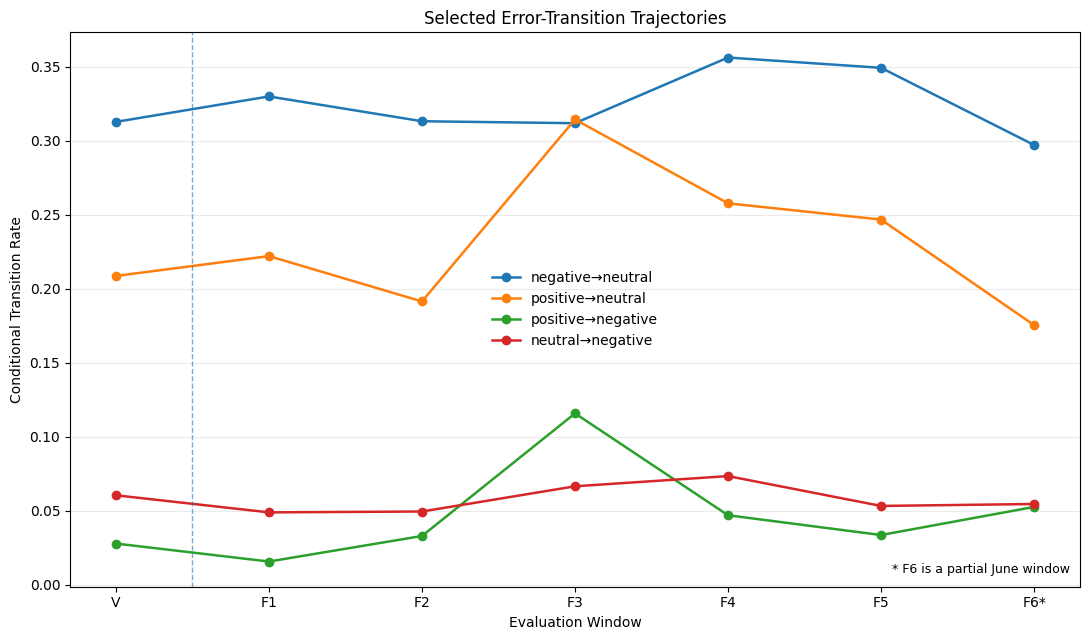

DAY 17 — ERROR-TRANSITION TRAJECTORY FIGURE CHECKPOINT
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/figures/selected_error_transition_trajectories.png
Exists: True
Size  : 275,172 bytes
--------------------------------------------------------------------------------------------------------------
PASS — four_selected_transitions
PASS — seven_periods_per_transition
PASS — priority_transition_included
PASS — figure_exists
PASS — figure_nonempty
--------------------------------------------------------------------------------------------------------------
PASS — selected_error_transition_trajectories.png created


In [ ]:

# Selected error-transition trajectories across V + F1–F6

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRANSITION_TRAJECTORY_FIGURE_PATH = (
    FIGURE_DIR / "selected_error_transition_trajectories.png"
)

SELECTED_TRANSITIONS = [
    "negative→neutral",   # pre-specified priority mode
    "positive→neutral",
    "positive→negative",
    "neutral→negative",
]

# ------------------------------------------------------------
# 1. Prepare plotting table
# ------------------------------------------------------------
transition_plot = (
    transition_diagnostic_export.loc[
        transition_diagnostic_export[
            "transition"
        ].isin(
            SELECTED_TRANSITIONS
        ),
        [
            "period",
            "transition",
            "conditional_rate",
        ],
    ]
    .copy()
)

period_order_map = {
    p: i
    for i, p in enumerate(EVAL_PERIOD_ORDER)
}

transition_order_map = {
    t: i
    for i, t in enumerate(SELECTED_TRANSITIONS)
}

transition_plot["_period_order"] = (
    transition_plot["period"]
    .map(period_order_map)
)

transition_plot["_transition_order"] = (
    transition_plot["transition"]
    .map(transition_order_map)
)

transition_plot = (
    transition_plot
    .sort_values(
        [
            "_transition_order",
            "_period_order",
        ]
    )
    .drop(
        columns=[
            "_period_order",
            "_transition_order",
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 2. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(11, 6.5)
)

x = np.arange(
    len(EVAL_PERIOD_ORDER)
)

for transition in SELECTED_TRANSITIONS:

    d = (
        transition_plot.loc[
            transition_plot[
                "transition"
            ] == transition
        ]
        .set_index("period")
        .reindex(EVAL_PERIOD_ORDER)
        .reset_index()
    )

    ax.plot(
        x,
        d["conditional_rate"].to_numpy(),
        marker="o",
        linewidth=1.8,
        markersize=6,
        label=transition,
    )

# Historical/future separator
ax.axvline(
    x=0.5,
    linestyle="--",
    linewidth=1,
    alpha=0.6,
)

ax.set_xticks(x)

ax.set_xticklabels([
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6*",
])

ax.set_xlabel(
    "Evaluation Window"
)

ax.set_ylabel(
    "Conditional Transition Rate"
)

ax.set_title(
    "Selected Error-Transition Trajectories"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    frameon=False
)

# ------------------------------------------------------------
# 3. F6 caveat
# ------------------------------------------------------------
ax.text(
    0.99,
    0.02,
    "* F6 is a partial June window",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)

fig.tight_layout()

fig.savefig(
    TRANSITION_TRAJECTORY_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 4. Artifact verification
# ------------------------------------------------------------
figure_exists = (
    TRANSITION_TRAJECTORY_FIGURE_PATH.exists()
)

figure_size = (
    TRANSITION_TRAJECTORY_FIGURE_PATH.stat().st_size
    if figure_exists
    else 0
)

checks = {
    "four_selected_transitions":
        transition_plot[
            "transition"
        ].nunique() == 4,

    "seven_periods_per_transition":
        all(
            (
                transition_plot[
                    "transition"
                ] == transition
            ).sum() == 7
            for transition in SELECTED_TRANSITIONS
        ),

    "priority_transition_included":
        "negative→neutral"
        in set(
            transition_plot[
                "transition"
            ]
        ),

    "figure_exists":
        figure_exists,

    "figure_nonempty":
        figure_size > 0,
}

print("=" * 110)
print("DAY 17 — ERROR-TRANSITION TRAJECTORY FIGURE CHECKPOINT")
print("=" * 110)

print(f"Saved : {TRANSITION_TRAJECTORY_FIGURE_PATH}")
print(f"Exists: {figure_exists}")
print(f"Size  : {figure_size:,} bytes")

print("-" * 110)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 110)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Transition trajectory figure checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — selected_error_transition_trajectories.png created"
)
print("=" * 110)

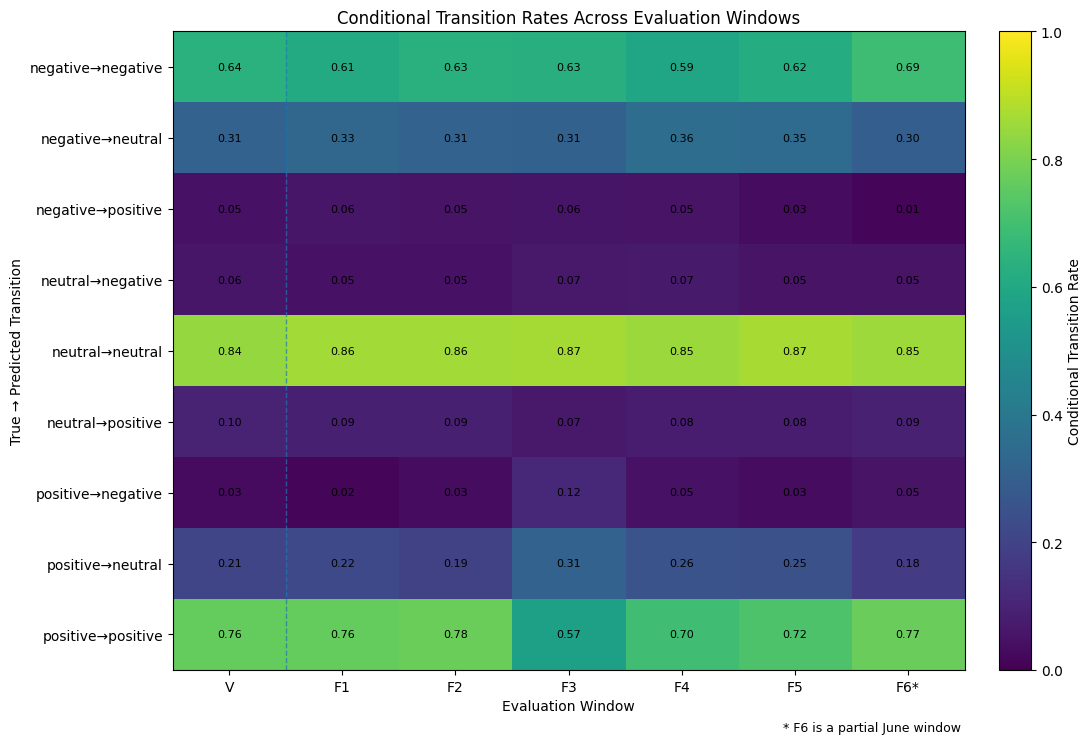

DAY 17 — TRANSITION HEATMAP CHECKPOINT
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/figures/transition_rate_heatmap.png
Exists: True
Size  : 298,890 bytes
--------------------------------------------------------------------------------------------------------------
PASS — matrix_shape_9_by_7
PASS — no_missing_heatmap_cells
PASS — all_rates_between_0_and_1
PASS — figure_exists
PASS — figure_nonempty
--------------------------------------------------------------------------------------------------------------
PASS — transition_rate_heatmap.png created


In [ ]:
# Full transition heatmap:
# all 9 true→predicted conditional transition rates
# across V + F1–F6

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TRANSITION_HEATMAP_PATH = (
    FIGURE_DIR / "transition_rate_heatmap.png"
)

# ------------------------------------------------------------
# 1. Prepare heatmap matrix
# ------------------------------------------------------------
transition_heatmap_table = (
    transition_diagnostic_export[
        [
            "period",
            "transition",
            "conditional_rate",
        ]
    ]
    .copy()
)

TRANSITION_ORDER = [
    "negative→negative",
    "negative→neutral",
    "negative→positive",
    "neutral→negative",
    "neutral→neutral",
    "neutral→positive",
    "positive→negative",
    "positive→neutral",
    "positive→positive",
]

heatmap_matrix = (
    transition_heatmap_table
    .pivot(
        index="transition",
        columns="period",
        values="conditional_rate",
    )
    .reindex(
        index=TRANSITION_ORDER,
        columns=EVAL_PERIOD_ORDER,
    )
)

# ------------------------------------------------------------
# 2. Formal matrix checks
# ------------------------------------------------------------
checks_preplot = {
    "matrix_shape_9_by_7":
        heatmap_matrix.shape == (9, 7),

    "no_missing_heatmap_cells":
        not heatmap_matrix.isna().any().any(),

    "all_rates_between_0_and_1":
        bool(
            (
                (heatmap_matrix >= 0)
                &
                (heatmap_matrix <= 1)
            ).all().all()
        ),
}

if not all(checks_preplot.values()):
    failed = [
        name
        for name, status in checks_preplot.items()
        if not status
    ]

    raise AssertionError(
        "Transition heatmap matrix construction failed: "
        + ", ".join(failed)
    )

# ------------------------------------------------------------
# 3. Plot
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(11, 7.5)
)

image = ax.imshow(
    heatmap_matrix.to_numpy(),
    aspect="auto",
    vmin=0,
    vmax=1,
)

# Axis labels
ax.set_xticks(
    np.arange(
        len(EVAL_PERIOD_ORDER)
    )
)

ax.set_xticklabels([
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6*",
])

ax.set_yticks(
    np.arange(
        len(TRANSITION_ORDER)
    )
)

ax.set_yticklabels(
    TRANSITION_ORDER
)

ax.set_xlabel(
    "Evaluation Window"
)

ax.set_ylabel(
    "True → Predicted Transition"
)

ax.set_title(
    "Conditional Transition Rates Across Evaluation Windows"
)

# ------------------------------------------------------------
# 4. Annotate cell values
# ------------------------------------------------------------
for i in range(
    len(TRANSITION_ORDER)
):
    for j in range(
        len(EVAL_PERIOD_ORDER)
    ):

        value = heatmap_matrix.iloc[i, j]

        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
        )

# ------------------------------------------------------------
# 5. Historical/future separator
# ------------------------------------------------------------
ax.axvline(
    x=0.5,
    linestyle="--",
    linewidth=1,
    alpha=0.7,
)

# ------------------------------------------------------------
# 6. Colorbar
# ------------------------------------------------------------
cbar = fig.colorbar(
    image,
    ax=ax,
    fraction=0.046,
    pad=0.04,
)

cbar.set_label(
    "Conditional Transition Rate"
)

# F6 caveat
ax.text(
    0.995,
    -0.08,
    "* F6 is a partial June window",
    transform=ax.transAxes,
    ha="right",
    va="top",
    fontsize=9,
)

fig.tight_layout()

fig.savefig(
    TRANSITION_HEATMAP_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 7. Artifact verification
# ------------------------------------------------------------
figure_exists = (
    TRANSITION_HEATMAP_PATH.exists()
)

figure_size = (
    TRANSITION_HEATMAP_PATH.stat().st_size
    if figure_exists
    else 0
)

checks = {
    **checks_preplot,

    "figure_exists":
        figure_exists,

    "figure_nonempty":
        figure_size > 0,
}

print("=" * 110)
print("DAY 17 — TRANSITION HEATMAP CHECKPOINT")
print("=" * 110)

print(f"Saved : {TRANSITION_HEATMAP_PATH}")
print(f"Exists: {figure_exists}")
print(f"Size  : {figure_size:,} bytes")

print("-" * 110)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 110)

if not all(checks.values()):
    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Transition heatmap checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — transition_rate_heatmap.png created"
)
print("=" * 110)

In [ ]:
# Stage D final checkpoint
STAGE_D_REQUIRED_ARTIFACTS = {
    "transition_diagnostic_summary.csv":
        TRANSITION_DIAGNOSTIC_PATH,

    "selected_error_transition_trajectories.png":
        TRANSITION_TRAJECTORY_FIGURE_PATH,

    "transition_rate_heatmap.png":
        TRANSITION_HEATMAP_PATH,
}

print("=" * 110)
print("DAY 17 — STAGE D FINAL CHECKPOINT")
print("=" * 110)

artifact_checks = {}

for name, path in STAGE_D_REQUIRED_ARTIFACTS.items():

    exists = path.exists()

    size = (
        path.stat().st_size
        if exists
        else 0
    )

    artifact_checks[name] = (
        exists and size > 0
    )

    print(
        f"{'PASS' if artifact_checks[name] else 'FAIL':4s}"
        f" — {name:<45s}"
        f"{size:>12,} bytes"
    )

print("-" * 110)

stage_d_checks = {
    "transition_summary_rows_63":
        len(
            transition_diagnostic_export
        ) == 63,

    "nine_transition_types":
        transition_diagnostic_export[
            "transition"
        ].nunique() == 9,

    "nine_cells_per_period":
        all(
            (
                transition_diagnostic_export[
                    "period"
                ] == p
            ).sum() == 9
            for p in EVAL_PERIOD_ORDER
        ),

    "priority_negative_to_neutral_retained":
        (
            transition_diagnostic_export[
                "transition"
            ] == "negative→neutral"
        ).sum() == 7,

    "key_F3_F4_F5_contrast_present":
        set(
            key_transition_diagnostics[
                "period"
            ].astype(str)
        ) == {"F3", "F4", "F5"},

    "all_stage_D_artifacts_present":
        all(
            artifact_checks.values()
        ),
}

for name, status in stage_d_checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 110)

if not all(stage_d_checks.values()):

    failed = [
        name
        for name, status in stage_d_checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage D final checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — STAGE D TRANSITION-LEVEL "
    "ERROR DIAGNOSIS COMPLETE"
)

print("=" * 110)

DAY 17 — STAGE D FINAL CHECKPOINT
PASS — transition_diagnostic_summary.csv                  10,828 bytes
PASS — selected_error_transition_trajectories.png        275,172 bytes
PASS — transition_rate_heatmap.png                       298,890 bytes
--------------------------------------------------------------------------------------------------------------
PASS — transition_summary_rows_63
PASS — nine_transition_types
PASS — nine_cells_per_period
PASS — priority_negative_to_neutral_retained
PASS — key_F3_F4_F5_contrast_present
PASS — all_stage_D_artifacts_present
--------------------------------------------------------------------------------------------------------------
PASS — STAGE D TRANSITION-LEVEL ERROR DIAGNOSIS COMPLETE


## Stage E — True-Label and Prediction-Composition Diagnosis

This stage evaluates whether the temporal performance pattern co-occurs with changes in:

- the benchmark true-label composition,
- the model's predicted-label composition,
- directional prediction-minus-true class-share differences,
- distributional distance from Historical Validation and F1,
- the gap between Macro-F1 and Weighted-F1.

For each class \(c\) and period \(k\):

\[
\text{Prediction Share Gap}_{k,c}
=
P(\hat y=c \mid k)
-
P(y=c \mid k).
\]

Distribution shift is summarized using total variation distance:

\[
\operatorname{TVD}(P,Q)
=
\frac{1}{2}\sum_c |P_c-Q_c|.
\]

These quantities are descriptive diagnostics. They do not identify label composition or prediction composition as causal explanations of temporal performance changes.

In [ ]:
# Build true-label / predicted-label composition diagnostics
# for V + F1–F6
#
# Corrected version:
# avoid pandas merge() for window-level summary assembly.

import numpy as np
import pandas as pd

from sklearn.metrics import f1_score


# ------------------------------------------------------------
# 1. Build per-period true/predicted class distributions
# ------------------------------------------------------------
composition_rows = []

for period in EVAL_PERIOD_ORDER:

    d = (
        evaluation_population.loc[
            evaluation_population["period"] == period
        ]
        .copy()
    )

    n = len(d)

    for label in LABEL_ORDER:

        true_count = int(
            (d["y_true"] == label).sum()
        )

        predicted_count = int(
            (d["y_pred"] == label).sum()
        )

        true_share = (
            true_count / n
        )

        predicted_share = (
            predicted_count / n
        )

        composition_rows.append({
            "period": period,

            "period_type":
                d["period_type"].iloc[0],

            "label": label,

            "n": n,

            "true_count":
                true_count,

            "true_share":
                true_share,

            "predicted_count":
                predicted_count,

            "predicted_share":
                predicted_share,

            "predicted_minus_true_share":
                predicted_share - true_share,
        })


label_prediction_shift = pd.DataFrame(
    composition_rows
)


# ------------------------------------------------------------
# 2. Explicit ordering
# ------------------------------------------------------------
period_order_map = {
    period: i
    for i, period in enumerate(
        EVAL_PERIOD_ORDER
    )
}

label_order_map = {
    label: i
    for i, label in enumerate(
        LABEL_ORDER
    )
}

label_prediction_shift[
    "_period_order"
] = (
    label_prediction_shift[
        "period"
    ].map(period_order_map)
)

label_prediction_shift[
    "_label_order"
] = (
    label_prediction_shift[
        "label"
    ].map(label_order_map)
)

label_prediction_shift = (
    label_prediction_shift
    .sort_values(
        [
            "_period_order",
            "_label_order",
        ]
    )
    .drop(
        columns=[
            "_period_order",
            "_label_order",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 3. Wide true/predicted distribution tables
# ------------------------------------------------------------
true_share_wide = (
    label_prediction_shift
    .pivot(
        index="period",
        columns="label",
        values="true_share",
    )
    .reindex(
        index=EVAL_PERIOD_ORDER,
        columns=LABEL_ORDER,
    )
)

pred_share_wide = (
    label_prediction_shift
    .pivot(
        index="period",
        columns="label",
        values="predicted_share",
    )
    .reindex(
        index=EVAL_PERIOD_ORDER,
        columns=LABEL_ORDER,
    )
)


# ------------------------------------------------------------
# 4. TVD helper
# ------------------------------------------------------------
def total_variation_distance(p, q):

    p = np.asarray(
        p,
        dtype=float,
    )

    q = np.asarray(
        q,
        dtype=float,
    )

    return float(
        0.5
        * np.abs(
            p - q
        ).sum()
    )


# ------------------------------------------------------------
# 5. Reference distributions
# ------------------------------------------------------------
true_v = (
    true_share_wide
    .loc["V"]
    .to_numpy()
)

true_f1 = (
    true_share_wide
    .loc["F1"]
    .to_numpy()
)

pred_v = (
    pred_share_wide
    .loc["V"]
    .to_numpy()
)

pred_f1 = (
    pred_share_wide
    .loc["F1"]
    .to_numpy()
)


# ------------------------------------------------------------
# 6. TVD vs V and vs F1
# ------------------------------------------------------------
distribution_shift_rows = []

for period in EVAL_PERIOD_ORDER:

    true_current = (
        true_share_wide
        .loc[period]
        .to_numpy()
    )

    pred_current = (
        pred_share_wide
        .loc[period]
        .to_numpy()
    )

    distribution_shift_rows.append({
        "period":
            period,

        "true_tvd_vs_V":
            total_variation_distance(
                true_current,
                true_v,
            ),

        "true_tvd_vs_F1":
            total_variation_distance(
                true_current,
                true_f1,
            ),

        "predicted_tvd_vs_V":
            total_variation_distance(
                pred_current,
                pred_v,
            ),

        "predicted_tvd_vs_F1":
            total_variation_distance(
                pred_current,
                pred_f1,
            ),
    })


distribution_shift_summary = pd.DataFrame(
    distribution_shift_rows
)


# ------------------------------------------------------------
# 7. Macro-F1 vs Weighted-F1 gap
# ------------------------------------------------------------
performance_gap_rows = []

for period in EVAL_PERIOD_ORDER:

    d = evaluation_population.loc[
        evaluation_population["period"] == period
    ]

    macro_f1 = float(
        f1_score(
            d["y_true"],
            d["y_pred"],
            labels=LABEL_ORDER,
            average="macro",
            zero_division=0,
        )
    )

    weighted_f1 = float(
        f1_score(
            d["y_true"],
            d["y_pred"],
            labels=LABEL_ORDER,
            average="weighted",
            zero_division=0,
        )
    )

    performance_gap_rows.append({
        "period":
            period,

        "macro_f1":
            macro_f1,

        "weighted_f1":
            weighted_f1,

        "weighted_minus_macro_f1":
            weighted_f1 - macro_f1,

        "macro_minus_weighted_f1":
            macro_f1 - weighted_f1,
    })


macro_vs_weighted_gap = pd.DataFrame(
    performance_gap_rows
)


# ------------------------------------------------------------
# 8. Assemble window-level summary WITHOUT merge()
#
# Both tables are explicitly indexed and aligned by
# EVAL_PERIOD_ORDER.
# ------------------------------------------------------------
distribution_indexed = (
    distribution_shift_summary
    .set_index("period")
    .reindex(EVAL_PERIOD_ORDER)
)

gap_indexed = (
    macro_vs_weighted_gap
    .set_index("period")
    .reindex(EVAL_PERIOD_ORDER)
)

composition_window_summary = (
    pd.concat(
        [
            distribution_indexed,
            gap_indexed,
        ],
        axis=1,
    )
    .reset_index()
    .rename(
        columns={
            "index": "period"
        }
    )
)


# ------------------------------------------------------------
# 9. Distribution normalization checks
# ------------------------------------------------------------
true_share_sum = (
    label_prediction_shift
    .groupby(
        "period",
        observed=False,
    )["true_share"]
    .sum()
    .reindex(
        EVAL_PERIOD_ORDER
    )
)

pred_share_sum = (
    label_prediction_shift
    .groupby(
        "period",
        observed=False,
    )["predicted_share"]
    .sum()
    .reindex(
        EVAL_PERIOD_ORDER
    )
)


# ------------------------------------------------------------
# 10. Formal checks
# ------------------------------------------------------------
checks = {

    "composition_table_has_21_rows":
        len(
            label_prediction_shift
        ) == 21,

    "three_labels_per_period":
        all(
            (
                label_prediction_shift[
                    "period"
                ] == period
            ).sum() == 3
            for period in EVAL_PERIOD_ORDER
        ),

    "true_shares_sum_to_one":
        bool(
            np.allclose(
                true_share_sum.to_numpy(),
                1.0,
                atol=1e-12,
            )
        ),

    "predicted_shares_sum_to_one":
        bool(
            np.allclose(
                pred_share_sum.to_numpy(),
                1.0,
                atol=1e-12,
            )
        ),

    "seven_distribution_shift_rows":
        len(
            distribution_shift_summary
        ) == 7,

    "seven_metric_gap_rows":
        len(
            macro_vs_weighted_gap
        ) == 7,

    "seven_window_summary_rows":
        len(
            composition_window_summary
        ) == 7,

    "window_summary_order_correct":
        composition_window_summary[
            "period"
        ].tolist()
        == EVAL_PERIOD_ORDER,

    "V_TVD_vs_V_zero":
        (
            np.isclose(
                float(
                    composition_window_summary.loc[
                        composition_window_summary[
                            "period"
                        ] == "V",
                        "true_tvd_vs_V",
                    ].iloc[0]
                ),
                0.0,
                atol=1e-12,
            )
            and
            np.isclose(
                float(
                    composition_window_summary.loc[
                        composition_window_summary[
                            "period"
                        ] == "V",
                        "predicted_tvd_vs_V",
                    ].iloc[0]
                ),
                0.0,
                atol=1e-12,
            )
        ),

    "F1_TVD_vs_F1_zero":
        (
            np.isclose(
                float(
                    composition_window_summary.loc[
                        composition_window_summary[
                            "period"
                        ] == "F1",
                        "true_tvd_vs_F1",
                    ].iloc[0]
                ),
                0.0,
                atol=1e-12,
            )
            and
            np.isclose(
                float(
                    composition_window_summary.loc[
                        composition_window_summary[
                            "period"
                        ] == "F1",
                        "predicted_tvd_vs_F1",
                    ].iloc[0]
                ),
                0.0,
                atol=1e-12,
            )
        ),

    "no_missing_window_summary_values":
        not composition_window_summary[
            [
                "true_tvd_vs_V",
                "true_tvd_vs_F1",
                "predicted_tvd_vs_V",
                "predicted_tvd_vs_F1",
                "macro_f1",
                "weighted_f1",
                "weighted_minus_macro_f1",
            ]
        ].isna().any().any(),
}


# ------------------------------------------------------------
# 11. Display
# ------------------------------------------------------------
print("=" * 150)
print("DAY 17 — LABEL / PREDICTION COMPOSITION DIAGNOSIS")
print("=" * 150)

print(
    "\n[Class-level true vs predicted composition]"
)

print(
    label_prediction_shift[
        [
            "period",
            "label",
            "n",
            "true_count",
            "true_share",
            "predicted_count",
            "predicted_share",
            "predicted_minus_true_share",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print(
    "\n[Distribution-shift and metric-gap summary]"
)

print(
    composition_window_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "-" * 150)

for name, status in checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s}"
        f" — {name}"
    )

print("-" * 150)

if not all(
    checks.values()
):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage E composition diagnostic "
        "construction failed: "
        + ", ".join(failed)
    )

print(
    "PASS — true-label / predicted-label composition "
    "diagnostics constructed"
)

print("=" * 150)

DAY 17 — LABEL / PREDICTION COMPOSITION DIAGNOSIS

[Class-level true vs predicted composition]
period    label    n  true_count  true_share  predicted_count  predicted_share  predicted_minus_true_share
     V negative 5859        1132    0.193207              976         0.166581                   -0.026626
     V  neutral 5859        3687    0.629288             3676         0.627411                   -0.001877
     V positive 5859        1040    0.177505             1207         0.206008                    0.028503
    F1 negative 3602         679    0.188506              536         0.148806                   -0.039700
    F1  neutral 3602        2288    0.635203             2340         0.649639                    0.014436
    F1 positive 3602         635    0.176291              726         0.201555                    0.025264
    F2 negative 3522         776    0.220329              618         0.175468                   -0.044861
    F2  neutral 3522        2140    0.607609     

In [ ]:
import pandas as pd

LABEL_PREDICTION_SHIFT_PATH = (
    DAY17_DIR / "label_prediction_shift.csv"
)

MACRO_WEIGHTED_GAP_PATH = (
    DAY17_DIR / "macro_vs_weighted_gap.csv"
)

# ------------------------------------------------------------
# 1. Attach window-level TVD / performance-gap diagnostics
#    to each class-level composition row
# ------------------------------------------------------------
window_summary_lookup = (
    composition_window_summary
    .set_index("period")
)

label_prediction_export = (
    label_prediction_shift.copy()
)

# Convert categoricals if present
label_prediction_export["period"] = (
    label_prediction_export["period"].astype(str)
)

label_prediction_export["label"] = (
    label_prediction_export["label"].astype(str)
)

for col in [
    "true_tvd_vs_V",
    "true_tvd_vs_F1",
    "predicted_tvd_vs_V",
    "predicted_tvd_vs_F1",
    "macro_f1",
    "weighted_f1",
    "weighted_minus_macro_f1",
    "macro_minus_weighted_f1",
]:
    label_prediction_export[col] = (
        label_prediction_export["period"]
        .map(
            window_summary_lookup[col]
            .to_dict()
        )
    )

# ------------------------------------------------------------
# 2. Final column order
# ------------------------------------------------------------
label_prediction_export = (
    label_prediction_export[
        [
            "period",
            "period_type",
            "label",
            "n",
            "true_count",
            "true_share",
            "predicted_count",
            "predicted_share",
            "predicted_minus_true_share",
            "true_tvd_vs_V",
            "true_tvd_vs_F1",
            "predicted_tvd_vs_V",
            "predicted_tvd_vs_F1",
            "macro_f1",
            "weighted_f1",
            "weighted_minus_macro_f1",
            "macro_minus_weighted_f1",
        ]
    ]
)

# ------------------------------------------------------------
# 3. Save main Stage E artifact
# ------------------------------------------------------------
label_prediction_export.to_csv(
    LABEL_PREDICTION_SHIFT_PATH,
    index=False,
)

# ------------------------------------------------------------
# 4. Save compact Macro-vs-Weighted gap artifact
# ------------------------------------------------------------
macro_vs_weighted_export = (
    composition_window_summary[
        [
            "period",
            "macro_f1",
            "weighted_f1",
            "weighted_minus_macro_f1",
            "macro_minus_weighted_f1",
        ]
    ]
    .copy()
)

macro_vs_weighted_export.to_csv(
    MACRO_WEIGHTED_GAP_PATH,
    index=False,
)

# ------------------------------------------------------------
# 5. Reload and verify
# ------------------------------------------------------------
reloaded_label_shift = pd.read_csv(
    LABEL_PREDICTION_SHIFT_PATH
)

reloaded_gap = pd.read_csv(
    MACRO_WEIGHTED_GAP_PATH
)

main_exists = (
    LABEL_PREDICTION_SHIFT_PATH.exists()
)

gap_exists = (
    MACRO_WEIGHTED_GAP_PATH.exists()
)

main_size = (
    LABEL_PREDICTION_SHIFT_PATH.stat().st_size
    if main_exists
    else 0
)

gap_size = (
    MACRO_WEIGHTED_GAP_PATH.stat().st_size
    if gap_exists
    else 0
)

checks = {
    "label_prediction_artifact_exists":
        main_exists,

    "label_prediction_artifact_nonempty":
        main_size > 0,

    "label_prediction_rows_21":
        len(reloaded_label_shift) == 21,

    "seven_periods":
        set(
            reloaded_label_shift[
                "period"
            ].unique()
        ) == set(EVAL_PERIOD_ORDER),

    "three_labels":
        set(
            reloaded_label_shift[
                "label"
            ].unique()
        ) == set(LABEL_ORDER),

    "no_missing_composition_fields":
        not reloaded_label_shift[
            [
                "true_share",
                "predicted_share",
                "predicted_minus_true_share",
                "true_tvd_vs_F1",
                "predicted_tvd_vs_F1",
                "weighted_minus_macro_f1",
            ]
        ].isna().any().any(),

    "macro_weighted_gap_artifact_exists":
        gap_exists,

    "macro_weighted_gap_rows_7":
        len(reloaded_gap) == 7,
}

print("=" * 110)
print("DAY 17 — STAGE E COMPOSITION ARTIFACTS")
print("=" * 110)

print(
    f"Saved : {LABEL_PREDICTION_SHIFT_PATH}"
)
print(
    f"Size  : {main_size:,} bytes"
)

print(
    f"\nSaved : {MACRO_WEIGHTED_GAP_PATH}"
)
print(
    f"Size  : {gap_size:,} bytes"
)

print("-" * 110)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 110)

if not all(checks.values()):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage E composition artifact checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — Stage E composition artifacts frozen"
)

print("=" * 110)

DAY 17 — STAGE E COMPOSITION ARTIFACTS
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/label_prediction_shift.csv
Size  : 5,438 bytes

Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/macro_vs_weighted_gap.csv
Size  : 655 bytes
--------------------------------------------------------------------------------------------------------------
PASS — label_prediction_artifact_exists
PASS — label_prediction_artifact_nonempty
PASS — label_prediction_rows_21
PASS — seven_periods
PASS — three_labels
PASS — no_missing_composition_fields
PASS — macro_weighted_gap_artifact_exists
PASS — macro_weighted_gap_rows_7
--------------------------------------------------------------------------------------------------------------
PASS — Stage E composition artifacts frozen


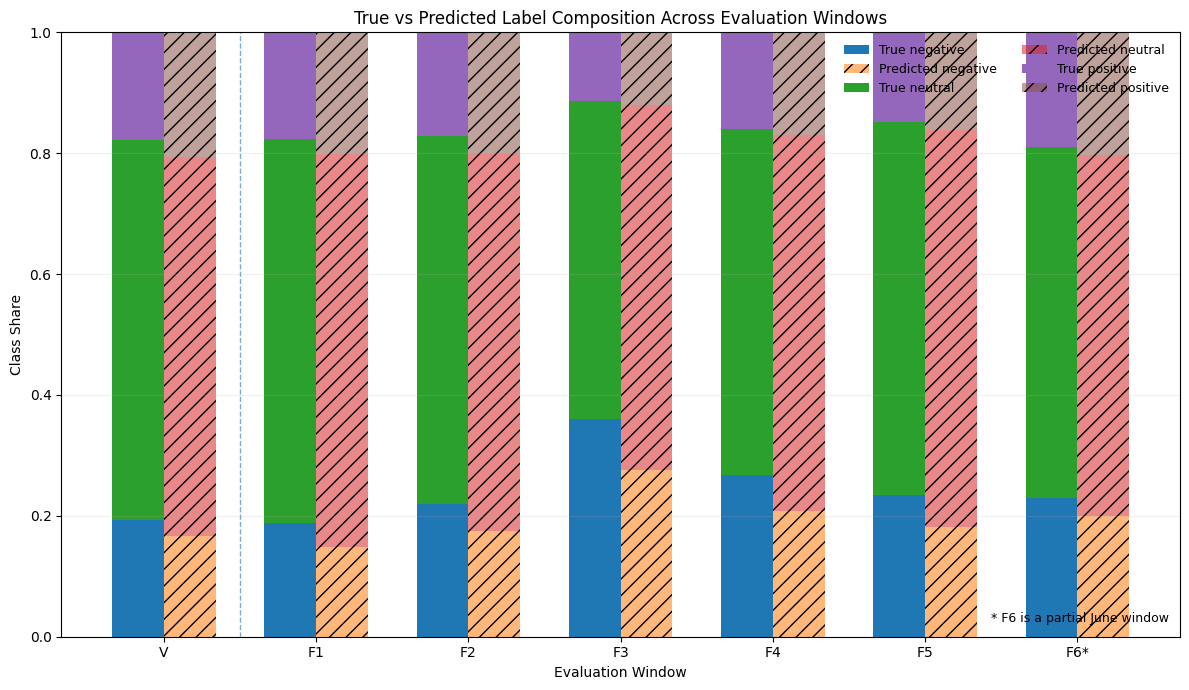

DAY 17 — LABEL / PREDICTION COMPOSITION FIGURE CHECKPOINT
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/figures/label_prediction_composition.png
Exists: True
Size  : 228,071 bytes
--------------------------------------------------------------------------------------------------------------
PASS — true_matrix_shape_7_by_3
PASS — pred_matrix_shape_7_by_3
PASS — true_composition_sums_to_one
PASS — predicted_composition_sums_to_one
PASS — figure_exists
PASS — figure_nonempty
--------------------------------------------------------------------------------------------------------------
PASS — label_prediction_composition.png created


In [ ]:
# True vs predicted label composition across V + F1–F6
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LABEL_COMPOSITION_FIGURE_PATH = (
    FIGURE_DIR / "label_prediction_composition.png"
)

# ------------------------------------------------------------
# 1. Prepare plotting tables
# ------------------------------------------------------------
plot_df = (
    label_prediction_export[
        [
            "period",
            "label",
            "true_share",
            "predicted_share",
        ]
    ]
    .copy()
)

true_comp = (
    plot_df
    .pivot(
        index="period",
        columns="label",
        values="true_share",
    )
    .reindex(
        index=EVAL_PERIOD_ORDER,
        columns=LABEL_ORDER,
    )
)

pred_comp = (
    plot_df
    .pivot(
        index="period",
        columns="label",
        values="predicted_share",
    )
    .reindex(
        index=EVAL_PERIOD_ORDER,
        columns=LABEL_ORDER,
    )
)

# ------------------------------------------------------------
# 2. Plot as paired stacked bars
# ------------------------------------------------------------
fig, ax = plt.subplots(
    figsize=(12, 7)
)

x = np.arange(
    len(EVAL_PERIOD_ORDER)
)

bar_width = 0.34

true_bottom = np.zeros(
    len(EVAL_PERIOD_ORDER)
)

pred_bottom = np.zeros(
    len(EVAL_PERIOD_ORDER)
)

for label in LABEL_ORDER:

    true_vals = (
        true_comp[label]
        .to_numpy()
    )

    pred_vals = (
        pred_comp[label]
        .to_numpy()
    )

    ax.bar(
        x - bar_width / 2,
        true_vals,
        width=bar_width,
        bottom=true_bottom,
        label=f"True {label}",
    )

    ax.bar(
        x + bar_width / 2,
        pred_vals,
        width=bar_width,
        bottom=pred_bottom,
        alpha=0.55,
        hatch="//",
        label=f"Predicted {label}",
    )

    true_bottom += true_vals
    pred_bottom += pred_vals

# Historical/future separator
ax.axvline(
    x=0.5,
    linestyle="--",
    linewidth=1,
    alpha=0.6,
)

ax.set_xticks(x)

ax.set_xticklabels([
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6*",
])

ax.set_xlabel(
    "Evaluation Window"
)

ax.set_ylabel(
    "Class Share"
)

ax.set_ylim(
    0,
    1.0,
)

ax.set_title(
    "True vs Predicted Label Composition Across Evaluation Windows"
)

ax.grid(
    axis="y",
    alpha=0.2,
)

# Two-column legend to keep the plot readable
ax.legend(
    frameon=False,
    ncol=2,
    fontsize=9,
)

# F6 caveat
ax.text(
    0.99,
    0.02,
    "* F6 is a partial June window",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)

fig.tight_layout()

fig.savefig(
    LABEL_COMPOSITION_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 3. Artifact verification
# ------------------------------------------------------------
figure_exists = (
    LABEL_COMPOSITION_FIGURE_PATH.exists()
)

figure_size = (
    LABEL_COMPOSITION_FIGURE_PATH.stat().st_size
    if figure_exists
    else 0
)

checks = {
    "true_matrix_shape_7_by_3":
        true_comp.shape == (7, 3),

    "pred_matrix_shape_7_by_3":
        pred_comp.shape == (7, 3),

    "true_composition_sums_to_one":
        bool(
            np.allclose(
                true_comp.sum(axis=1).to_numpy(),
                1.0,
                atol=1e-12,
            )
        ),

    "predicted_composition_sums_to_one":
        bool(
            np.allclose(
                pred_comp.sum(axis=1).to_numpy(),
                1.0,
                atol=1e-12,
            )
        ),

    "figure_exists":
        figure_exists,

    "figure_nonempty":
        figure_size > 0,
}

print("=" * 110)
print("DAY 17 — LABEL / PREDICTION COMPOSITION FIGURE CHECKPOINT")
print("=" * 110)

print(f"Saved : {LABEL_COMPOSITION_FIGURE_PATH}")
print(f"Exists: {figure_exists}")
print(f"Size  : {figure_size:,} bytes")

print("-" * 110)

for name, status in checks.items():
    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 110)

if not all(checks.values()):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Label/prediction composition figure checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — label_prediction_composition.png created"
)

print("=" * 110)

In [ ]:
# Stage E final checkpoint

STAGE_E_REQUIRED_ARTIFACTS = {
    "label_prediction_shift.csv":
        LABEL_PREDICTION_SHIFT_PATH,

    "macro_vs_weighted_gap.csv":
        MACRO_WEIGHTED_GAP_PATH,

    "label_prediction_composition.png":
        LABEL_COMPOSITION_FIGURE_PATH,
}

print("=" * 110)
print("DAY 17 — STAGE E FINAL CHECKPOINT")
print("=" * 110)

artifact_checks = {}

for name, path in STAGE_E_REQUIRED_ARTIFACTS.items():

    exists = path.exists()

    size = (
        path.stat().st_size
        if exists
        else 0
    )

    artifact_checks[name] = (
        exists and size > 0
    )

    print(
        f"{'PASS' if artifact_checks[name] else 'FAIL':4s}"
        f" — {name:<40s}"
        f"{size:>12,} bytes"
    )

print("-" * 110)

stage_e_checks = {
    "composition_rows_21":
        len(label_prediction_export) == 21,

    "seven_periods":
        set(
            label_prediction_export[
                "period"
            ].unique()
        ) == set(EVAL_PERIOD_ORDER),

    "three_labels":
        set(
            label_prediction_export[
                "label"
            ].unique()
        ) == set(LABEL_ORDER),

    "true_distribution_TVD_available":
        label_prediction_export[
            "true_tvd_vs_F1"
        ].notna().all(),

    "predicted_distribution_TVD_available":
        label_prediction_export[
            "predicted_tvd_vs_F1"
        ].notna().all(),

    "macro_weighted_gap_available":
        label_prediction_export[
            "weighted_minus_macro_f1"
        ].notna().all(),

    "F6_retained_as_partial":
        set(
            label_prediction_export.loc[
                label_prediction_export[
                    "period"
                ] == "F6",
                "period_type",
            ]
        ) == {"future_partial"},

    "all_stage_E_artifacts_present":
        all(
            artifact_checks.values()
        ),
}

for name, status in stage_e_checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 110)

if not all(stage_e_checks.values()):

    failed = [
        name
        for name, status in stage_e_checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage E final checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — STAGE E TRUE-LABEL / PREDICTION-"
    "COMPOSITION DIAGNOSIS COMPLETE"
)

print("=" * 110)

DAY 17 — STAGE E FINAL CHECKPOINT
PASS — label_prediction_shift.csv                     5,438 bytes
PASS — macro_vs_weighted_gap.csv                        655 bytes
PASS — label_prediction_composition.png             228,071 bytes
--------------------------------------------------------------------------------------------------------------
PASS — composition_rows_21
PASS — seven_periods
PASS — three_labels
PASS — true_distribution_TVD_available
PASS — predicted_distribution_TVD_available
PASS — macro_weighted_gap_available
PASS — F6_retained_as_partial
PASS — all_stage_E_artifacts_present
--------------------------------------------------------------------------------------------------------------
PASS — STAGE E TRUE-LABEL / PREDICTION-COMPOSITION DIAGNOSIS COMPLETE


## Stage F — Source Composition and Source-Conditional Performance

This stage evaluates whether the temporal performance pattern co-occurs with changes in source composition and/or source-specific model performance.

The analysis separates two descriptive mechanisms:

1. **Source-mix change**  
   Different windows may contain different proportions of sources.

2. **Within-source performance change**  
   Model performance may change within the same source across windows.

For each source × window cell, Day 17 records:

- support,
- source share,
- Accuracy,
- Macro-F1 when all three classes are represented,
- class recalls where defined,
- low-support status,
- contribution to total window errors.

Source-composition shift is summarized with total variation distance relative to Historical Validation and F1.

Source-standardized performance, if used later, is treated as a descriptive sensitivity analysis rather than a causal intervention.

In [ ]:
# Build unified source composition table for V + F1–F6

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Historical Validation source information
# ------------------------------------------------------------
validation_source = pd.DataFrame({
    "observation_id":
        validation_predictions[
            "observation_id"
        ].astype(str),

    "period":
        "V",

    "period_type":
        "historical_validation",

    "source":
        validation_predictions[
            "channel_username"
        ].astype(str),

    "y_true":
        validation_predictions[
            "true_label"
        ],

    "y_pred":
        validation_predictions[
            "predicted_label"
        ],
})

# ------------------------------------------------------------
# 2. Future source information
# ------------------------------------------------------------
future_source = (
    future_predictions[
        [
            "observation_id",
            "period",
            "period_type",
            "source",
            "y_true",
            "y_pred",
        ]
    ]
    .copy()
)

future_source[
    "observation_id"
] = (
    future_source[
        "observation_id"
    ].astype(str)
)

future_source[
    "source"
] = (
    future_source[
        "source"
    ].astype(str)
)

# ------------------------------------------------------------
# 3. Combine V + future
# ------------------------------------------------------------
source_evaluation_population = pd.concat(
    [
        validation_source,
        future_source,
    ],
    ignore_index=True,
)

# ------------------------------------------------------------
# 4. Determine complete source universe
# ------------------------------------------------------------
SOURCE_ORDER = sorted(
    source_evaluation_population[
        "source"
    ]
    .dropna()
    .unique()
    .tolist()
)

# ------------------------------------------------------------
# 5. Full period × source grid
# ------------------------------------------------------------
source_grid = (
    pd.MultiIndex.from_product(
        [
            EVAL_PERIOD_ORDER,
            SOURCE_ORDER,
        ],
        names=[
            "period",
            "source",
        ],
    )
    .to_frame(index=False)
)

# ------------------------------------------------------------
# 6. Count observations by source/window
# ------------------------------------------------------------
source_counts = (
    source_evaluation_population
    .groupby(
        [
            "period",
            "source",
        ],
        observed=False,
    )
    .size()
    .reset_index(
        name="count"
    )
)

source_composition = (
    source_grid
    .merge(
        source_counts,
        on=[
            "period",
            "source",
        ],
        how="left",
    )
)

source_composition[
    "count"
] = (
    source_composition[
        "count"
    ]
    .fillna(0)
    .astype(int)
)

# ------------------------------------------------------------
# 7. Add window totals and shares
# ------------------------------------------------------------
window_n_lookup = (
    source_evaluation_population
    .groupby(
        "period",
        observed=False,
    )
    .size()
    .to_dict()
)

source_composition[
    "window_n"
] = (
    source_composition[
        "period"
    ].map(
        window_n_lookup
    )
)

source_composition[
    "share"
] = (
    source_composition[
        "count"
    ]
    /
    source_composition[
        "window_n"
    ]
)

# ------------------------------------------------------------
# 8. Period type
# ------------------------------------------------------------
period_type_lookup = (
    source_evaluation_population[
        [
            "period",
            "period_type",
        ]
    ]
    .drop_duplicates()
    .set_index(
        "period"
    )[
        "period_type"
    ]
    .to_dict()
)

source_composition[
    "period_type"
] = (
    source_composition[
        "period"
    ].map(
        period_type_lookup
    )
)

# ------------------------------------------------------------
# 9. Source-share TVD vs V and F1
# ------------------------------------------------------------
source_share_wide = (
    source_composition
    .pivot(
        index="period",
        columns="source",
        values="share",
    )
    .reindex(
        index=EVAL_PERIOD_ORDER,
        columns=SOURCE_ORDER,
        fill_value=0,
    )
)

source_v = (
    source_share_wide
    .loc["V"]
    .to_numpy()
)

source_f1 = (
    source_share_wide
    .loc["F1"]
    .to_numpy()
)

source_shift_rows = []

for period in EVAL_PERIOD_ORDER:

    current = (
        source_share_wide
        .loc[period]
        .to_numpy()
    )

    source_shift_rows.append({
        "period":
            period,

        "source_tvd_vs_V":
            total_variation_distance(
                current,
                source_v,
            ),

        "source_tvd_vs_F1":
            total_variation_distance(
                current,
                source_f1,
            ),
    })

source_shift_summary = pd.DataFrame(
    source_shift_rows
)

# ------------------------------------------------------------
# 10. Integrity checks
# ------------------------------------------------------------
share_sum_check = (
    source_composition
    .groupby(
        "period",
        observed=False,
    )["share"]
    .sum()
    .reindex(
        EVAL_PERIOD_ORDER
    )
)

checks = {
    "seven_periods_present":
        set(
            source_evaluation_population[
                "period"
            ].unique()
        ) == set(EVAL_PERIOD_ORDER),

    "source_universe_nonempty":
        len(SOURCE_ORDER) > 0,

    "full_period_source_grid":
        len(
            source_composition
        )
        ==
        (
            len(EVAL_PERIOD_ORDER)
            * len(SOURCE_ORDER)
        ),

    "source_shares_sum_to_one":
        bool(
            np.allclose(
                share_sum_check.to_numpy(),
                1.0,
                atol=1e-12,
            )
        ),

    "seven_source_shift_rows":
        len(
            source_shift_summary
        ) == 7,

    "V_source_TVD_vs_V_zero":
        np.isclose(
            float(
                source_shift_summary.loc[
                    source_shift_summary[
                        "period"
                    ] == "V",
                    "source_tvd_vs_V",
                ].iloc[0]
            ),
            0.0,
            atol=1e-12,
        ),

    "F1_source_TVD_vs_F1_zero":
        np.isclose(
            float(
                source_shift_summary.loc[
                    source_shift_summary[
                        "period"
                    ] == "F1",
                    "source_tvd_vs_F1",
                ].iloc[0]
            ),
            0.0,
            atol=1e-12,
        ),
}

# ------------------------------------------------------------
# 11. Display
# ------------------------------------------------------------
print("=" * 150)
print("DAY 17 — SOURCE COMPOSITION DIAGNOSIS")
print("=" * 150)

print(
    f"\nUnique sources across V + F1–F6: "
    f"{len(SOURCE_ORDER)}"
)

print(
    "\n[Source universe]"
)
print(
    SOURCE_ORDER
)

print(
    "\n[Source composition by window]"
)

print(
    source_composition.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print(
    "\n[Source-share TVD summary]"
)

print(
    source_shift_summary.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "-" * 150)

for name, status in checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s} — {name}"
    )

print("-" * 150)

if not all(
    checks.values()
):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage F source composition construction failed: "
        + ", ".join(failed)
    )

print(
    "PASS — unified V + F1–F6 source composition "
    "diagnostics constructed"
)

print("=" * 150)

DAY 17 — SOURCE COMPOSITION DIAGNOSIS

Unique sources across V + F1–F6: 8

[Source universe]
['AGGRNEWSWIRE', 'MonitoringSituation', 'TreeNewsFeed', 'WalterBloomberg', 'ZoomerfiedNews', 'apewirenews', 'cukkanews', 'firstsquaw']

[Source composition by window]
period              source  count  window_n    share           period_type
     V        AGGRNEWSWIRE      9      5859 0.001536 historical_validation
     V MonitoringSituation     25      5859 0.004267 historical_validation
     V        TreeNewsFeed      5      5859 0.000853 historical_validation
     V     WalterBloomberg    725      5859 0.123741 historical_validation
     V      ZoomerfiedNews     16      5859 0.002731 historical_validation
     V         apewirenews      0      5859 0.000000 historical_validation
     V           cukkanews      4      5859 0.000683 historical_validation
     V          firstsquaw   5075      5859 0.866189 historical_validation
    F1        AGGRNEWSWIRE      5      3602 0.001388          fut

In [ ]:
# Source-conditional performance across V + F1–F6

import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    recall_score,
)

SOURCE_SUPPORT_THRESHOLD = 50

source_performance_rows = []

# 1. Window total error counts
window_error_count = {}

for period in EVAL_PERIOD_ORDER:

    d_window = source_evaluation_population.loc[
        source_evaluation_population["period"] == period
    ]

    window_error_count[period] = int(
        (
            d_window["y_true"]
            != d_window["y_pred"]
        ).sum()
    )


# ------------------------------------------------------------
# 2. Compute each period × source cell
# ------------------------------------------------------------
for period in EVAL_PERIOD_ORDER:

    for source in SOURCE_ORDER:

        d = source_evaluation_population.loc[
            (
                source_evaluation_population["period"]
                == period
            )
            &
            (
                source_evaluation_population["source"]
                == source
            )
        ].copy()

        n = len(d)

        period_type = (
            period_type_lookup[period]
        )

        # ----------------------------------------------------
        # Empty source/window cell
        # ----------------------------------------------------
        if n == 0:

            source_performance_rows.append({
                "period": period,
                "period_type": period_type,
                "source": source,
                "n": 0,

                "source_share":
                    0.0,

                "n_true_classes":
                    0,

                "all_three_true_classes_present":
                    False,

                "accuracy":
                    np.nan,

                "macro_f1":
                    np.nan,

                "negative_recall":
                    np.nan,

                "neutral_recall":
                    np.nan,

                "positive_recall":
                    np.nan,

                "negative_support":
                    0,

                "neutral_support":
                    0,

                "positive_support":
                    0,

                "error_count":
                    0,

                "window_error_count":
                    window_error_count[period],

                "error_contribution":
                    0.0,

                "low_support":
                    True,
            })

            continue

        # ----------------------------------------------------
        # Non-empty cell
        # ----------------------------------------------------
        y_true = d["y_true"]
        y_pred = d["y_pred"]

        true_class_counts = (
            y_true
            .value_counts()
            .reindex(
                LABEL_ORDER,
                fill_value=0,
            )
        )

        n_true_classes = int(
            (true_class_counts > 0).sum()
        )

        all_three_present = (
            n_true_classes == 3
        )

        accuracy = float(
            accuracy_score(
                y_true,
                y_pred,
            )
        )

        # Macro-F1 only when all three true classes are represented
        if all_three_present:
            macro_f1 = float(
                f1_score(
                    y_true,
                    y_pred,
                    labels=LABEL_ORDER,
                    average="macro",
                    zero_division=0,
                )
            )
        else:
            macro_f1 = np.nan

        # ----------------------------------------------------
        # Class recalls only where denominator exists
        # ----------------------------------------------------
        class_recalls = {}

        for label in LABEL_ORDER:

            support = int(
                true_class_counts[label]
            )

            if support > 0:

                recall_value = float(
                    recall_score(
                        y_true,
                        y_pred,
                        labels=[label],
                        average=None,
                        zero_division=0,
                    )[0]
                )

            else:
                recall_value = np.nan

            class_recalls[label] = (
                recall_value
            )

        # ----------------------------------------------------
        # Error contribution
        # ----------------------------------------------------
        error_count = int(
            (
                y_true
                != y_pred
            ).sum()
        )

        total_window_errors = (
            window_error_count[period]
        )

        error_contribution = (
            error_count
            / total_window_errors
            if total_window_errors > 0
            else np.nan
        )

        # ----------------------------------------------------
        # Source share
        # ----------------------------------------------------
        source_share = (
            n
            / int(
                window_n_lookup[
                    period
                ]
            )
        )

        source_performance_rows.append({
            "period":
                period,

            "period_type":
                period_type,

            "source":
                source,

            "n":
                n,

            "source_share":
                source_share,

            "n_true_classes":
                n_true_classes,

            "all_three_true_classes_present":
                all_three_present,

            "accuracy":
                accuracy,

            "macro_f1":
                macro_f1,

            "negative_recall":
                class_recalls[
                    "negative"
                ],

            "neutral_recall":
                class_recalls[
                    "neutral"
                ],

            "positive_recall":
                class_recalls[
                    "positive"
                ],

            "negative_support":
                int(
                    true_class_counts[
                        "negative"
                    ]
                ),

            "neutral_support":
                int(
                    true_class_counts[
                        "neutral"
                    ]
                ),

            "positive_support":
                int(
                    true_class_counts[
                        "positive"
                    ]
                ),

            "error_count":
                error_count,

            "window_error_count":
                total_window_errors,

            "error_contribution":
                error_contribution,

            "low_support":
                n
                < SOURCE_SUPPORT_THRESHOLD,
        })


source_performance = pd.DataFrame(
    source_performance_rows
)


# ------------------------------------------------------------
# 3. Explicit ordering
# ------------------------------------------------------------
source_performance[
    "_period_order"
] = (
    source_performance[
        "period"
    ].map(
        period_order_map
    )
)

source_order_map = {
    source: i
    for i, source in enumerate(
        SOURCE_ORDER
    )
}

source_performance[
    "_source_order"
] = (
    source_performance[
        "source"
    ].map(
        source_order_map
    )
)

source_performance = (
    source_performance
    .sort_values(
        [
            "_period_order",
            "_source_order",
        ]
    )
    .drop(
        columns=[
            "_period_order",
            "_source_order",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 4. Cross-check source counts against source composition
# ------------------------------------------------------------
composition_count_lookup = {
    (
        row["period"],
        row["source"],
    ):
    int(
        row["count"]
    )

    for _, row
    in source_composition.iterrows()
}

source_performance[
    "composition_count"
] = (
    source_performance.apply(
        lambda row:
            composition_count_lookup[
                (
                    row["period"],
                    row["source"],
                )
            ],
        axis=1,
    )
)

source_performance[
    "count_matches_composition"
] = (
    source_performance[
        "n"
    ]
    ==
    source_performance[
        "composition_count"
    ]
)


# ------------------------------------------------------------
# 5. Error contributions should sum to 1 within each period
# ------------------------------------------------------------
error_contribution_sum = (
    source_performance
    .groupby(
        "period",
        observed=False,
    )[
        "error_contribution"
    ]
    .sum()
    .reindex(
        EVAL_PERIOD_ORDER
    )
)


# ------------------------------------------------------------
# 6. Formal checks
# ------------------------------------------------------------
checks = {
    "source_performance_has_56_rows":
        len(
            source_performance
        )
        ==
        (
            len(EVAL_PERIOD_ORDER)
            * len(SOURCE_ORDER)
        ),

    "eight_sources_per_period":
        all(
            (
                source_performance[
                    "period"
                ] == period
            ).sum() == 8
            for period in EVAL_PERIOD_ORDER
        ),

    "counts_match_source_composition":
        bool(
            source_performance[
                "count_matches_composition"
            ].all()
        ),

    "all_nonempty_accuracy_finite":
        np.isfinite(
            source_performance.loc[
                source_performance[
                    "n"
                ] > 0,
                "accuracy",
            ].to_numpy()
        ).all(),

    "macro_f1_defined_only_when_three_classes_present":
        bool(
            source_performance.loc[
                ~source_performance[
                    "all_three_true_classes_present"
                ],
                "macro_f1",
            ].isna().all()
        ),

    "error_contributions_sum_to_one":
        bool(
            np.allclose(
                error_contribution_sum.to_numpy(),
                1.0,
                atol=1e-12,
            )
        ),

    "support_threshold_is_50":
        SOURCE_SUPPORT_THRESHOLD
        == 50,
}


# ------------------------------------------------------------
# 7. Compact interpretive table
#
# Show non-empty cells only here; all 56 cells remain
# in source_performance.
# ------------------------------------------------------------
source_performance_nonzero = (
    source_performance.loc[
        source_performance[
            "n"
        ] > 0,
        [
            "period",
            "source",
            "n",
            "source_share",
            "accuracy",
            "macro_f1",
            "negative_recall",
            "neutral_recall",
            "positive_recall",
            "error_count",
            "error_contribution",
            "low_support",
        ],
    ]
    .copy()
)


print("=" * 170)
print("DAY 17 — SOURCE-CONDITIONAL PERFORMANCE")
print("=" * 170)

print(
    "\n[Non-empty source × window cells]"
)

print(
    source_performance_nonzero.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print(
    "\n[Error contribution sum by window]"
)

print(
    error_contribution_sum.to_string(
        float_format=lambda x: f"{x:.12f}"
    )
)

print("\n" + "-" * 170)

for name, status in checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s}"
        f" — {name}"
    )

print("-" * 170)

if not all(
    checks.values()
):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage F source-conditional "
        "performance construction failed: "
        + ", ".join(failed)
    )

print(
    "PASS — source-conditional performance "
    "constructed with support flags"
)

print("=" * 170)

DAY 17 — SOURCE-CONDITIONAL PERFORMANCE

[Non-empty source × window cells]
period              source    n  source_share  accuracy  macro_f1  negative_recall  neutral_recall  positive_recall  error_count  error_contribution  low_support
     V        AGGRNEWSWIRE    9      0.001536  0.444444  0.444444         0.500000        0.500000         0.333333            5            0.004045         True
     V MonitoringSituation   25      0.004267  0.600000  0.417249         0.538462        0.727273         0.000000           10            0.008091         True
     V        TreeNewsFeed    5      0.000853  1.000000  1.000000         1.000000        1.000000         1.000000            0            0.000000         True
     V     WalterBloomberg  725      0.123741  0.811034  0.765746         0.690265        0.844075         0.793893          137            0.110841        False
     V      ZoomerfiedNews   16      0.002731  0.375000  0.443834         0.750000        0.222222         0.333333

In [ ]:
# Stable-source within-source performance contrast
# Focus: F1 vs F3/F4/F5, using n >= 50 cells
import numpy as np
import pandas as pd

KEY_SOURCE_WINDOWS = [
    "F1",
    "F3",
    "F4",
    "F5",
]

# ------------------------------------------------------------
# 1. Retain stable source × window cells
# ------------------------------------------------------------
stable_source_cells = (
    source_performance.loc[
        (
            source_performance[
                "period"
            ].isin(
                KEY_SOURCE_WINDOWS
            )
        )
        &
        (
            source_performance[
                "n"
            ] >= SOURCE_SUPPORT_THRESHOLD
        ),
        [
            "period",
            "source",
            "n",
            "source_share",
            "accuracy",
            "macro_f1",
            "negative_recall",
            "neutral_recall",
            "positive_recall",
            "error_count",
            "error_contribution",
        ],
    ]
    .copy()
)

# ------------------------------------------------------------
# 2. Identify sources that have stable support in F1
#    and at least one of F3/F4/F5
# ------------------------------------------------------------
stable_support_matrix = (
    stable_source_cells
    .assign(
        stable=True
    )
    .pivot_table(
        index="source",
        columns="period",
        values="stable",
        aggfunc="max",
        fill_value=False,
    )
    .reindex(
        columns=KEY_SOURCE_WINDOWS,
        fill_value=False,
    )
)

eligible_sources = []

for source in stable_support_matrix.index:

    row = stable_support_matrix.loc[
        source
    ]

    if (
        bool(row["F1"])
        and
        bool(
            row[
                ["F3", "F4", "F5"]
            ].any()
        )
    ):
        eligible_sources.append(
            source
        )

# ------------------------------------------------------------
# 3. Construct within-source comparison vs F1
# ------------------------------------------------------------
source_contrast_rows = []

for source in eligible_sources:

    d_source = (
        stable_source_cells.loc[
            stable_source_cells[
                "source"
            ] == source
        ]
        .set_index(
            "period"
        )
    )

    if "F1" not in d_source.index:
        continue

    f1_row = d_source.loc["F1"]

    for period in [
        "F3",
        "F4",
        "F5",
    ]:

        if period not in d_source.index:
            continue

        row = d_source.loc[
            period
        ]

        source_contrast_rows.append({
            "source":
                source,

            "period":
                period,

            "n":
                int(
                    row["n"]
                ),

            "source_share":
                float(
                    row["source_share"]
                ),

            "accuracy":
                float(
                    row["accuracy"]
                ),

            "accuracy_change_vs_F1":
                float(
                    row["accuracy"]
                    - f1_row["accuracy"]
                ),

            "macro_f1":
                float(
                    row["macro_f1"]
                )
                if pd.notna(
                    row["macro_f1"]
                )
                else np.nan,

            "macro_f1_change_vs_F1":
                (
                    float(
                        row["macro_f1"]
                        - f1_row["macro_f1"]
                    )
                    if (
                        pd.notna(
                            row["macro_f1"]
                        )
                        and
                        pd.notna(
                            f1_row["macro_f1"]
                        )
                    )
                    else np.nan
                ),

            "negative_recall_change_vs_F1":
                (
                    float(
                        row["negative_recall"]
                        - f1_row["negative_recall"]
                    )
                    if (
                        pd.notna(
                            row["negative_recall"]
                        )
                        and
                        pd.notna(
                            f1_row["negative_recall"]
                        )
                    )
                    else np.nan
                ),

            "neutral_recall_change_vs_F1":
                (
                    float(
                        row["neutral_recall"]
                        - f1_row["neutral_recall"]
                    )
                    if (
                        pd.notna(
                            row["neutral_recall"]
                        )
                        and
                        pd.notna(
                            f1_row["neutral_recall"]
                        )
                    )
                    else np.nan
                ),

            "positive_recall_change_vs_F1":
                (
                    float(
                        row["positive_recall"]
                        - f1_row["positive_recall"]
                    )
                    if (
                        pd.notna(
                            row["positive_recall"]
                        )
                        and
                        pd.notna(
                            f1_row["positive_recall"]
                        )
                    )
                    else np.nan
                ),

            "error_contribution":
                float(
                    row["error_contribution"]
                ),
        })

source_within_source_contrast = pd.DataFrame(
    source_contrast_rows
)

# ------------------------------------------------------------
# 4. Explicit ordering
# ------------------------------------------------------------
source_within_source_contrast[
    "_period_order"
] = (
    source_within_source_contrast[
        "period"
    ].map({
        "F3": 0,
        "F4": 1,
        "F5": 2,
    })
)

source_within_source_contrast = (
    source_within_source_contrast
    .sort_values(
        [
            "source",
            "_period_order",
        ]
    )
    .drop(
        columns=[
            "_period_order",
        ]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. Dominant-source focused table
# ------------------------------------------------------------
dominant_source = (
    source_composition.loc[
        source_composition[
            "period"
        ] == "F1"
    ]
    .sort_values(
        "share",
        ascending=False,
    )
    .iloc[0][
        "source"
    ]
)

dominant_source_contrast = (
    source_within_source_contrast.loc[
        source_within_source_contrast[
            "source"
        ] == dominant_source
    ]
    .copy()
)

# ------------------------------------------------------------
# 6. Formal checks
# ------------------------------------------------------------
checks = {
    "eligible_sources_nonempty":
        len(
            eligible_sources
        ) > 0,

    "contrast_table_nonempty":
        len(
            source_within_source_contrast
        ) > 0,

    "dominant_source_identified":
        isinstance(
            dominant_source,
            str,
        )
        and
        len(
            dominant_source
        ) > 0,

    "dominant_source_has_F3_F4_F5":
        set(
            dominant_source_contrast[
                "period"
            ]
        )
        == {
            "F3",
            "F4",
            "F5",
        },

    "dominant_source_macro_f1_available":
        dominant_source_contrast[
            "macro_f1_change_vs_F1"
        ].notna().all(),

    "all_contrast_accuracy_finite":
        np.isfinite(
            source_within_source_contrast[
                "accuracy_change_vs_F1"
            ].to_numpy()
        ).all(),
}

# ------------------------------------------------------------
# 7. Display
# ------------------------------------------------------------
print("=" * 160)
print("DAY 17 — STABLE-SOURCE WITHIN-SOURCE PERFORMANCE CONTRAST")
print("=" * 160)

print(
    f"\nSupport threshold: n >= "
    f"{SOURCE_SUPPORT_THRESHOLD}"
)

print(
    "\n[Eligible stable sources]"
)

print(
    eligible_sources
)

print(
    f"\n[Dominant F1 source: "
    f"{dominant_source}]"
)

print(
    "\n[Stable-source performance change vs F1]"
)

print(
    source_within_source_contrast.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print(
    "\n[Dominant-source contrast]"
)

print(
    dominant_source_contrast.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "-" * 160)

for name, status in checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s}"
        f" — {name}"
    )

print("-" * 160)

if not all(
    checks.values()
):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Stable-source within-source contrast failed: "
        + ", ".join(failed)
    )

print(
    "PASS — stable-source within-source "
    "performance contrast assembled"
)

print("=" * 160)

DAY 17 — STABLE-SOURCE WITHIN-SOURCE PERFORMANCE CONTRAST

Support threshold: n >= 50

[Eligible stable sources]
['MonitoringSituation', 'WalterBloomberg', 'firstsquaw']

[Dominant F1 source: firstsquaw]

[Stable-source performance change vs F1]
             source period    n  source_share  accuracy  accuracy_change_vs_F1  macro_f1  macro_f1_change_vs_F1  negative_recall_change_vs_F1  neutral_recall_change_vs_F1  positive_recall_change_vs_F1  error_contribution
MonitoringSituation     F3  291      0.060399  0.701031              -0.018969  0.621555               0.154633                      0.190613                    -0.095155                      0.333333            0.071901
MonitoringSituation     F4  153      0.039514  0.705882              -0.014118  0.683087               0.216165                     -0.008276                    -0.032436                      0.592593            0.047468
MonitoringSituation     F5  114      0.031773  0.754386               0.034386  0.665201   

In [ ]:
import pandas as pd

SOURCE_PERFORMANCE_PATH = (
    DAY17_DIR / "source_performance.csv"
)

SOURCE_SHIFT_DIAGNOSTICS_PATH = (
    DAY17_DIR / "source_shift_diagnostics.csv"
)

# ------------------------------------------------------------
# 1. Export full 56-cell source-performance table
# ------------------------------------------------------------
source_performance_export = (
    source_performance.copy()
)

source_performance_export = (
    source_performance_export[
        [
            "period",
            "period_type",
            "source",
            "n",
            "source_share",
            "n_true_classes",
            "all_three_true_classes_present",
            "accuracy",
            "macro_f1",
            "negative_recall",
            "neutral_recall",
            "positive_recall",
            "negative_support",
            "neutral_support",
            "positive_support",
            "error_count",
            "window_error_count",
            "error_contribution",
            "low_support",
            "composition_count",
            "count_matches_composition",
        ]
    ]
)

source_performance_export.to_csv(
    SOURCE_PERFORMANCE_PATH,
    index=False,
)


# ------------------------------------------------------------
# 2. Build source-shift diagnostic summary
# ------------------------------------------------------------
source_shift_diagnostics = (
    source_shift_summary.copy()
)

# Dominant-source metrics by period
dominant_source_metrics = (
    source_performance_export.loc[
        source_performance_export[
            "source"
        ] == dominant_source,
        [
            "period",
            "n",
            "source_share",
            "accuracy",
            "macro_f1",
            "negative_recall",
            "neutral_recall",
            "positive_recall",
            "error_contribution",
        ],
    ]
    .copy()
    .rename(
        columns={
            "n":
                "dominant_source_n",

            "source_share":
                "dominant_source_share",

            "accuracy":
                "dominant_source_accuracy",

            "macro_f1":
                "dominant_source_macro_f1",

            "negative_recall":
                "dominant_source_negative_recall",

            "neutral_recall":
                "dominant_source_neutral_recall",

            "positive_recall":
                "dominant_source_positive_recall",

            "error_contribution":
                "dominant_source_error_contribution",
        }
    )
)

# Use index alignment instead of merge()
source_shift_indexed = (
    source_shift_diagnostics
    .set_index("period")
    .reindex(EVAL_PERIOD_ORDER)
)

dominant_indexed = (
    dominant_source_metrics
    .set_index("period")
    .reindex(EVAL_PERIOD_ORDER)
)

source_shift_diagnostics = (
    pd.concat(
        [
            source_shift_indexed,
            dominant_indexed,
        ],
        axis=1,
    )
    .reset_index()
)

source_shift_diagnostics[
    "dominant_source"
] = dominant_source

# ------------------------------------------------------------
# 3. Add stable-source counts
# ------------------------------------------------------------
stable_cell_counts = (
    source_performance_export.loc[
        source_performance_export[
            "n"
        ] >= SOURCE_SUPPORT_THRESHOLD
    ]
    .groupby(
        "period"
    )
    .size()
    .reindex(
        EVAL_PERIOD_ORDER,
        fill_value=0,
    )
    .to_dict()
)

source_shift_diagnostics[
    "n_stable_sources_n_ge_50"
] = (
    source_shift_diagnostics[
        "period"
    ].map(
        stable_cell_counts
    )
)

# ------------------------------------------------------------
# 4. Add key dominant-source changes vs F1
# ------------------------------------------------------------
f1_dominant = (
    source_shift_diagnostics.loc[
        source_shift_diagnostics[
            "period"
        ] == "F1"
    ]
    .iloc[0]
)

source_shift_diagnostics[
    "dominant_source_accuracy_change_vs_F1"
] = (
    source_shift_diagnostics[
        "dominant_source_accuracy"
    ]
    -
    f1_dominant[
        "dominant_source_accuracy"
    ]
)

source_shift_diagnostics[
    "dominant_source_macro_f1_change_vs_F1"
] = (
    source_shift_diagnostics[
        "dominant_source_macro_f1"
    ]
    -
    f1_dominant[
        "dominant_source_macro_f1"
    ]
)

source_shift_diagnostics[
    "dominant_source_positive_recall_change_vs_F1"
] = (
    source_shift_diagnostics[
        "dominant_source_positive_recall"
    ]
    -
    f1_dominant[
        "dominant_source_positive_recall"
    ]
)

# ------------------------------------------------------------
# 5. Save
# ------------------------------------------------------------
source_shift_diagnostics.to_csv(
    SOURCE_SHIFT_DIAGNOSTICS_PATH,
    index=False,
)


# ------------------------------------------------------------
# 6. Reload and verify
# ------------------------------------------------------------
reloaded_source_perf = pd.read_csv(
    SOURCE_PERFORMANCE_PATH
)

reloaded_source_shift = pd.read_csv(
    SOURCE_SHIFT_DIAGNOSTICS_PATH
)

perf_exists = (
    SOURCE_PERFORMANCE_PATH.exists()
)

shift_exists = (
    SOURCE_SHIFT_DIAGNOSTICS_PATH.exists()
)

perf_size = (
    SOURCE_PERFORMANCE_PATH.stat().st_size
    if perf_exists
    else 0
)

shift_size = (
    SOURCE_SHIFT_DIAGNOSTICS_PATH.stat().st_size
    if shift_exists
    else 0
)

checks = {
    "source_performance_exists":
        perf_exists,

    "source_performance_nonempty":
        perf_size > 0,

    "source_performance_rows_56":
        len(
            reloaded_source_perf
        ) == 56,

    "all_eight_sources_retained":
        reloaded_source_perf[
            "source"
        ].nunique() == 8,

    "source_shift_exists":
        shift_exists,

    "source_shift_nonempty":
        shift_size > 0,

    "source_shift_rows_7":
        len(
            reloaded_source_shift
        ) == 7,

    "dominant_source_is_firstsquaw":
        set(
            reloaded_source_shift[
                "dominant_source"
            ]
        ) == {
            "firstsquaw"
        },

    "dominant_source_changes_available":
        not reloaded_source_shift[
            [
                "dominant_source_accuracy_change_vs_F1",
                "dominant_source_macro_f1_change_vs_F1",
                "dominant_source_positive_recall_change_vs_F1",
            ]
        ].isna().any().any(),
}

# ------------------------------------------------------------
# 7. Output
# ------------------------------------------------------------
print("=" * 120)
print("DAY 17 — STAGE F SOURCE ARTIFACTS")
print("=" * 120)

print(
    f"Saved : {SOURCE_PERFORMANCE_PATH}"
)
print(
    f"Size  : {perf_size:,} bytes"
)

print(
    f"\nSaved : {SOURCE_SHIFT_DIAGNOSTICS_PATH}"
)
print(
    f"Size  : {shift_size:,} bytes"
)

print("\n[Source-shift diagnostic summary]")

print(
    source_shift_diagnostics.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "-" * 120)

for name, status in checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s}"
        f" — {name}"
    )

print("-" * 120)

if not all(
    checks.values()
):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage F source artifact checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — source_performance.csv and "
    "source_shift_diagnostics.csv frozen"
)

print("=" * 120)

DAY 17 — STAGE F SOURCE ARTIFACTS
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/source_performance.csv
Size  : 8,962 bytes

Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/source_shift_diagnostics.csv
Size  : 2,129 bytes

[Source-shift diagnostic summary]
period  source_tvd_vs_V  source_tvd_vs_F1  dominant_source_n  dominant_source_share  dominant_source_accuracy  dominant_source_macro_f1  dominant_source_negative_recall  dominant_source_neutral_recall  dominant_source_positive_recall  dominant_source_error_contribution dominant_source  n_stable_sources_n_ge_50  dominant_source_accuracy_change_vs_F1  dominant_source_macro_f1_change_vs_F1  dominant_source_positive_recall_change_vs_F1
     V         0.000000          0.041388               5075               0.866189                  0.788768                  0.745581                         0.634269                        0.844507                         0.763333                            0.867314      firstsq

In [ ]:
# Source-standardized performance sensitivity
#
# Reference source distribution: F1 source shares
#
# Accuracy is standardized directly from source-specific
# accuracy.
#
# Macro-F1 is NOT averaged across source-specific Macro-F1.
# Instead, source-specific joint confusion proportions are
# weighted by the fixed F1 source distribution, aggregated,
# and Macro-F1 is reconstructed from the standardized
# confusion matrix.

import numpy as np
import pandas as pd

from sklearn.metrics import confusion_matrix


# ------------------------------------------------------------
# 1. Fixed F1 source-distribution reference
# ------------------------------------------------------------
f1_source_weights = (
    source_composition.loc[
        source_composition["period"] == "F1",
        [
            "source",
            "share",
        ],
    ]
    .set_index("source")["share"]
    .reindex(SOURCE_ORDER)
    .fillna(0.0)
)

# Sanity check
if not np.isclose(
    f1_source_weights.sum(),
    1.0,
    atol=1e-12,
):
    raise AssertionError(
        "F1 source weights do not sum to 1."
    )


# ------------------------------------------------------------
# 2. Helper: Macro-F1 reconstructed from weighted confusion
# ------------------------------------------------------------
def macro_f1_from_confusion(cm):
    """
    cm:
        3 x 3 confusion matrix-like array
        rows = true labels
        cols = predicted labels

    Can contain fractional standardized counts/proportions.
    """

    cm = np.asarray(
        cm,
        dtype=float,
    )

    class_f1 = []

    for i in range(
        len(LABEL_ORDER)
    ):

        tp = cm[i, i]

        fp = (
            cm[:, i].sum()
            - tp
        )

        fn = (
            cm[i, :].sum()
            - tp
        )

        precision = (
            tp / (tp + fp)
            if (tp + fp) > 0
            else 0.0
        )

        recall = (
            tp / (tp + fn)
            if (tp + fn) > 0
            else 0.0
        )

        f1 = (
            2 * precision * recall
            / (precision + recall)
            if (precision + recall) > 0
            else 0.0
        )

        class_f1.append(
            f1
        )

    return float(
        np.mean(class_f1)
    )


# ------------------------------------------------------------
# 3. Observed aggregate performance lookup
# ------------------------------------------------------------
observed_performance_lookup = (
    period_metric_uncertainty.loc[
        period_metric_uncertainty["metric"].isin(
            [
                "accuracy",
                "macro_f1",
            ]
        ),
        [
            "period",
            "metric",
            "point_estimate",
        ],
    ]
    .pivot(
        index="period",
        columns="metric",
        values="point_estimate",
    )
    .reindex(
        EVAL_PERIOD_ORDER
    )
)


# ------------------------------------------------------------
# 4. Standardize each period to F1 source weights
# ------------------------------------------------------------
standardized_rows = []

for period in EVAL_PERIOD_ORDER:

    d_period = (
        source_evaluation_population.loc[
            source_evaluation_population[
                "period"
            ] == period
        ]
        .copy()
    )

    # Sources with positive F1 reference weight
    reference_sources = [
        source
        for source in SOURCE_ORDER
        if f1_source_weights[source] > 0
    ]

    # Among those, retain sources observed in the target window
    observed_sources = set(
        d_period[
            "source"
        ].unique()
    )

    usable_sources = [
        source
        for source in reference_sources
        if source in observed_sources
    ]

    reference_weight_coverage = float(
        f1_source_weights.loc[
            usable_sources
        ].sum()
    )

    if reference_weight_coverage <= 0:
        raise AssertionError(
            f"No usable F1 reference weight for {period}."
        )

    # Renormalized reference weights among estimable cells
    normalized_weights = (
        f1_source_weights.loc[
            usable_sources
        ]
        / reference_weight_coverage
    )

    # --------------------------------------------------------
    # Standardized accuracy
    # --------------------------------------------------------
    standardized_accuracy = 0.0

    # --------------------------------------------------------
    # Standardized joint confusion distribution
    # --------------------------------------------------------
    standardized_joint_confusion = np.zeros(
        (
            len(LABEL_ORDER),
            len(LABEL_ORDER),
        ),
        dtype=float,
    )

    for source in usable_sources:

        d_source = (
            d_period.loc[
                d_period[
                    "source"
                ] == source
            ]
        )

        n_source = len(
            d_source
        )

        if n_source == 0:
            continue

        weight = float(
            normalized_weights[
                source
            ]
        )

        # Source-specific accuracy
        source_accuracy = float(
            (
                d_source["y_true"]
                ==
                d_source["y_pred"]
            ).mean()
        )

        standardized_accuracy += (
            weight
            * source_accuracy
        )

        # Source-specific joint confusion proportions
        cm_source = confusion_matrix(
            d_source["y_true"],
            d_source["y_pred"],
            labels=LABEL_ORDER,
        ).astype(float)

        joint_source = (
            cm_source
            / n_source
        )

        standardized_joint_confusion += (
            weight
            * joint_source
        )

    standardized_macro_f1 = (
        macro_f1_from_confusion(
            standardized_joint_confusion
        )
    )

    observed_accuracy = float(
        observed_performance_lookup.loc[
            period,
            "accuracy",
        ]
    )

    observed_macro_f1 = float(
        observed_performance_lookup.loc[
            period,
            "macro_f1",
        ]
    )

    standardized_rows.append({
        "period":
            period,

        "reference_distribution":
            "F1_source_shares",

        "reference_weight_coverage":
            reference_weight_coverage,

        "n_reference_sources":
            len(
                reference_sources
            ),

        "n_usable_reference_sources":
            len(
                usable_sources
            ),

        "observed_accuracy":
            observed_accuracy,

        "source_standardized_accuracy":
            standardized_accuracy,

        "standardized_minus_observed_accuracy":
            standardized_accuracy
            - observed_accuracy,

        "observed_macro_f1":
            observed_macro_f1,

        "source_standardized_macro_f1":
            standardized_macro_f1,

        "standardized_minus_observed_macro_f1":
            standardized_macro_f1
            - observed_macro_f1,
    })


source_standardized_performance = pd.DataFrame(
    standardized_rows
)


# ------------------------------------------------------------
# 5. Add changes vs F1
# ------------------------------------------------------------
f1_standardized_row = (
    source_standardized_performance.loc[
        source_standardized_performance[
            "period"
        ] == "F1"
    ]
    .iloc[0]
)

source_standardized_performance[
    "observed_accuracy_change_vs_F1"
] = (
    source_standardized_performance[
        "observed_accuracy"
    ]
    -
    f1_standardized_row[
        "observed_accuracy"
    ]
)

source_standardized_performance[
    "standardized_accuracy_change_vs_F1"
] = (
    source_standardized_performance[
        "source_standardized_accuracy"
    ]
    -
    f1_standardized_row[
        "source_standardized_accuracy"
    ]
)

source_standardized_performance[
    "observed_macro_f1_change_vs_F1"
] = (
    source_standardized_performance[
        "observed_macro_f1"
    ]
    -
    f1_standardized_row[
        "observed_macro_f1"
    ]
)

source_standardized_performance[
    "standardized_macro_f1_change_vs_F1"
] = (
    source_standardized_performance[
        "source_standardized_macro_f1"
    ]
    -
    f1_standardized_row[
        "source_standardized_macro_f1"
    ]
)


# ------------------------------------------------------------
# 6. Formal checks
# ------------------------------------------------------------
checks = {
    "seven_standardized_rows":
        len(
            source_standardized_performance
        ) == 7,

    "F1_reference_coverage_one":
        np.isclose(
            float(
                source_standardized_performance.loc[
                    source_standardized_performance[
                        "period"
                    ] == "F1",
                    "reference_weight_coverage",
                ].iloc[0]
            ),
            1.0,
            atol=1e-12,
        ),

    "all_reference_coverage_high":
        bool(
            (
                source_standardized_performance[
                    "reference_weight_coverage"
                ]
                >= 0.995
            ).all()
        ),

    "all_standardized_accuracy_finite":
        np.isfinite(
            source_standardized_performance[
                "source_standardized_accuracy"
            ].to_numpy()
        ).all(),

    "all_standardized_macro_f1_finite":
        np.isfinite(
            source_standardized_performance[
                "source_standardized_macro_f1"
            ].to_numpy()
        ).all(),

    "F1_accuracy_standardization_identity":
        np.isclose(
            float(
                source_standardized_performance.loc[
                    source_standardized_performance[
                        "period"
                    ] == "F1",
                    "standardized_minus_observed_accuracy",
                ].iloc[0]
            ),
            0.0,
            atol=1e-12,
        ),

    "F1_macro_f1_standardization_identity":
        np.isclose(
            float(
                source_standardized_performance.loc[
                    source_standardized_performance[
                        "period"
                    ] == "F1",
                    "standardized_minus_observed_macro_f1",
                ].iloc[0]
            ),
            0.0,
            atol=1e-12,
        ),
}


# ------------------------------------------------------------
# 7. Display
# ------------------------------------------------------------
print("=" * 160)
print("DAY 17 — F1 SOURCE-STANDARDIZED PERFORMANCE SENSITIVITY")
print("=" * 160)

print(
    source_standardized_performance.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "-" * 160)

for name, status in checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s}"
        f" — {name}"
    )

print("-" * 160)

if not all(
    checks.values()
):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Source-standardization sensitivity failed: "
        + ", ".join(failed)
    )

print(
    "PASS — F1 source-standardized performance "
    "sensitivity constructed"
)

print("=" * 160)

DAY 17 — F1 SOURCE-STANDARDIZED PERFORMANCE SENSITIVITY
period reference_distribution  reference_weight_coverage  n_reference_sources  n_usable_reference_sources  observed_accuracy  source_standardized_accuracy  standardized_minus_observed_accuracy  observed_macro_f1  source_standardized_macro_f1  standardized_minus_observed_macro_f1  observed_accuracy_change_vs_F1  standardized_accuracy_change_vs_F1  observed_macro_f1_change_vs_F1  standardized_macro_f1_change_vs_F1
     V       F1_source_shares                   1.000000                    6                           6           0.789042                      0.786456                             -0.002586           0.745678                      0.743561                             -0.002117                       -0.008570                           -0.011156                       -0.003063                           -0.005180
    F1       F1_source_shares                   1.000000                    6                           6       

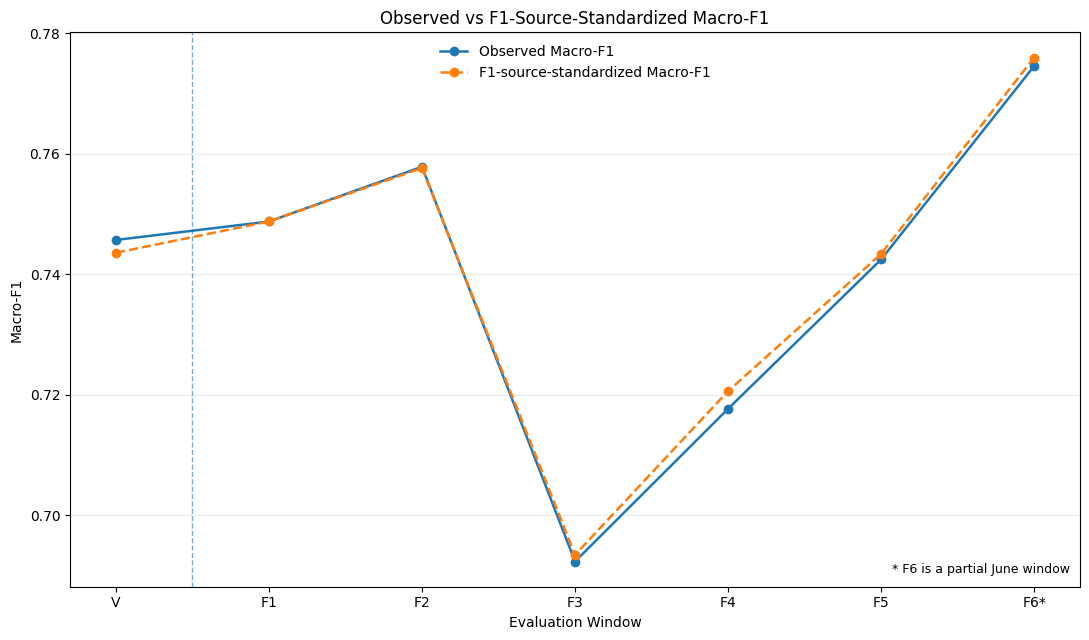

DAY 17 — SOURCE-STANDARDIZATION ARTIFACT + FIGURE
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/source_standardized_performance.csv
Size  : 1,961 bytes

Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/figures/observed_vs_source_standardized_performance.png
Size  : 233,574 bytes
------------------------------------------------------------------------------------------------------------------------
PASS — source_standardized_csv_exists
PASS — source_standardized_csv_nonempty
PASS — source_standardized_rows_7
PASS — reference_coverage_high
PASS — figure_exists
PASS — figure_nonempty
------------------------------------------------------------------------------------------------------------------------
PASS — source_standardized_performance.csv and observed_vs_source_standardized_performance.png created


In [ ]:
# Save source_standardized_performance.csv
# and create observed-vs-standardized performance figure
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

SOURCE_STANDARDIZED_PATH = (
    DAY17_DIR / "source_standardized_performance.csv"
)

SOURCE_STANDARDIZED_FIGURE_PATH = (
    FIGURE_DIR / "observed_vs_source_standardized_performance.png"
)

# ------------------------------------------------------------
# 1. Save artifact
# ------------------------------------------------------------
source_standardized_performance.to_csv(
    SOURCE_STANDARDIZED_PATH,
    index=False,
)

# ------------------------------------------------------------
# 2. Prepare plot
# ------------------------------------------------------------
plot_df = (
    source_standardized_performance
    .set_index("period")
    .reindex(EVAL_PERIOD_ORDER)
    .reset_index()
)

x = np.arange(
    len(EVAL_PERIOD_ORDER)
)

fig, ax = plt.subplots(
    figsize=(11, 6.5)
)

ax.plot(
    x,
    plot_df[
        "observed_macro_f1"
    ].to_numpy(),
    marker="o",
    linewidth=1.8,
    markersize=6,
    label="Observed Macro-F1",
)

ax.plot(
    x,
    plot_df[
        "source_standardized_macro_f1"
    ].to_numpy(),
    marker="o",
    linewidth=1.8,
    markersize=6,
    linestyle="--",
    label="F1-source-standardized Macro-F1",
)

# Historical / future separator
ax.axvline(
    x=0.5,
    linestyle="--",
    linewidth=1,
    alpha=0.6,
)

ax.set_xticks(x)

ax.set_xticklabels([
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6*",
])

ax.set_xlabel(
    "Evaluation Window"
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_title(
    "Observed vs F1-Source-Standardized Macro-F1"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

ax.legend(
    frameon=False
)

# F6 caveat
ax.text(
    0.99,
    0.02,
    "* F6 is a partial June window",
    transform=ax.transAxes,
    ha="right",
    va="bottom",
    fontsize=9,
)

fig.tight_layout()

fig.savefig(
    SOURCE_STANDARDIZED_FIGURE_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# 3. Verify artifact + figure
# ------------------------------------------------------------
csv_exists = (
    SOURCE_STANDARDIZED_PATH.exists()
)

csv_size = (
    SOURCE_STANDARDIZED_PATH.stat().st_size
    if csv_exists
    else 0
)

figure_exists = (
    SOURCE_STANDARDIZED_FIGURE_PATH.exists()
)

figure_size = (
    SOURCE_STANDARDIZED_FIGURE_PATH.stat().st_size
    if figure_exists
    else 0
)

checks = {
    "source_standardized_csv_exists":
        csv_exists,

    "source_standardized_csv_nonempty":
        csv_size > 0,

    "source_standardized_rows_7":
        len(
            source_standardized_performance
        ) == 7,

    "reference_coverage_high":
        bool(
            (
                source_standardized_performance[
                    "reference_weight_coverage"
                ]
                >= 0.995
            ).all()
        ),

    "figure_exists":
        figure_exists,

    "figure_nonempty":
        figure_size > 0,
}

print("=" * 120)
print("DAY 17 — SOURCE-STANDARDIZATION ARTIFACT + FIGURE")
print("=" * 120)

print(
    f"Saved : {SOURCE_STANDARDIZED_PATH}"
)
print(
    f"Size  : {csv_size:,} bytes"
)

print(
    f"\nSaved : {SOURCE_STANDARDIZED_FIGURE_PATH}"
)
print(
    f"Size  : {figure_size:,} bytes"
)

print("-" * 120)

for name, status in checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s}"
        f" — {name}"
    )

print("-" * 120)

if not all(
    checks.values()
):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Source-standardization artifact/figure checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — source_standardized_performance.csv and "
    "observed_vs_source_standardized_performance.png created"
)

print("=" * 120)

In [ ]:
# ============================================================
# DAY 17 — CELL 36
# Stage F final checkpoint
# ============================================================

STAGE_F_REQUIRED_ARTIFACTS = {
    "source_performance.csv":
        SOURCE_PERFORMANCE_PATH,

    "source_shift_diagnostics.csv":
        SOURCE_SHIFT_DIAGNOSTICS_PATH,

    "source_standardized_performance.csv":
        SOURCE_STANDARDIZED_PATH,

    "observed_vs_source_standardized_performance.png":
        SOURCE_STANDARDIZED_FIGURE_PATH,
}

print("=" * 120)
print("DAY 17 — STAGE F FINAL CHECKPOINT")
print("=" * 120)

artifact_checks = {}

for name, path in STAGE_F_REQUIRED_ARTIFACTS.items():

    exists = path.exists()

    size = (
        path.stat().st_size
        if exists
        else 0
    )

    artifact_checks[name] = (
        exists and size > 0
    )

    print(
        f"{'PASS' if artifact_checks[name] else 'FAIL':4s}"
        f" — {name:<50s}"
        f"{size:>12,} bytes"
    )

print("-" * 120)

# ------------------------------------------------------------
# Key diagnostic quantities
# ------------------------------------------------------------
f3_standardized = (
    source_standardized_performance.loc[
        source_standardized_performance[
            "period"
        ] == "F3"
    ]
    .iloc[0]
)

f4_standardized = (
    source_standardized_performance.loc[
        source_standardized_performance[
            "period"
        ] == "F4"
    ]
    .iloc[0]
)

f3_source_mix_effect = float(
    f3_standardized[
        "standardized_minus_observed_macro_f1"
    ]
)

f4_source_mix_effect = float(
    f4_standardized[
        "standardized_minus_observed_macro_f1"
    ]
)

stage_f_checks = {
    "source_performance_rows_56":
        len(
            source_performance_export
        ) == 56,

    "eight_sources_retained":
        source_performance_export[
            "source"
        ].nunique() == 8,

    "support_threshold_50":
        SOURCE_SUPPORT_THRESHOLD == 50,

    "dominant_source_firstsquaw":
        dominant_source == "firstsquaw",

    "stable_within_source_contrast_available":
        len(
            source_within_source_contrast
        ) > 0,

    "source_standardization_rows_7":
        len(
            source_standardized_performance
        ) == 7,

    "standardization_reference_F1":
        set(
            source_standardized_performance[
                "reference_distribution"
            ]
        ) == {
            "F1_source_shares"
        },

    "reference_weight_coverage_high":
        bool(
            (
                source_standardized_performance[
                    "reference_weight_coverage"
                ]
                >= 0.995
            ).all()
        ),

    "all_stage_F_artifacts_present":
        all(
            artifact_checks.values()
        ),
}

for name, status in stage_f_checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s}"
        f" — {name}"
    )

print("-" * 120)

print(
    "F3 standardized-minus-observed Macro-F1:"
    f" {f3_source_mix_effect:+.6f}"
)

print(
    "F4 standardized-minus-observed Macro-F1:"
    f" {f4_source_mix_effect:+.6f}"
)

print("-" * 120)

if not all(
    stage_f_checks.values()
):

    failed = [
        name
        for name, status in stage_f_checks.items()
        if not status
    ]

    raise AssertionError(
        "Stage F final checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — STAGE F SOURCE COMPOSITION AND "
    "SOURCE-CONDITIONAL DIAGNOSIS COMPLETE"
)

print("=" * 120)

DAY 17 — STAGE F FINAL CHECKPOINT
PASS — source_performance.csv                                   8,962 bytes
PASS — source_shift_diagnostics.csv                             2,129 bytes
PASS — source_standardized_performance.csv                      1,961 bytes
PASS — observed_vs_source_standardized_performance.png        233,574 bytes
------------------------------------------------------------------------------------------------------------------------
PASS — source_performance_rows_56
PASS — eight_sources_retained
PASS — support_threshold_50
PASS — dominant_source_firstsquaw
PASS — stable_within_source_contrast_available
PASS — source_standardization_rows_7
PASS — standardization_reference_F1
PASS — reference_weight_coverage_high
PASS — all_stage_F_artifacts_present
------------------------------------------------------------------------------------------------------------------------
F3 standardized-minus-observed Macro-F1: +0.001096
F4 standardized-minus-observed Macro-F1: +0.0029

## Stage G — Adjusted Association Analysis Decision

Stage G was not required for the primary Day 17 diagnosis.

The descriptive evidence from Stages B–F already separates the main observable components of the temporal pattern:

- bootstrap uncertainty confirms the F3/F4 performance dips relative to V and F1;
- class-level decomposition shows that F3 is strongly concentrated in the positive class;
- transition analysis identifies large F3 increases in positive → negative and positive → neutral errors;
- F3 also exhibits substantial true-label and prediction-composition shift;
- source composition changes across windows, but F1-source standardization changes F3 Macro-F1 only minimally;
- performance degradation remains within dominant and stable sources, especially firstsquaw and WalterBloomberg.

Therefore, an additional observation-level adjusted logistic model would add modeling assumptions without being necessary to resolve the primary descriptive diagnosis.

Stage G is deferred rather than interpreted as evidence of a “pure time effect.” Any future adjusted analysis would remain associative and would not identify elapsed time as causal.

In [ ]:
# Integrated diagnostic evidence matrix
# Uses confirmed Stage B/C/D schemas.

import numpy as np
import pandas as pd

KEY_DIAGNOSTIC_WINDOWS = [
    "F3",
    "F4",
    "F5",
    "F6",
]


# ------------------------------------------------------------
# 1. Macro-F1 point estimate + bootstrap CI
# ------------------------------------------------------------
macro_ci_lookup = (
    period_metric_uncertainty.loc[
        period_metric_uncertainty["metric"] == "macro_f1",
        [
            "period",
            "point_estimate",
            "ci_lower_95",
            "ci_upper_95",
        ],
    ]
    .set_index("period")
    .reindex(EVAL_PERIOD_ORDER)
)


# ------------------------------------------------------------
# 2. Macro-F1 delta vs F1 + bootstrap CI
# ------------------------------------------------------------
macro_delta_f1_lookup = (
    macro_f1_delta_uncertainty.loc[
        (
            macro_f1_delta_uncertainty[
                "reference_period"
            ] == "F1"
        )
        &
        (
            macro_f1_delta_uncertainty[
                "metric"
            ] == "macro_f1"
        ),
        [
            "period",
            "point_delta",
            "ci_lower_95",
            "ci_upper_95",
            "ci_excludes_zero",
        ],
    ]
    .set_index("period")
)


# ------------------------------------------------------------
# 3. Other diagnostic lookups
# ------------------------------------------------------------
composition_lookup = (
    composition_window_summary
    .set_index("period")
)

source_shift_lookup = (
    source_shift_diagnostics
    .set_index("period")
)

source_standardized_lookup = (
    source_standardized_performance
    .set_index("period")
)


# ------------------------------------------------------------
# 4. Largest class-level contributor vs F1
# ------------------------------------------------------------
class_contribution_lookup = {}

for period in KEY_DIAGNOSTIC_WINDOWS:

    d = (
        class_diagnostic_summary.loc[
            class_diagnostic_summary[
                "period"
            ] == period
        ]
        .copy()
    )

    if len(d) == 0:
        raise AssertionError(
            f"No class diagnostics found for {period}."
        )

    # Confirmed Stage C column name:
    # macro_f1_contribution_vs_F1
    d[
        "abs_contribution_vs_F1"
    ] = (
        d[
            "macro_f1_contribution_vs_F1"
        ].abs()
    )

    row = (
        d.sort_values(
            "abs_contribution_vs_F1",
            ascending=False,
        )
        .iloc[0]
    )

    class_contribution_lookup[
        period
    ] = {
        "largest_class_contributor":
            row["class"],

        "largest_class_f1_change_vs_F1":
            float(
                row[
                    "f1_change_vs_F1"
                ]
            ),

        "largest_class_macro_f1_contribution":
            float(
                row[
                    "macro_f1_contribution_vs_F1"
                ]
            ),
    }


# ------------------------------------------------------------
# 5. Largest error-transition signals vs F1
# ------------------------------------------------------------
transition_lookup = {}

for period in KEY_DIAGNOSTIC_WINDOWS:

    d = (
        transition_diagnostic_summary.loc[
            transition_diagnostic_summary[
                "period"
            ] == period
        ]
        .copy()
    )

    # Keep error transitions only
    d = d.loc[
        d[
            "transition_type"
        ] == "error"
    ]

    if len(d) == 0:
        raise AssertionError(
            f"No error-transition diagnostics found for {period}."
        )

    # Largest increase in conditional error rate
    row_rate = (
        d.sort_values(
            "conditional_rate_change_vs_F1",
            ascending=False,
        )
        .iloc[0]
    )

    # Largest positive excess error count
    row_count = (
        d.sort_values(
            "excess_count_vs_F1_rate",
            ascending=False,
        )
        .iloc[0]
    )

    transition_lookup[
        period
    ] = {
        "largest_transition_rate_increase":
            row_rate[
                "transition"
            ],

        "largest_transition_rate_change_vs_F1":
            float(
                row_rate[
                    "conditional_rate_change_vs_F1"
                ]
            ),

        "largest_excess_error_transition":
            row_count[
                "transition"
            ],

        "largest_excess_error_count_vs_F1":
            float(
                row_count[
                    "excess_count_vs_F1_rate"
                ]
            ),
    }


# ------------------------------------------------------------
# 6. Dominant-source within-source contrast lookup
# ------------------------------------------------------------
dominant_contrast_lookup = (
    dominant_source_contrast
    .set_index("period")
)


# ------------------------------------------------------------
# 7. Build evidence rows
# ------------------------------------------------------------
evidence_rows = []

for period in KEY_DIAGNOSTIC_WINDOWS:

    macro_row = (
        macro_ci_lookup.loc[
            period
        ]
    )

    delta_row = (
        macro_delta_f1_lookup.loc[
            period
        ]
    )

    comp_row = (
        composition_lookup.loc[
            period
        ]
    )

    source_row = (
        source_shift_lookup.loc[
            period
        ]
    )

    standardized_row = (
        source_standardized_lookup.loc[
            period
        ]
    )

    class_info = (
        class_contribution_lookup[
            period
        ]
    )

    transition_info = (
        transition_lookup[
            period
        ]
    )

    # --------------------------------------------------------
    # Dominant-source movement
    # --------------------------------------------------------
    if period in dominant_contrast_lookup.index:

        dominant_row = (
            dominant_contrast_lookup.loc[
                period
            ]
        )

        dominant_macro_change = float(
            dominant_row[
                "macro_f1_change_vs_F1"
            ]
        )

        dominant_positive_recall_change = float(
            dominant_row[
                "positive_recall_change_vs_F1"
            ]
        )

    else:

        # F6 was not included in the Cell 32
        # F1/F3/F4/F5 stable-source contrast.
        dominant_macro_change = float(
            source_row[
                "dominant_source_macro_f1_change_vs_F1"
            ]
        )

        dominant_positive_recall_change = float(
            source_row[
                "dominant_source_positive_recall_change_vs_F1"
            ]
        )

    evidence_rows.append({
        # ----------------------------------------------------
        # Window identity
        # ----------------------------------------------------
        "period":
            period,

        "window_role":
            {
                "F3":
                    "primary_dip",

                "F4":
                    "incomplete_recovery",

                "F5":
                    "substantial_recovery",

                "F6":
                    "partial_window_rebound",
            }[period],

        # ----------------------------------------------------
        # Aggregate uncertainty
        # ----------------------------------------------------
        "macro_f1":
            float(
                macro_row[
                    "point_estimate"
                ]
            ),

        "macro_f1_ci_lower_95":
            float(
                macro_row[
                    "ci_lower_95"
                ]
            ),

        "macro_f1_ci_upper_95":
            float(
                macro_row[
                    "ci_upper_95"
                ]
            ),

        "macro_f1_change_vs_F1":
            float(
                delta_row[
                    "point_delta"
                ]
            ),

        "macro_f1_delta_ci_lower_95":
            float(
                delta_row[
                    "ci_lower_95"
                ]
            ),

        "macro_f1_delta_ci_upper_95":
            float(
                delta_row[
                    "ci_upper_95"
                ]
            ),

        "macro_f1_delta_ci_excludes_zero":
            bool(
                delta_row[
                    "ci_excludes_zero"
                ]
            ),

        # ----------------------------------------------------
        # Class decomposition
        # ----------------------------------------------------
        "largest_class_contributor":
            class_info[
                "largest_class_contributor"
            ],

        "largest_class_f1_change_vs_F1":
            float(
                class_info[
                    "largest_class_f1_change_vs_F1"
                ]
            ),

        "largest_class_macro_f1_contribution":
            float(
                class_info[
                    "largest_class_macro_f1_contribution"
                ]
            ),

        # ----------------------------------------------------
        # Error-transition decomposition
        # ----------------------------------------------------
        "largest_transition_rate_increase":
            transition_info[
                "largest_transition_rate_increase"
            ],

        "largest_transition_rate_change_vs_F1":
            float(
                transition_info[
                    "largest_transition_rate_change_vs_F1"
                ]
            ),

        "largest_excess_error_transition":
            transition_info[
                "largest_excess_error_transition"
            ],

        "largest_excess_error_count_vs_F1":
            float(
                transition_info[
                    "largest_excess_error_count_vs_F1"
                ]
            ),

        # ----------------------------------------------------
        # Label / prediction composition
        # ----------------------------------------------------
        "true_label_tvd_vs_F1":
            float(
                comp_row[
                    "true_tvd_vs_F1"
                ]
            ),

        "predicted_label_tvd_vs_F1":
            float(
                comp_row[
                    "predicted_tvd_vs_F1"
                ]
            ),

        "weighted_minus_macro_f1":
            float(
                comp_row[
                    "weighted_minus_macro_f1"
                ]
            ),

        # ----------------------------------------------------
        # Source diagnostics
        # ----------------------------------------------------
        "source_tvd_vs_F1":
            float(
                source_row[
                    "source_tvd_vs_F1"
                ]
            ),

        "dominant_source":
            str(
                source_row[
                    "dominant_source"
                ]
            ),

        "dominant_source_macro_f1_change_vs_F1":
            dominant_macro_change,

        "dominant_source_positive_recall_change_vs_F1":
            dominant_positive_recall_change,

        # ----------------------------------------------------
        # Source-standardization sensitivity
        # ----------------------------------------------------
        "source_standardized_macro_f1":
            float(
                standardized_row[
                    "source_standardized_macro_f1"
                ]
            ),

        "source_standardized_macro_f1_change_vs_F1":
            float(
                standardized_row[
                    "standardized_macro_f1_change_vs_F1"
                ]
            ),

        "standardized_minus_observed_macro_f1":
            float(
                standardized_row[
                    "standardized_minus_observed_macro_f1"
                ]
            ),

        # ----------------------------------------------------
        # Guardrail
        # ----------------------------------------------------
        "partial_window":
            (
                period == "F6"
            ),
    })


day17_diagnostic_evidence = pd.DataFrame(
    evidence_rows
)


# ------------------------------------------------------------
# 8. Explicit ordering
# ------------------------------------------------------------
period_rank = {
    "F3": 0,
    "F4": 1,
    "F5": 2,
    "F6": 3,
}

day17_diagnostic_evidence[
    "_period_order"
] = (
    day17_diagnostic_evidence[
        "period"
    ].map(
        period_rank
    )
)

day17_diagnostic_evidence = (
    day17_diagnostic_evidence
    .sort_values(
        "_period_order"
    )
    .drop(
        columns=[
            "_period_order",
        ]
    )
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 9. Formal checks
# ------------------------------------------------------------
checks = {
    "four_key_windows":
        len(
            day17_diagnostic_evidence
        ) == 4,

    "correct_window_order":
        day17_diagnostic_evidence[
            "period"
        ].tolist()
        == KEY_DIAGNOSTIC_WINDOWS,

    "F3_primary_dip":
        day17_diagnostic_evidence.loc[
            day17_diagnostic_evidence[
                "period"
            ] == "F3",
            "window_role",
        ].iloc[0]
        == "primary_dip",

    "F6_marked_partial":
        bool(
            day17_diagnostic_evidence.loc[
                day17_diagnostic_evidence[
                    "period"
                ] == "F6",
                "partial_window",
            ].iloc[0]
        ),

    "all_macro_CIs_available":
        not day17_diagnostic_evidence[
            [
                "macro_f1_ci_lower_95",
                "macro_f1_ci_upper_95",
                "macro_f1_delta_ci_lower_95",
                "macro_f1_delta_ci_upper_95",
            ]
        ].isna().any().any(),

    "all_class_evidence_available":
        not day17_diagnostic_evidence[
            [
                "largest_class_contributor",
                "largest_class_f1_change_vs_F1",
                "largest_class_macro_f1_contribution",
            ]
        ].isna().any().any(),

    "all_transition_evidence_available":
        not day17_diagnostic_evidence[
            [
                "largest_transition_rate_increase",
                "largest_transition_rate_change_vs_F1",
                "largest_excess_error_transition",
                "largest_excess_error_count_vs_F1",
            ]
        ].isna().any().any(),

    "all_composition_evidence_available":
        not day17_diagnostic_evidence[
            [
                "true_label_tvd_vs_F1",
                "predicted_label_tvd_vs_F1",
                "weighted_minus_macro_f1",
            ]
        ].isna().any().any(),

    "all_source_evidence_available":
        not day17_diagnostic_evidence[
            [
                "source_tvd_vs_F1",
                "dominant_source_macro_f1_change_vs_F1",
                "dominant_source_positive_recall_change_vs_F1",
                "source_standardized_macro_f1",
                "standardized_minus_observed_macro_f1",
            ]
        ].isna().any().any(),
}


# ------------------------------------------------------------
# 10. Display
# ------------------------------------------------------------
print("=" * 210)
print("DAY 17 — INTEGRATED DIAGNOSTIC EVIDENCE MATRIX")
print("=" * 210)

print(
    day17_diagnostic_evidence.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("\n" + "-" * 210)

for name, status in checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s}"
        f" — {name}"
    )

print("-" * 210)

if not all(
    checks.values()
):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Integrated diagnostic evidence matrix failed: "
        + ", ".join(failed)
    )

print(
    "PASS — integrated F3/F4/F5/F6 diagnostic "
    "evidence matrix constructed"
)

print("=" * 210)

DAY 17 — INTEGRATED DIAGNOSTIC EVIDENCE MATRIX
period            window_role  macro_f1  macro_f1_ci_lower_95  macro_f1_ci_upper_95  macro_f1_change_vs_F1  macro_f1_delta_ci_lower_95  macro_f1_delta_ci_upper_95  macro_f1_delta_ci_excludes_zero largest_class_contributor  largest_class_f1_change_vs_F1  largest_class_macro_f1_contribution largest_transition_rate_increase  largest_transition_rate_change_vs_F1 largest_excess_error_transition  largest_excess_error_count_vs_F1  true_label_tvd_vs_F1  predicted_label_tvd_vs_F1  weighted_minus_macro_f1  source_tvd_vs_F1 dominant_source  dominant_source_macro_f1_change_vs_F1  dominant_source_positive_recall_change_vs_F1  source_standardized_macro_f1  source_standardized_macro_f1_change_vs_F1  standardized_minus_observed_macro_f1  partial_window
    F3            primary_dip  0.692346              0.676373              0.708398              -0.056395                   -0.079910                   -0.033271                             True           

In [ ]:

# Save integrated diagnostic evidence matrix

import pandas as pd

DAY17_EVIDENCE_PATH = (
    DAY17_DIR / "day17_diagnostic_evidence.csv"
)

# ------------------------------------------------------------
# 1. Save
# ------------------------------------------------------------
day17_diagnostic_evidence.to_csv(
    DAY17_EVIDENCE_PATH,
    index=False,
)

# ------------------------------------------------------------
# 2. Reload
# ------------------------------------------------------------
reloaded_evidence = pd.read_csv(
    DAY17_EVIDENCE_PATH
)

# ------------------------------------------------------------
# 3. Verify
# ------------------------------------------------------------
evidence_exists = (
    DAY17_EVIDENCE_PATH.exists()
)

evidence_size = (
    DAY17_EVIDENCE_PATH.stat().st_size
    if evidence_exists
    else 0
)

checks = {
    "evidence_file_exists":
        evidence_exists,

    "evidence_file_nonempty":
        evidence_size > 0,

    "four_rows":
        len(
            reloaded_evidence
        ) == 4,

    "correct_period_order":
        reloaded_evidence[
            "period"
        ].tolist()
        == [
            "F3",
            "F4",
            "F5",
            "F6",
        ],

    "F3_delta_CI_excludes_zero":
        bool(
            reloaded_evidence.loc[
                reloaded_evidence[
                    "period"
                ] == "F3",
                "macro_f1_delta_ci_excludes_zero",
            ].iloc[0]
        ),

    "F4_delta_CI_excludes_zero":
        bool(
            reloaded_evidence.loc[
                reloaded_evidence[
                    "period"
                ] == "F4",
                "macro_f1_delta_ci_excludes_zero",
            ].iloc[0]
        ),

    "F5_delta_CI_includes_zero":
        not bool(
            reloaded_evidence.loc[
                reloaded_evidence[
                    "period"
                ] == "F5",
                "macro_f1_delta_ci_excludes_zero",
            ].iloc[0]
        ),

    "F6_partial_window":
        bool(
            reloaded_evidence.loc[
                reloaded_evidence[
                    "period"
                ] == "F6",
                "partial_window",
            ].iloc[0]
        ),

    "no_missing_core_evidence":
        not reloaded_evidence[
            [
                "macro_f1",
                "macro_f1_change_vs_F1",
                "largest_class_contributor",
                "largest_transition_rate_increase",
                "true_label_tvd_vs_F1",
                "source_tvd_vs_F1",
                "source_standardized_macro_f1",
            ]
        ].isna().any().any(),
}

# ------------------------------------------------------------
# 4. Display
# ------------------------------------------------------------
print("=" * 120)
print("DAY 17 — INTEGRATED DIAGNOSTIC EVIDENCE ARTIFACT")
print("=" * 120)

print(
    f"Saved : {DAY17_EVIDENCE_PATH}"
)

print(
    f"Exists: {evidence_exists}"
)

print(
    f"Size  : {evidence_size:,} bytes"
)

print("-" * 120)

for name, status in checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s}"
        f" — {name}"
    )

print("-" * 120)

if not all(
    checks.values()
):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Day 17 integrated diagnostic evidence "
        "artifact checkpoint failed: "
        + ", ".join(failed)
    )

print(
    "PASS — day17_diagnostic_evidence.csv frozen"
)

print("=" * 120)

DAY 17 — INTEGRATED DIAGNOSTIC EVIDENCE ARTIFACT
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/day17_diagnostic_evidence.csv
Exists: True
Size  : 2,625 bytes
------------------------------------------------------------------------------------------------------------------------
PASS — evidence_file_exists
PASS — evidence_file_nonempty
PASS — four_rows
PASS — correct_period_order
PASS — F3_delta_CI_excludes_zero
PASS — F4_delta_CI_excludes_zero
PASS — F5_delta_CI_includes_zero
PASS — F6_partial_window
PASS — no_missing_core_evidence
------------------------------------------------------------------------------------------------------------------------
PASS — day17_diagnostic_evidence.csv frozen


## Stage H — Integrated Diagnostic Interpretation

Day 17 shows that the future temporal curve is **non-monotonic** and that the main performance movements are not explained by a single observable factor.

### F3 — Primary Performance Dip

F3 is the clearest degradation window.

- Macro-F1 falls to **0.6923**, a change of **−0.0564 relative to F1**.
- The bootstrap 95% CI for the F3−F1 Macro-F1 difference is **[−0.0799, −0.0333]**, excluding zero.
- The degradation is strongly concentrated in the **positive class**:
  - positive-class F1 decreases by **−0.1577** relative to F1;
  - its contribution to the aggregate Macro-F1 change is **−0.0526**, accounting for most of the overall decline.
- The largest increase in an error-transition rate is **positive → negative** (**+0.1001** relative to F1), which is also the transition with the largest positive excess error count.
- F3 also has the largest true-label composition shift relative to F1 (**TVD = 0.1716**) and a substantial prediction-distribution shift (**TVD = 0.1270**).
- Source composition changes are present (**source TVD = 0.0406**), but source standardization changes F3 Macro-F1 by only **+0.0011**.
- Within the dominant source, `firstsquaw`, Macro-F1 still falls by **−0.0527** and positive recall by **−0.1635** relative to F1.

Therefore, F3 is best described as a **class-concentrated temporal degradation episode**, particularly affecting positive-class discrimination. Label composition and source composition also change, but the source-standardization sensitivity indicates that source-mix change alone does not account for the aggregate F3 dip.

### F4 — Incomplete Recovery

F4 improves from the F3 minimum but remains below the F1 reference level.

- Macro-F1 is **0.7177**, corresponding to **−0.0311 relative to F1**.
- The bootstrap 95% CI for the difference is **[−0.0544, −0.0109]**, still excluding zero.
- Unlike F3, the remaining degradation is more distributed across classes:
  - the largest class-level contribution comes from the **neutral class**;
  - the largest increase in transition rate is **positive → neutral**;
  - the largest excess error count is associated with **neutral → negative**.
- F4 shows the largest source-composition shift relative to F1 among the main dip/recovery windows (**source TVD = 0.0588**).
- However, fixing the source distribution to the F1 mixture improves Macro-F1 by only **+0.0029**.
- The dominant source also remains below F1, with `firstsquaw` Macro-F1 lower by **−0.0296**.

Thus, F4 represents an **incomplete recovery with a broader error structure than F3**. Source composition contributes descriptively to the window difference, but does not explain most of the remaining performance gap.

### F5 — Substantial Recovery

F5 largely returns toward the F1 performance level.

- Macro-F1 reaches **0.7424**, only **−0.0063 relative to F1**.
- The bootstrap 95% CI for the difference is **[−0.0292, 0.0166]**, which includes zero.
- Residual weakness remains most visible in the positive class, but the magnitude is much smaller than in F3.
- Label, prediction, and source distribution shifts are all reduced relative to the F3/F4 regime.
- The dominant-source Macro-F1 difference relative to F1 is only **−0.0049**.
- Source standardization changes the aggregate Macro-F1 by less than **0.001**.

F5 is therefore interpreted as a **substantial recovery toward the F1 reference regime**, while allowing for modest residual class-specific differences.

### F6 — Partial-Window Rebound

F6 has the highest observed future Macro-F1, but it must be interpreted cautiously.

- Macro-F1 is **0.7745**, or **+0.0258 relative to F1**.
- The bootstrap 95% CI for the difference is **[−0.0164, 0.0670]**, which includes zero.
- The dominant source also performs above its F1 level in this partial window.
- Source standardization leaves the pattern essentially unchanged.

However, F6 contains only **600 observations** and represents a **partial June window**. It should therefore be described as an **apparent partial-window rebound**, not as evidence of a stable upward trend or permanent recovery.

### Integrated Day 17 Interpretation

The Day 16 future curve should not be summarized as monotonic temporal degradation.

Instead, the evidence supports a **localized, non-monotonic temporal performance regime**:

**F1/F2 stable → F3 sharp class-specific degradation → F4 incomplete recovery → F5 substantial recovery → F6 apparent partial-window rebound.**

The strongest diagnostic evidence for the F3 dip comes from the positive class and its associated error transitions. Label composition also changes substantially in F3, while source composition changes more modestly. Source-standardization and within-source analyses show that the main F3 degradation persists even when source-mix differences are reduced.

Accordingly, Day 17 supports a descriptive interpretation of **temporally localized, class-conditional robustness failure under distribution shift**, rather than a simple monotonic decline or a performance change attributable to source composition alone.

These findings remain descriptive and associative. They do not establish elapsed time, source identity, or label composition as causal mechanisms.

In [ ]:
# ============================================================
# DAY 17 — CELL 39
# Final Day 17 scientific summary + artifact manifest
# ============================================================

import json
from pathlib import Path
from datetime import datetime, timezone

DAY17_SUMMARY_PATH = (
    DAY17_DIR / "day17_summary.json"
)

# ------------------------------------------------------------
# 1. Required Day 17 formal artifacts
# ------------------------------------------------------------
formal_artifacts = {
    "day17_input_audit.json":
        DAY17_DIR / "day17_input_audit.json",

    "temporal_metric_uncertainty.csv":
        DAY17_DIR / "temporal_metric_uncertainty.csv",

    "class_diagnostic_summary.csv":
        DAY17_DIR / "class_diagnostic_summary.csv",

    "transition_diagnostic_summary.csv":
        DAY17_DIR / "transition_diagnostic_summary.csv",

    "label_prediction_shift.csv":
        DAY17_DIR / "label_prediction_shift.csv",

    "macro_vs_weighted_gap.csv":
        DAY17_DIR / "macro_vs_weighted_gap.csv",

    "source_performance.csv":
        DAY17_DIR / "source_performance.csv",

    "source_shift_diagnostics.csv":
        DAY17_DIR / "source_shift_diagnostics.csv",

    "source_standardized_performance.csv":
        DAY17_DIR / "source_standardized_performance.csv",

    "day17_diagnostic_evidence.csv":
        DAY17_DIR / "day17_diagnostic_evidence.csv",
}

figure_artifacts = {
    "temporal_macro_f1_ci.png":
        FIGURE_DIR / "temporal_macro_f1_ci.png",

    "class_recall_ci.png":
        FIGURE_DIR / "class_recall_ci.png",

    "class_f1_trajectory.png":
        FIGURE_DIR / "class_f1_trajectory.png",

    "selected_error_transition_trajectories.png":
        FIGURE_DIR / "selected_error_transition_trajectories.png",

    "transition_rate_heatmap.png":
        FIGURE_DIR / "transition_rate_heatmap.png",

    "label_prediction_composition.png":
        FIGURE_DIR / "label_prediction_composition.png",

    "observed_vs_source_standardized_performance.png":
        FIGURE_DIR / "observed_vs_source_standardized_performance.png",
}


# ------------------------------------------------------------
# 2. Artifact status
# ------------------------------------------------------------
formal_artifact_status = {
    name: {
        "exists": path.exists(),
        "size_bytes": (
            path.stat().st_size
            if path.exists()
            else 0
        ),
        "path": str(path),
    }
    for name, path in formal_artifacts.items()
}

figure_artifact_status = {
    name: {
        "exists": path.exists(),
        "size_bytes": (
            path.stat().st_size
            if path.exists()
            else 0
        ),
        "path": str(path),
    }
    for name, path in figure_artifacts.items()
}


# ------------------------------------------------------------
# 3. Key evidence extraction
# ------------------------------------------------------------
evidence_lookup = (
    day17_diagnostic_evidence
    .set_index("period")
)

f3 = evidence_lookup.loc["F3"]
f4 = evidence_lookup.loc["F4"]
f5 = evidence_lookup.loc["F5"]
f6 = evidence_lookup.loc["F6"]


# ------------------------------------------------------------
# 4. Day 17 scientific summary object
# ------------------------------------------------------------
day17_summary = {
    "day":
        17,

    "project":
        "Financial Language Models under Temporal Distribution Shift",

    "status":
        "PASS — TEMPORAL PERFORMANCE DIAGNOSIS COMPLETE",

    "scientific_role":
        (
            "Diagnose the non-monotonic future performance curve "
            "measured on Day 16 without retraining, threshold tuning, "
            "window redefinition, smoothing, or causal attribution."
        ),

    "research_question":
        (
            "What observable class-, error-, composition-, and "
            "source-level factors co-occur with the non-monotonic "
            "future performance pattern, especially the F3 dip "
            "and subsequent recovery?"
        ),

    "analysis_boundary": {
        "model_retrained":
            False,

        "checkpoint_changed":
            False,

        "future_windows_redefined":
            False,

        "threshold_tuned":
            False,

        "temporal_curve_smoothed":
            False,

        "causal_claims_allowed":
            False,

        "stage_G_adjusted_model":
            "deferred_not_required",

        "interpretation_scope":
            (
                "Descriptive and associative diagnosis only. "
                "Elapsed time, source identity, label composition, "
                "and prediction composition are not interpreted "
                "as causal mechanisms."
            ),
    },

    "bootstrap_protocol": {
        "replicates":
            int(BOOTSTRAP_REPLICATES),

        "seed":
            int(BOOTSTRAP_SEED),

        "confidence_level":
            0.95,

        "primary_metric":
            "Macro-F1",

        "secondary_metrics": [
            "Accuracy",
            "negative_recall",
            "neutral_recall",
            "positive_recall",
        ],
    },

    "source_protocol": {
        "source_universe_size":
            int(len(SOURCE_ORDER)),

        "low_support_threshold":
            int(SOURCE_SUPPORT_THRESHOLD),

        "dominant_source":
            str(dominant_source),

        "standardization_reference":
            "F1_source_shares",

        "standardization_interpretation":
            (
                "Descriptive sensitivity analysis only; "
                "not a causal adjustment."
            ),
    },

    "integrated_diagnosis": {
        "overall_pattern":
            (
                "Localized, non-monotonic temporal performance regime: "
                "F1/F2 stable, F3 sharp class-specific degradation, "
                "F4 incomplete recovery, F5 substantial recovery, "
                "F6 apparent partial-window rebound."
            ),

        "F3": {
            "role":
                "primary_dip",

            "macro_f1":
                float(f3["macro_f1"]),

            "macro_f1_change_vs_F1":
                float(
                    f3[
                        "macro_f1_change_vs_F1"
                    ]
                ),

            "delta_ci_95": [
                float(
                    f3[
                        "macro_f1_delta_ci_lower_95"
                    ]
                ),
                float(
                    f3[
                        "macro_f1_delta_ci_upper_95"
                    ]
                ),
            ],

            "delta_ci_excludes_zero":
                bool(
                    f3[
                        "macro_f1_delta_ci_excludes_zero"
                    ]
                ),

            "largest_class_contributor":
                str(
                    f3[
                        "largest_class_contributor"
                    ]
                ),

            "largest_class_f1_change_vs_F1":
                float(
                    f3[
                        "largest_class_f1_change_vs_F1"
                    ]
                ),

            "largest_transition_rate_increase":
                str(
                    f3[
                        "largest_transition_rate_increase"
                    ]
                ),

            "largest_transition_rate_change_vs_F1":
                float(
                    f3[
                        "largest_transition_rate_change_vs_F1"
                    ]
                ),

            "true_label_tvd_vs_F1":
                float(
                    f3[
                        "true_label_tvd_vs_F1"
                    ]
                ),

            "source_tvd_vs_F1":
                float(
                    f3[
                        "source_tvd_vs_F1"
                    ]
                ),

            "dominant_source_macro_f1_change_vs_F1":
                float(
                    f3[
                        "dominant_source_macro_f1_change_vs_F1"
                    ]
                ),

            "source_standardization_effect_on_macro_f1":
                float(
                    f3[
                        "standardized_minus_observed_macro_f1"
                    ]
                ),

            "interpretation":
                (
                    "Class-concentrated degradation dominated by "
                    "positive-class failure and increased "
                    "positive→negative errors. Source mix changes "
                    "are present but explain little of the aggregate dip."
                ),
        },

        "F4": {
            "role":
                "incomplete_recovery",

            "macro_f1":
                float(f4["macro_f1"]),

            "macro_f1_change_vs_F1":
                float(
                    f4[
                        "macro_f1_change_vs_F1"
                    ]
                ),

            "delta_ci_95": [
                float(
                    f4[
                        "macro_f1_delta_ci_lower_95"
                    ]
                ),
                float(
                    f4[
                        "macro_f1_delta_ci_upper_95"
                    ]
                ),
            ],

            "delta_ci_excludes_zero":
                bool(
                    f4[
                        "macro_f1_delta_ci_excludes_zero"
                    ]
                ),

            "largest_class_contributor":
                str(
                    f4[
                        "largest_class_contributor"
                    ]
                ),

            "largest_transition_rate_increase":
                str(
                    f4[
                        "largest_transition_rate_increase"
                    ]
                ),

            "largest_excess_error_transition":
                str(
                    f4[
                        "largest_excess_error_transition"
                    ]
                ),

            "source_tvd_vs_F1":
                float(
                    f4[
                        "source_tvd_vs_F1"
                    ]
                ),

            "source_standardization_effect_on_macro_f1":
                float(
                    f4[
                        "standardized_minus_observed_macro_f1"
                    ]
                ),

            "interpretation":
                (
                    "Partial recovery from F3, but performance remains "
                    "below F1. Residual errors are more distributed "
                    "across classes and transitions than in F3."
                ),
        },

        "F5": {
            "role":
                "substantial_recovery",

            "macro_f1":
                float(f5["macro_f1"]),

            "macro_f1_change_vs_F1":
                float(
                    f5[
                        "macro_f1_change_vs_F1"
                    ]
                ),

            "delta_ci_95": [
                float(
                    f5[
                        "macro_f1_delta_ci_lower_95"
                    ]
                ),
                float(
                    f5[
                        "macro_f1_delta_ci_upper_95"
                    ]
                ),
            ],

            "delta_ci_excludes_zero":
                bool(
                    f5[
                        "macro_f1_delta_ci_excludes_zero"
                    ]
                ),

            "interpretation":
                (
                    "Performance substantially recovers toward the "
                    "F1 reference regime; the Macro-F1 difference "
                    "from F1 is not clearly separated from zero "
                    "under the bootstrap interval."
                ),
        },

        "F6": {
            "role":
                "partial_window_rebound",

            "macro_f1":
                float(f6["macro_f1"]),

            "macro_f1_change_vs_F1":
                float(
                    f6[
                        "macro_f1_change_vs_F1"
                    ]
                ),

            "delta_ci_95": [
                float(
                    f6[
                        "macro_f1_delta_ci_lower_95"
                    ]
                ),
                float(
                    f6[
                        "macro_f1_delta_ci_upper_95"
                    ]
                ),
            ],

            "delta_ci_excludes_zero":
                bool(
                    f6[
                        "macro_f1_delta_ci_excludes_zero"
                    ]
                ),

            "partial_window":
                True,

            "n":
                600,

            "interpretation":
                (
                    "Observed rebound above F1, but the interval "
                    "includes zero and F6 is a partial June window. "
                    "It is not interpreted as stable recovery or "
                    "a persistent upward trend."
                ),
        },
    },

    "completion_flags": {
        "stage_A_input_audit":
            True,

        "stage_B_bootstrap_uncertainty":
            True,

        "stage_C_class_decomposition":
            True,

        "stage_D_error_transition_analysis":
            True,

        "stage_E_label_prediction_composition":
            True,

        "stage_F_source_diagnostics":
            True,

        "stage_F_source_standardization":
            True,

        "stage_G_adjusted_association_model":
            False,

        "stage_G_deferred_by_design":
            True,

        "stage_H_integrated_diagnosis":
            True,

        "stage_I_summary_freeze":
            True,
    },

    "formal_artifact_status":
        formal_artifact_status,

    "figure_artifact_status":
        figure_artifact_status,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),
}


# ------------------------------------------------------------
# 5. Save JSON
# ------------------------------------------------------------
with open(
    DAY17_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        day17_summary,
        f,
        indent=2,
        ensure_ascii=False,
    )


# ------------------------------------------------------------
# 6. Formal validation
# ------------------------------------------------------------
with open(
    DAY17_SUMMARY_PATH,
    "r",
    encoding="utf-8",
) as f:

    reloaded_summary = load_artifact_json(
        f
    )


all_formal_artifacts_ok = all(
    item["exists"]
    and item["size_bytes"] > 0
    for item
    in formal_artifact_status.values()
)

all_figure_artifacts_ok = all(
    item["exists"]
    and item["size_bytes"] > 0
    for item
    in figure_artifact_status.values()
)


checks = {
    "summary_exists":
        DAY17_SUMMARY_PATH.exists(),

    "summary_nonempty":
        (
            DAY17_SUMMARY_PATH.stat().st_size
            > 0
        ),

    "status_pass":
        reloaded_summary[
            "status"
        ].startswith(
            "PASS"
        ),

    "all_formal_artifacts_present":
        all_formal_artifacts_ok,

    "all_figure_artifacts_present":
        all_figure_artifacts_ok,

    "F3_primary_dip_recorded":
        (
            reloaded_summary[
                "integrated_diagnosis"
            ][
                "F3"
            ][
                "role"
            ]
            == "primary_dip"
        ),

    "F6_partial_window_recorded":
        bool(
            reloaded_summary[
                "integrated_diagnosis"
            ][
                "F6"
            ][
                "partial_window"
            ]
        ),

    "no_causal_claim_boundary_recorded":
        (
            reloaded_summary[
                "analysis_boundary"
            ][
                "causal_claims_allowed"
            ]
            is False
        ),

    "stage_G_deferred_recorded":
        (
            reloaded_summary[
                "completion_flags"
            ][
                "stage_G_deferred_by_design"
            ]
            is True
        ),
}


# ------------------------------------------------------------
# 7. Display
# ------------------------------------------------------------
print("=" * 120)
print("DAY 17 — SCIENTIFIC SUMMARY FREEZE")
print("=" * 120)

print(
    f"Saved : {DAY17_SUMMARY_PATH}"
)

print(
    f"Exists: {DAY17_SUMMARY_PATH.exists()}"
)

print(
    f"Size  : {DAY17_SUMMARY_PATH.stat().st_size:,} bytes"
)

print("\n[Formal artifact status]")

for name, status in formal_artifact_status.items():

    passed = (
        status["exists"]
        and status["size_bytes"] > 0
    )

    print(
        f"{'PASS' if passed else 'FAIL':4s}"
        f" — {name:<45s}"
        f"{status['size_bytes']:>12,} bytes"
    )


print("\n[Figure artifact status]")

for name, status in figure_artifact_status.items():

    passed = (
        status["exists"]
        and status["size_bytes"] > 0
    )

    print(
        f"{'PASS' if passed else 'FAIL':4s}"
        f" — {name:<55s}"
        f"{status['size_bytes']:>12,} bytes"
    )


print("\n" + "-" * 120)

for name, status in checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s}"
        f" — {name}"
    )

print("-" * 120)

if not all(
    checks.values()
):

    failed = [
        name
        for name, status in checks.items()
        if not status
    ]

    raise AssertionError(
        "Day 17 scientific summary freeze failed: "
        + ", ".join(failed)
    )

print(
    "PASS — DAY 17 SCIENTIFIC SUMMARY FROZEN"
)

print("=" * 120)

DAY 17 — SCIENTIFIC SUMMARY FREEZE
Saved : /content/drive/MyDrive/FinGPT_Project/results/day17/day17_summary.json
Exists: True
Size  : 8,446 bytes

[Formal artifact status]
PASS — day17_input_audit.json                              4,403 bytes
PASS — temporal_metric_uncertainty.csv                     5,956 bytes
PASS — class_diagnostic_summary.csv                        3,558 bytes
PASS — transition_diagnostic_summary.csv                  10,828 bytes
PASS — label_prediction_shift.csv                          5,438 bytes
PASS — macro_vs_weighted_gap.csv                             655 bytes
PASS — source_performance.csv                              8,962 bytes
PASS — source_shift_diagnostics.csv                        2,129 bytes
PASS — source_standardized_performance.csv                 1,961 bytes
PASS — day17_diagnostic_evidence.csv                       2,625 bytes

[Figure artifact status]
PASS — temporal_macro_f1_ci.png                                    182,328 bytes
PASS — cla

In [ ]:
# ============================================================
# DAY 17 — CELL 40
# Final artifact checkpoint
# ============================================================

import json

# ------------------------------------------------------------
# 1. Required formal artifacts
# ------------------------------------------------------------
required_formal_artifacts = {
    "day17_input_audit.json":
        DAY17_DIR / "day17_input_audit.json",

    "temporal_metric_uncertainty.csv":
        DAY17_DIR / "temporal_metric_uncertainty.csv",

    "class_diagnostic_summary.csv":
        DAY17_DIR / "class_diagnostic_summary.csv",

    "transition_diagnostic_summary.csv":
        DAY17_DIR / "transition_diagnostic_summary.csv",

    "label_prediction_shift.csv":
        DAY17_DIR / "label_prediction_shift.csv",

    "macro_vs_weighted_gap.csv":
        DAY17_DIR / "macro_vs_weighted_gap.csv",

    "source_performance.csv":
        DAY17_DIR / "source_performance.csv",

    "source_shift_diagnostics.csv":
        DAY17_DIR / "source_shift_diagnostics.csv",

    "source_standardized_performance.csv":
        DAY17_DIR / "source_standardized_performance.csv",

    "day17_diagnostic_evidence.csv":
        DAY17_DIR / "day17_diagnostic_evidence.csv",

    "day17_summary.json":
        DAY17_DIR / "day17_summary.json",
}


# ------------------------------------------------------------
# 2. Required figures
# ------------------------------------------------------------
required_figures = {
    "temporal_macro_f1_ci.png":
        FIGURE_DIR / "temporal_macro_f1_ci.png",

    "class_recall_ci.png":
        FIGURE_DIR / "class_recall_ci.png",

    "class_f1_trajectory.png":
        FIGURE_DIR / "class_f1_trajectory.png",

    "selected_error_transition_trajectories.png":
        FIGURE_DIR / "selected_error_transition_trajectories.png",

    "transition_rate_heatmap.png":
        FIGURE_DIR / "transition_rate_heatmap.png",

    "label_prediction_composition.png":
        FIGURE_DIR / "label_prediction_composition.png",

    "observed_vs_source_standardized_performance.png":
        FIGURE_DIR / "observed_vs_source_standardized_performance.png",
}


# ------------------------------------------------------------
# 3. File checks
# ------------------------------------------------------------
formal_checks = {}

for name, path in required_formal_artifacts.items():

    exists = path.exists()

    size = (
        path.stat().st_size
        if exists
        else 0
    )

    formal_checks[name] = {
        "passed":
            exists and size > 0,

        "exists":
            exists,

        "size_bytes":
            size,
    }


figure_checks = {}

for name, path in required_figures.items():

    exists = path.exists()

    size = (
        path.stat().st_size
        if exists
        else 0
    )

    figure_checks[name] = {
        "passed":
            exists and size > 0,

        "exists":
            exists,

        "size_bytes":
            size,
    }


# ------------------------------------------------------------
# 4. Reload final summary
# ------------------------------------------------------------
with open(
    DAY17_SUMMARY_PATH,
    "r",
    encoding="utf-8",
) as f:

    final_summary = load_artifact_json(f)


# ------------------------------------------------------------
# 5. Scientific completion checks
# ------------------------------------------------------------
completion_flags = (
    final_summary[
        "completion_flags"
    ]
)

scientific_checks = {
    "status_is_PASS":
        final_summary[
            "status"
        ].startswith(
            "PASS"
        ),

    "stage_A_complete":
        completion_flags[
            "stage_A_input_audit"
        ] is True,

    "stage_B_complete":
        completion_flags[
            "stage_B_bootstrap_uncertainty"
        ] is True,

    "stage_C_complete":
        completion_flags[
            "stage_C_class_decomposition"
        ] is True,

    "stage_D_complete":
        completion_flags[
            "stage_D_error_transition_analysis"
        ] is True,

    "stage_E_complete":
        completion_flags[
            "stage_E_label_prediction_composition"
        ] is True,

    "stage_F_complete":
        completion_flags[
            "stage_F_source_diagnostics"
        ] is True,

    "source_standardization_complete":
        completion_flags[
            "stage_F_source_standardization"
        ] is True,

    "stage_G_deferred_by_design":
        completion_flags[
            "stage_G_deferred_by_design"
        ] is True,

    "stage_H_complete":
        completion_flags[
            "stage_H_integrated_diagnosis"
        ] is True,

    "stage_I_summary_frozen":
        completion_flags[
            "stage_I_summary_freeze"
        ] is True,

    "causal_claims_prohibited":
        final_summary[
            "analysis_boundary"
        ][
            "causal_claims_allowed"
        ] is False,

    "F3_primary_dip":
        final_summary[
            "integrated_diagnosis"
        ][
            "F3"
        ][
            "role"
        ] == "primary_dip",

    "F6_partial_window":
        final_summary[
            "integrated_diagnosis"
        ][
            "F6"
        ][
            "partial_window"
        ] is True,
}


# ------------------------------------------------------------
# 6. Global checkpoint
# ------------------------------------------------------------
all_formal_pass = all(
    item["passed"]
    for item in formal_checks.values()
)

all_figures_pass = all(
    item["passed"]
    for item in figure_checks.values()
)

all_scientific_pass = all(
    scientific_checks.values()
)


# ------------------------------------------------------------
# 7. Display
# ------------------------------------------------------------
print("=" * 120)
print("DAY 17 — FINAL ARTIFACT CHECKPOINT")
print("=" * 120)

print("\n[REQUIRED FORMAL ARTIFACTS]")

for name, item in formal_checks.items():

    print(
        f"{'PASS' if item['passed'] else 'FAIL':4s}"
        f" — {name:<45s}"
        f"{item['size_bytes']:>12,} bytes"
    )


print("\n[REQUIRED FIGURES]")

for name, item in figure_checks.items():

    print(
        f"{'PASS' if item['passed'] else 'FAIL':4s}"
        f" — {name:<55s}"
        f"{item['size_bytes']:>12,} bytes"
    )


print("\n[SCIENTIFIC COMPLETION FLAGS]")

for name, status in scientific_checks.items():

    print(
        f"{'PASS' if status else 'FAIL':4s}"
        f" — {name}"
    )


print("\n" + "-" * 120)

print(
    f"{'PASS' if all_formal_pass else 'FAIL':4s}"
    " — all_required_formal_artifacts"
)

print(
    f"{'PASS' if all_figures_pass else 'FAIL':4s}"
    " — all_required_figures"
)

print(
    f"{'PASS' if all_scientific_pass else 'FAIL':4s}"
    " — all_scientific_completion_flags"
)

print("-" * 120)


if not (
    all_formal_pass
    and all_figures_pass
    and all_scientific_pass
):

    raise AssertionError(
        "Day 17 final artifact checkpoint failed."
    )


print()
print(
    "DAY 17 FINAL STATUS:"
)

print(
    "PASS — TEMPORAL PERFORMANCE DIAGNOSIS COMPLETE"
)

print("=" * 120)

DAY 17 — FINAL ARTIFACT CHECKPOINT

[REQUIRED FORMAL ARTIFACTS]
PASS — day17_input_audit.json                              4,403 bytes
PASS — temporal_metric_uncertainty.csv                     5,956 bytes
PASS — class_diagnostic_summary.csv                        3,558 bytes
PASS — transition_diagnostic_summary.csv                  10,828 bytes
PASS — label_prediction_shift.csv                          5,438 bytes
PASS — macro_vs_weighted_gap.csv                             655 bytes
PASS — source_performance.csv                              8,962 bytes
PASS — source_shift_diagnostics.csv                        2,129 bytes
PASS — source_standardized_performance.csv                 1,961 bytes
PASS — day17_diagnostic_evidence.csv                       2,625 bytes
PASS — day17_summary.json                                  8,446 bytes

[REQUIRED FIGURES]
PASS — temporal_macro_f1_ci.png                                    182,328 bytes
PASS — class_recall_ci.png                            